Input: a text in Ukrainian, Russian or mixed code, usually a Telegram post. Output: a list of location strings exactly as written in the text. Locations are cities, countries, regions, districts, streets and addresses, and other geographic objects. For example, `Сьогодні з Києва до Хелма вперше вирушив новий поїзд` should return `["Києва", "Хелма"]`. Scoring is F1 over sets of strings.


## What we work with

| File | What it is | Size | Labels |
|---|---|---|---|
| `uk_geo_dataset.csv` | news sentences, Ukr-Synth corpus | 1.01M | machine LOC/ORG/PER spans |
| `ru_geo_dataset.csv` | Lenta.ru news sentences, Nerus corpus | 8.03M | machine LOC/ORG/PER spans |
| `uk_geo_dataset_processed_v1.parquet` | tokens of the same uk corpus | 1.01M | flat O/LOC, no B/I |
| `labeling_sample.csv` | Telegram posts | 26 | manual |
| `test.csv` | Telegram posts | 477 | none |

Train is large, but it is news with machine labels. We are scored on Telegram, and only 26 posts have manual labels.

In [1]:
import ast, json, re, string, unicodedata
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd

DATA = Path("../data")
pd.set_option("display.max_colwidth", 120, "display.max_rows", 100)

In [2]:
# Official metric of cometition
def hard_processing(text):
    text = re.sub(r"[{re.escape(string.punctuation)}]", "", text)
    text = re.sub(r"\d", "", text)
    text = re.sub(r"\b\w\b\s?", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text.lower()


def comp_metric(y_true, y_pred):
    assert len(y_true) == len(y_pred)
    tp, fp, fn, p = 0.0, 0.0, 0.0, 0.0
    for y_true_sample, y_pred_sample in zip(y_true, y_pred):
        y_true_sample = {hard_processing(s) for s in y_true_sample}
        y_pred_sample = {hard_processing(s) for s in y_pred_sample}
        tp += len(y_true_sample & y_pred_sample)
        fp += len(y_pred_sample - y_true_sample)
        fn += len(y_true_sample - y_pred_sample)
        p += len(y_true_sample)
    precision = tp / (tp + fp) if tp + fp else float(p == 0)
    recall = tp / (tp + fn) if tp + fn else float(p == 0)
    return round(2 * precision * recall / (precision + recall), 8) if precision + recall else 0

In [2]:
TOKEN = re.compile(r"\w+(?:['’ʼ]\w+)*|[^\w\s]")
SPAN = re.compile(r"\((\d+),\s*(\d+)\)")


def parse_spans(value):
    return [(int(a), int(b)) for a, b in SPAN.findall(str(value))]


def tokenize(text):
    return [m.span() for m in TOKEN.finditer(text)]


def clean_spans(text, spans):
    # Merges spans that touch or overlap (a name marked in pieces: Івано + - + Франківськ),
    # trims edge whitespace and drops spans without letters. It never splits a span.
    merged = []
    for a, b in sorted(spans):
        if merged and a <= merged[-1][1]:
            merged[-1] = (merged[-1][0], max(b, merged[-1][1]))
        else:
            merged.append((a, b))
    cleaned = []
    for a, b in merged:
        chunk = text[a:b]
        a, b = a + len(chunk) - len(chunk.lstrip()), b - (len(chunk) - len(chunk.rstrip()))
        if a < b and any(c.isalnum() for c in text[a:b]):
            cleaned.append((a, b))
    return cleaned


def spans_to_bio(offsets, spans):
    tags, misaligned = ["O"] * len(offsets), 0
    for a, b in spans:
        hit = [i for i, (s, e) in enumerate(offsets) if s < b and a < e]
        if not hit or offsets[hit[0]][0] != a or offsets[hit[-1]][1] != b:
            misaligned += 1
        if hit:
            tags[hit[0]] = "B"
            for i in hit[1:]:
                tags[i] = "I"
    return tags, misaligned


def bio_to_strings(text, offsets, tags, merge_adjacent=False):
    out, i = [], 0
    while i < len(tags):
        if tags[i] == "O":
            i += 1
            continue
        j = i + 1
        while j < len(tags) and (tags[j] == "I" or (merge_adjacent and tags[j] != "O")):
            j += 1
        out.append(text[offsets[i][0]:offsets[j - 1][1]])
        i = j
    return out


def normalize_text(text):
    text = unicodedata.normalize("NFKC", text)
    return re.sub(r"\W+", " ", text.lower()).strip()


def normalised_loc_signature(text, spans):
    signature, empty_spans = [], 0
    for a, b in spans:
        assert 0 <= a < b <= len(text)
        entity = normalize_text(text[a:b])
        if entity:
            signature.append((normalize_text(text[:a]), entity, normalize_text(text[b:])))
        else:
            empty_spans += 1
    return tuple(sorted(signature)), empty_spans


assert normalize_text("Київ") == normalize_text("Київ")
assert normalised_loc_signature("Київ", [(0, 5)]) == normalised_loc_signature("Київ", [(0, 4)])
assert normalised_loc_signature("Київ Київ", [(0, 4)]) != normalised_loc_signature("Київ Київ", [(5, 9)])


## 1. Дані та їхня якість


In [4]:
from IPython.display import display

uk = pd.read_csv(DATA / "uk_geo_dataset.csv")
test = pd.read_csv(DATA / "test.csv")
sample = pd.read_csv(DATA / "labeling_sample.csv")
pd.DataFrame({
    name: {"рядків": len(frame), "колонки": ", ".join(frame.columns)}
    for name, frame in {"uk": uk, "test": test, "labeling_sample": sample}.items()
}).T

,рядків,колонки
uk,1010000,"text, loc_markers, org_markers, per_markers, is_valid"
test,477,"text_id, text, locations"
labeling_sample,26,"text, locations, loc_markers"


| Колонка | Опис |
|---|---|
| `text` | Текст, у якому потрібно знайти локації. |
| `loc_markers` | Список координат локацій у тексті: `(початок, кінець)`.|
| `org_markers` | Координати згадок організацій.|
| `per_markers` | Координати згадок людей. |
| `locations` | Список локацій словами, наприклад `["Проспект Бандери"]`. У `labeling_sample.csv` це надані відповіді. У `test.csv` всі значення `[]` — порожні заготовки для прогнозів, а не позначка відсутності локацій. |
| `is_valid` | Позначка поділу українського датасету: `0` — навчання, `1` — валідація. |
| `text_id` | Ідентифікатор тексту в test, за яким можна зіставити текст із прогнозом моделі. |

**Що таке ru dataset?**

`ru_geo_dataset.csv` — російськомовні новинні речення з розміткою сутностей. За описом у `data/README.md`, набір сформований на основі Nerus. Один рядок — одне речення.

| Колонка | Що містить |
|---|---|
| `text` | Саме речення. |
| `loc_markers` | Координати згадок локацій у реченні. |
| `doc_id` | Ідентифікатор документа, з якого взято речення. |
| `sent_id` | Номер речення всередині документа. |

У CSV також є `org_markers` і `per_markers` — координати організацій та людей. Для поточного аналізу локацій завантажуємо чотири колонки з таблиці.


In [5]:
ru = pd.read_csv(DATA / "ru_geo_dataset.csv", usecols=["text", "loc_markers", "doc_id", "sent_id"])
ru_docs = ru.doc_id.to_numpy()
pd.Series({"рядків ru": len(ru), "документів": ru.doc_id.nunique()}).to_frame("кількість")


,кількість
рядків ru,8028840
документів,739190


loc_markers - Nan, text - not nan, or via verca

In [6]:
display(pd.DataFrame({
    name: frame[["text", "loc_markers"]].isna().sum()
    for name, frame in {"uk": uk, "ru": ru, "labeling_sample": sample}.items()
}).T)
print("Пропуски text у test:", int(test.text.isna().sum()))

,text,loc_markers
uk,0,0
ru,0,0
labeling_sample,0,0


Пропуски text у test: 0


такого немає

**Місце в тексті є, але `loc_markers` дорівнює `[]`: як це виглядає?**

In [ ]:
unmarked_examples = pd.concat([
    uk.loc[[420657], ["text", "loc_markers"]].assign(dataset="uk", row_id=420657),
    ru.loc[[1748213], ["text", "loc_markers"]].assign(dataset="ru", row_id=1748213),
], ignore_index=True)
unmarked_examples["згадки без LOC-мітки"] = [["києві"], ["Москвы", "Санкт-Петербурга"]]

# These examples precede parsing: loc_markers still contains the original CSV strings.
assert unmarked_examples.loc_markers.eq("[]").all()
assert not unmarked_examples[["text", "loc_markers"]].isna().any().any()
assert all(place in text for text, places in zip(unmarked_examples.text, unmarked_examples["згадки без LOC-мітки"]) for place in places)
with pd.option_context("display.max_colwidth", None):
    display(unmarked_examples[["dataset", "row_id", "text", "loc_markers", "згадки без LOC-мітки"]])


,dataset,row_id,text,loc_markers,згадки без LOC-мітки
0,uk,420657,Півзахисник Шахтаря Тарас Степаненко прокоментував ситуацію з пошуком житла у києві працівниками клубу.,[],[києві]
1,ru,1748213,"Фанаты из Москвы, Санкт-Петербурга и других городов будут на одной стороне.",[],"[Москвы, Санкт-Петербурга]"


Отже, нам треба дорозмітити такі варіанти в тренувальному наборі


Координати локацій

In [7]:
for frame, column in [(uk, "loc_markers"), (uk, "org_markers"), (ru, "loc_markers"), (sample, "loc_markers")]:
    frame[column] = frame[column].map(parse_spans)
sample["locations"] = sample["locations"].map(ast.literal_eval)
row = sample[sample.loc_markers.map(bool)].iloc[0]
pd.DataFrame({"координати": row.loc_markers, "текст спану": [row.text[a:b] for a, b in row.loc_markers]})

,координати,текст спану
0,"(0, 16)",Проспект Бандери


Текст:    К и ї в !
Позиція:  0 1 2 3 4

a — позиція першого символу локації, а b — позиція одразу після її останнього символу.

**Чи виходять розібрані спани за межі тексту?**

Для кожного LOC-спану перевіряємо `0 ≤ початок < кінець ≤ довжина тексту`.

In [8]:
span_bounds = pd.DataFrame({
    name: {
        "спанів": int(frame.loc_markers.map(len).sum()),
        "недопустимі координати": sum(not (0 <= a < b <= len(text)) for text, spans in zip(frame.text, frame.loc_markers) for a, b in spans),
    }
    for name, frame in {"uk": uk, "ru": ru, "labeling_sample": sample}.items()
}).T
display(span_bounds)
assert span_bounds["недопустимі координати"].eq(0).all()

,спанів,недопустимі координати
uk,345114,0
ru,3708173,0
labeling_sample,32,0


Усі координати вказують на непорожні фрагменти всередині тексту.

**Які підозрілі межі є в розмітці?**

`no_letters_or_digits` — спан без букв і цифр; `edge_space_or_punct` — пробіл або пунктуація на краю; `mid_word_boundary` — межа всередині слова. Рахуємо ці ознаки окремо, бо вони можуть перетинатися.

In [9]:
def marker_defects(df):
    c = Counter()
    for text, spans in zip(df["text"], df["loc_markers"]):
        for a, b in spans:
            s = text[a:b]
            c["spans"] += 1
            c["no_letters_or_digits"] += not any(ch.isalnum() for ch in s)
            c["edge_space_or_punct"] += not (s[0].isalnum() and s[-1].isalnum())
            c["mid_word_boundary"] += (a > 0 and text[a - 1].isalnum() and s[0].isalnum()) or (b < len(text) and text[b].isalnum() and s[-1].isalnum())
    return c


defects = pd.DataFrame({"uk": marker_defects(uk), "ru": marker_defects(ru), "sample": marker_defects(sample)}).fillna(0).astype(int)
defects

,uk,ru,sample
spans,345114,3708173,32
no_letters_or_digits,1057,50,0
edge_space_or_punct,5364,16792,0
mid_word_boundary,1516,7712,1


В uk є 1 057 спанів без букв і цифр, 5 364 із пробілами або пунктуацією на краях та 1 516 із межею всередині слова. У повному ru відповідні числа — 50, 16 792 та 7 712. 
Треба їх дослідити на предмет перерозмітки

**Перевіряє фунцію `clean_spans` із розміткою?**

Функція виконує три дії:
- Об’єднує фрагменти, які перекриваються або стоять впритул без проміжку. Наприклад, три мітки `Івано`, `-`, `Франківськ` можуть стати однією: `Івано-Франківськ`.
- Прибирає пробіли на початку й у кінці виділеного фрагмента, зсуваючи його координати: ` Київ ` → `Київ`.
- Відкидає окрему мітку, якщо після об’єднання в ній немає букв і цифр, наприклад мітку лише на дефісі `-`.

Потім порівнюємо кількість спанів до й після та рахуємо тексти, де змінилися координати або кількість міток. 

In [10]:
uk["spans"] = [clean_spans(t, s) for t, s in zip(uk.text, uk.loc_markers)]
ru["spans"] = [clean_spans(t, s) for t, s in zip(ru.text, ru.loc_markers)]
sample["spans"] = sample["loc_markers"]
pd.DataFrame({
    name: {
        "spans_before": int(frame.loc_markers.map(len).sum()),
        "spans_after": int(frame.spans.map(len).sum()),
        "span_count_reduction": int(frame.loc_markers.map(len).sum() - frame.spans.map(len).sum()),
        "rows_with_changed_annotations": sum(a != b for a, b in zip(frame.loc_markers, frame.spans)),
    }
    for name, frame in {"uk": uk, "ru": ru}.items()
}).T

,spans_before,spans_after,span_count_reduction,rows_with_changed_annotations
uk,345114,341453,3661,2967
ru,3708173,3706582,1591,1569


**Висновок.** Автоматичне очищення змінило розмітку у 2 967 текстах uk та 1 569 текстах ru. Загальна кількість спанів зменшилася відповідно на 3 661 та 1 591 через об’єднання й видалення міток.


**Приклади**



In [11]:
changed = uk.loc[[a != b for a, b in zip(uk.loc_markers, uk.spans)]].head(6)
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame({
        "text": changed.text,
        "до": [[t[a:b] for a, b in spans] for t, spans in zip(changed.text, changed.loc_markers)],
        "після": [[t[a:b] for a, b in spans] for t, spans in zip(changed.text, changed.spans)],
    }))

,text,до,після
335,З 2010 року КП «Полігон ТПВ» також займається відловом і стерилізацією безпритульних тварин в м. Івано-Франківську.,"[Івано, -, Франківську]",[Івано-Франківську]
1322,Субота та неділя в Івано-Франківську будуть хмарними.,"[Івано, -Франківську]",[Івано-Франківську]
1728,"Російські спецпризначенці беруть участь в атаках на аеропорт в Донецьку, - штаб АТО Бойовики продовжують атакувати аеропорт ""Донецьк"".","[Донецьку, , Донецьк""]","[Донецьку,, Донецьк""]"
1813,"Журналісти, які діставатимуться до аеропорту своїми транспортними засобами, повинні до 14-45 приїхати до адміністративної будівлі Аеропорту (біля готелю «Бориспіль»).","[«, Бориспіль»]",[«Бориспіль»]
2158,В Івано-Франківську ці гроші передають на потреби благодійної їдальні.,"[Івано, -Франківську]",[Івано-Франківську]
2410,Тіло артиста в орендованому ним домі в Санкт-Петербурзі знайшла його дружина.,"[Санкт, -Петербурзі]",[Санкт-Петербурзі]


**Висновок.** Таблиця показує конкретні об’єднання та вилучення. Сам факт зміни не доводить її правильності; дефісні назви та дві різні локації на кшталт `Київ-Одеса` потрібно розрізняти.

**Скільки рядків закінчуються службовим підписом TCH?**

У супермаркеті Києва ... - Київ - TCH. і ТСН також входить в мітку

In [12]:
uk["tch_footer"] = uk.text.str.contains(r"TCH\.?\s*$")
pd.Series({
    "рядків із TCH": int(uk.tch_footer.sum()),
    "усіх LOC-спанів у цих рядках": int(uk.loc[uk.tch_footer, "loc_markers"].map(len).sum()),
}).to_frame("кількість")

,кількість
рядків із TCH,9249
усіх LOC-спанів у цих рядках,9714


**Висновок.** Під шаблон потрапляють 9 249 рядків із 9 714 LOC-спанами. 

**Що саме містять рядки з TCH?**

Показуємо три повні тексти та їхні оригінальні LOC-мітки, щоб відрізнити зміст новини від службового хвоста.

In [13]:
footer_examples = uk.loc[uk.tch_footer, ["text", "loc_markers"]].head(3).copy()
footer_examples["locations"] = [[t[a:b] for a, b in spans] for t, spans in zip(footer_examples.text, footer_examples.loc_markers)]
with pd.option_context("display.max_colwidth", None):
    display(footer_examples[["text", "locations"]])

,text,locations
235,"Під час ""кривавого"" затемнення на Місяць впав метеорит - Наука та IT - TCH.",[Місяць]
405,Нічна різанина в центрі Одеси обірвала двоє життів - новини України - Укрaїнa - TCH.,"[Одеси, України, Укрaїнa]"
500,У супермаркеті Києва невідомий погрожував українськомовному покупцю - Київ - TCH.,"[Києва, Київ]"


**Висновок.** Разом зі службовими рубриками в таких рядках є корисні згадки з основного тексту. 

**Додатково: які теги має локальний похідний parquet?**

In [14]:
parquet_path = DATA / "uk_geo_dataset_processed_v1.parquet"
if parquet_path.exists():
    parquet_labels = pd.read_parquet(parquet_path, columns=["labels"])["labels"].head(5000)
    parquet_tags = Counter(tag for values in parquet_labels for tag in (json.loads(values) if isinstance(values, str) else values))
    display(pd.Series(parquet_tags).to_frame("токенів у перших 5 000 рядках"))
else:
    print("Локального parquet немає; перевірку пропущено.")

,токенів у перших 5 000 рядках
O,86060
LOC,2156


### 1.1. Дублікати та перетини вибірок

**Ключ для порівняння текстів.** Спільна функція `normalize_text` використовує NFKC, нижній регістр і єдині роздільники. Оригінальний текст залишається у `text`.

In [7]:
uk["norm"] = uk.text.map(normalize_text)
pd.Series({"rows": len(uk), "unique_normalized_texts": uk.norm.nunique()}).to_frame("uk")

,uk
rows,1010000
unique_normalized_texts,1006214


**Висновок.** Ключ `norm` використовується для аналізу повторів. Окремий сценарій «спочатку відфільтрувати тексти без міток, потім нормалізувати й дедуплікувати» наведений у підрозділі 1.2.

**Висновок.** NFKC узгоджує різні Unicode-записи символів. Вона не робить латинську `a` кириличною `а`, не зводить `Київ` і `Києві` до одного слова та не виправляє розмітку. `unicode_escape` показує невидимі відмінності в записі символів. Нижче вимірюємо ефект на даних.

**Скільки повторів знаходить кожен варіант?**

In [6]:
legacy_normalize = lambda s: re.sub(r"\W+", " ", s.lower()).strip()
nfkc_impact = []
for name, frame in {"uk": uk, "ru": ru, "test": test}.items():
    nfkc_texts = frame.text.map(lambda s: unicodedata.normalize("NFKC", s))
    nfkc_impact.append({
        "dataset": name, "rows": len(frame),
        "exact": int(frame.text.duplicated().sum()),
        "NFKC_only": int(nfkc_texts.duplicated().sum()),
        "previous_key": int(frame.text.map(legacy_normalize).duplicated().sum()),
        "NFKC_key": int(nfkc_texts.map(legacy_normalize).duplicated().sum()),
        "rows_changed_by_NFKC": int(frame.text.ne(nfkc_texts).sum()),
    })
del nfkc_texts
nfkc_impact = pd.DataFrame(nfkc_impact).set_index("dataset")
nfkc_impact

,rows,exact,NFKC_only,previous_key,NFKC_key,rows_changed_by_NFKC
dataset,,,,,,
uk,1010000,2454,2458,3786,3786,14585
ru,8028840,523501,523507,537412,537398,8374
test,477,0,0,0,0,133


**Чи змінився склад груп uk, навіть якщо кількість повторів та сама?**

Порівнюємо старий і новий ключі для тих самих рядків. Рахуємо нові групи, що об’єднали кілька старих, та старі групи, які новий ключ розділив.

In [7]:
uk_key_comparison = pd.DataFrame({"previous_key": uk.text.map(legacy_normalize), "NFKC_key": uk.norm})
merged_keys = uk_key_comparison.groupby("NFKC_key", sort=False).previous_key.nunique().loc[lambda s: s > 1]
split_keys = uk_key_comparison.groupby("previous_key", sort=False).NFKC_key.nunique().loc[lambda s: s > 1]
pd.Series({
    "rows_with_changed_key": int(uk_key_comparison.previous_key.ne(uk_key_comparison.NFKC_key).sum()),
    "new_groups_merging_previous_keys": len(merged_keys),
    "previous_groups_split_by_NFKC": len(split_keys),
}).to_frame("count")

,count
rows_with_changed_key,5322
new_groups_merging_previous_keys,4
previous_groups_split_by_NFKC,4


**Висновок.** Ключ змінився у 5 322 рядках uk. Чотири нові групи об’єднали рядки з різними старими ключами, а чотири старі групи розділилися. Тому кількість зайвих копій лишилася 3 786, хоча склад груп змінився.

**Які збіги додає NFKC?**

Показуємо перші дві нові групи uk, що раніше мали різні ключі. `unicode_escape` допомагає побачити окремі діакритичні символи.

In [8]:
nfkc_examples = uk.loc[uk.norm.isin(merged_keys.head(2).index), ["text"]].copy()
nfkc_examples["unicode_escape"] = nfkc_examples.text.map(lambda s: s.encode("unicode_escape").decode("ascii"))
nfkc_examples = nfkc_examples.join(uk_key_comparison)
with pd.option_context("display.max_colwidth", None):
    display(nfkc_examples)

,text,unicode_escape,previous_key,NFKC_key
133398,"«Інноватика в сучасній освіті» – єдиний професійний форум освітніх, наукових і науково-технічних інновацій в Україні, на якому широко представлені інноваційні досягнення галузі освіти.","\xab\u0406\u043d\u043d\u043e\u0432\u0430\u0442\u0438\u043a\u0430 \u0432 \u0441\u0443\u0447\u0430\u0441\u043d\u0456\u0439 \u043e\u0441\u0432\u0456\u0442\u0456\xbb \u2013 \u0454\u0434\u0438\u043d\u0438\u0439 \u043f\u0440\u043e\u0444\u0435\u0441\u0456\u0439\u043d\u0438\u0439 \u0444\u043e\u0440\u0443\u043c \u043e\u0441\u0432\u0456\u0442\u043d\u0456\u0445, \u043d\u0430\u0443\u043a\u043e\u0432\u0438\u0445 \u0456 \u043d\u0430\u0443\u043a\u043e\u0432\u043e-\u0442\u0435\u0445\u043d\u0456\u0447\u043d\u0438\u0445 \u0456\u043d\u043d\u043e\u0432\u0430\u0446\u0456\u0439 \u0432 \u0423\u043a\u0440\u0430\u0457\u043d\u0456, \u043d\u0430 \u044f\u043a\u043e\u043c\u0443 \u0448\u0438\u0440\u043e\u043a\u043e \u043f\u0440\u0435\u0434\u0441\u0442\u0430\u0432\u043b\u0435\u043d\u0456 \u0456\u043d\u043d\u043e\u0432\u0430\u0446\u0456\u0439\u043d\u0456 \u0434\u043e\u0441\u044f\u0433\u043d\u0435\u043d\u043d\u044f \u0433\u0430\u043b\u0443\u0437\u0456 \u043e\u0441\u0432\u0456\u0442\u0438.",інноватика в сучасній освіті єдиний професійний форум освітніх наукових і науково технічних інновацій в україні на якому широко представлені інноваційні досягнення галузі освіти,інноватика в сучасній освіті єдиний професійний форум освітніх наукових і науково технічних інновацій в україні на якому широко представлені інноваційні досягнення галузі освіти
138435,На місце негайно виїхала слідчо-оперативна група.,\u041d\u0430 \u043c\u0456\u0441\u0446\u0435 \u043d\u0435\u0433\u0430\u0439\u043d\u043e \u0432\u0438\u0456\u0308\u0445\u0430\u043b\u0430 \u0441\u043b\u0456\u0434\u0447\u043e-\u043e\u043f\u0435\u0440\u0430\u0442\u0438\u0432\u043d\u0430 \u0433\u0440\u0443\u043f\u0430.,на місце негайно виі хала слідчо оперативна група,на місце негайно виїхала слідчо оперативна група
263374,На місце негайно виїхала слідчо-оперативна група.,\u041d\u0430 \u043c\u0456\u0441\u0446\u0435 \u043d\u0435\u0433\u0430\u0439\u043d\u043e \u0432\u0438\u0457\u0445\u0430\u043b\u0430 \u0441\u043b\u0456\u0434\u0447\u043e-\u043e\u043f\u0435\u0440\u0430\u0442\u0438\u0432\u043d\u0430 \u0433\u0440\u0443\u043f\u0430.,на місце негайно виїхала слідчо оперативна група,на місце негайно виїхала слідчо оперативна група
620909,"«Інноватика в сучасній освіті» – єдиний професійний форум освітніх, наукових і науково-технічних інновацій в Україні, на якому широко представлені інноваційні досягнення галузі освіти.","\xab\u0406\u043d\u043d\u043e\u0432\u0430\u0442\u0438\u043a\u0430 \u0432 \u0441\u0443\u0447\u0430\u0441\u043d\u0456\u0438\u0306 \u043e\u0441\u0432\u0456\u0442\u0456\xbb \u2013 \u0454\u0434\u0438\u043d\u0438\u0438\u0306 \u043f\u0440\u043e\u0444\u0435\u0441\u0456\u0438\u0306\u043d\u0438\u0438\u0306 \u0444\u043e\u0440\u0443\u043c \u043e\u0441\u0432\u0456\u0442\u043d\u0456\u0445, \u043d\u0430\u0443\u043a\u043e\u0432\u0438\u0445 \u0456 \u043d\u0430\u0443\u043a\u043e\u0432\u043e-\u0442\u0435\u0445\u043d\u0456\u0447\u043d\u0438\u0445 \u0456\u043d\u043d\u043e\u0432\u0430\u0446\u0456\u0438\u0306 \u0432 \u0423\u043a\u0440\u0430\u0456\u0308\u043d\u0456, \u043d\u0430 \u044f\u043a\u043e\u043c\u0443 \u0448\u0438\u0440\u043e\u043a\u043e \u043f\u0440\u0435\u0434\u0441\u0442\u0430\u0432\u043b\u0435\u043d\u0456 \u0456\u043d\u043d\u043e\u0432\u0430\u0446\u0456\u0438\u0306\u043d\u0456 \u0434\u043e\u0441\u044f\u0433\u043d\u0435\u043d\u043d\u044f \u0433\u0430\u043b\u0443\u0437\u0456 \u043e\u0441\u0432\u0456\u0442\u0438.",інноватика в сучасніи освіті єдинии професіи нии форум освітніх наукових і науково технічних інноваціи в украі ні на якому широко представлені інноваціи ні досягнення галузі освіти,інноватика в сучасній освіті єдиний професійний форум освітніх наукових і науково технічних інновацій в україні на якому широко представлені інноваційні досягнення галузі освіти


**Висновок.** NFKC узгоджує складені літери й записи з окремими діакритиками. Це реальні додаткові збіги, які попередній ключ міг пропускати.

**Які старі збіги NFKC розділяє?**

Показуємо дві старі групи uk, які отримали різні нові ключі. Це дозволяє побачити, чому додавання NFKC не обов’язково збільшує загальну кількість повторів.

In [9]:
nfkc_examples = uk.loc[uk_key_comparison.previous_key.isin(split_keys.head(2).index), ["text"]].join(uk_key_comparison)
with pd.option_context("display.max_colwidth", None):
    display(nfkc_examples)

,text,previous_key,NFKC_key
351142,"В постанові №211 вказано, що дітям не дозволено перебувати без супроводу тільки в громадських місцях.",в постанові 211 вказано що дітям не дозволено перебувати без супроводу тільки в громадських місцях,в постанові no211 вказано що дітям не дозволено перебувати без супроводу тільки в громадських місцях
413296,"У жовтні Верховна Рада ухвалила законопроект №1049 з правкою №8, якою змінюється формула перерозподілу прибутків між різними учасниками ланцюжка з торгівлі цигарками.",у жовтні верховна рада ухвалила законопроект 1049 з правкою 8 якою змінюється формула перерозподілу прибутків між різними учасниками ланцюжка з торгівлі цигарками,у жовтні верховна рада ухвалила законопроект no1049 з правкою no8 якою змінюється формула перерозподілу прибутків між різними учасниками ланцюжка з торгівлі цигарками
732331,"В постанові № 211 вказано, що дітям не дозволено перебувати без супроводу тільки в громадських місцях.",в постанові 211 вказано що дітям не дозволено перебувати без супроводу тільки в громадських місцях,в постанові no 211 вказано що дітям не дозволено перебувати без супроводу тільки в громадських місцях
993035,"У жовтні Верховна Рада ухвалила законопроект № 1049 з правкою № 8, якою змінюється формула перерозподілу прибутків між різними учасниками ланцюжка з торгівлі цигарками.",у жовтні верховна рада ухвалила законопроект 1049 з правкою 8 якою змінюється формула перерозподілу прибутків між різними учасниками ланцюжка з торгівлі цигарками,у жовтні верховна рада ухвалила законопроект no 1049 з правкою no 8 якою змінюється формула перерозподілу прибутків між різними учасниками ланцюжка з торгівлі цигарками


**Висновок.** NFKC може зберегти інформацію, яку старий ключ втрачав: наприклад, `№` стає `No`, а не зникає як пунктуація. Відповідність таких варіантів потрібно оцінювати за текстом, а не лише за кількістю збігів.

**Скільки точних і нормалізованих повторів в uk?**

Рахуємо групи, всі рядки в групах і зайві копії окремо для всього uk, train та validation. `extra copies (%)` — частка зайвих копій від кількості рядків відповідної вибірки.

In [10]:
from IPython.display import display


def duplicate_summary(keys):
    sizes = keys.value_counts(dropna=False)
    repeated = sizes[sizes > 1]
    return {
        "rows": len(keys), "unique keys": len(sizes), "duplicate groups": len(repeated),
        "rows in duplicate groups": int(repeated.sum()),
        "extra copies": int((repeated - 1).sum()),
        "extra copies (%)": round(100 * (repeated - 1).sum() / max(len(keys), 1), 3),
        "largest group": int(sizes.max()) if len(sizes) else 0,
    }


assert duplicate_summary(pd.Series(["a", "a", "a", "b"]))["extra copies"] == 2
uk_duplicate_summary = pd.DataFrame({
    f"{split} / {match}": duplicate_summary(frame[key])
    for split, frame in {"uk all": uk, "uk train": uk[uk.is_valid.eq(0)], "uk validation": uk[uk.is_valid.eq(1)]}.items()
    for match, key in {"exact": "text", "normalised": "norm"}.items()
}).T
count_columns = uk_duplicate_summary.columns.drop("extra copies (%)")
uk_duplicate_summary[count_columns] = uk_duplicate_summary[count_columns].astype(int)
display(uk_duplicate_summary)

,rows,unique keys,duplicate groups,rows in duplicate groups,extra copies,extra copies (%),largest group
uk all / exact,1010000,1007546,2445,4899,2454,0.243,3
uk all / normalised,1010000,1006214,3749,7535,3786,0.375,4
uk train / exact,1000000,997598,2393,4795,2402,0.240,3
uk train / normalised,1000000,996294,3669,7375,3706,0.371,4
uk validation / exact,10000,10000,0,0,0,0.000,1
uk validation / normalised,10000,9999,1,2,1,0.010,2


**Висновок.** В uk — 2 454 зайві точні копії (0,243%) або 3 786 за ключем NFKC + регістр + роздільники (0,375%). Друге число включає точні копії; додавати їх не потрібно. Вплив саме NFKC показаний у порівнянні вище.

**Скільки разів повторюється один текст?**

Для кожного розміру групи рахуємо кількість груп. Наприклад, рядок `copies in a group = 3` описує тексти, що трапляються тричі.

In [11]:
display(pd.DataFrame({
    name: uk[key].value_counts().loc[lambda s: s > 1].value_counts().sort_index()
    for name, key in {"exact": "text", "normalised": "norm"}.items()
}).fillna(0).astype(int).rename_axis("copies in a group"))

,exact,normalised
copies in a group,,
2,2436,3713
3,9,35
4,0,1


**Висновок.** Точні повтори мають максимум три копії; нормалізовані — чотири. Переважають пари: 2 436 точних груп і 3 713 нормалізованих.

**Чи однаково розмічені повтори uk?**

Для однакового тексту порівнюємо оригінальні LOC-координати, для варіантів — їхнє відображення після нормалізації. Використовуємо `loc_markers` до очищення, щоб не приховати конфлікти.

In [13]:
uk_repeats = uk.loc[uk.norm.duplicated(keep=False)].copy()
uk_repeats['row_id'] = uk_repeats.index
uk_repeats['exact_labels'] = uk_repeats.loc_markers.map(lambda spans: tuple(sorted(spans)))
uk_repeats['normalised_labels'] = [normalised_loc_signature(t, s) for t, s in zip(uk_repeats.text, uk_repeats.loc_markers)]
uk_repeats['empty_loc_spans'] = uk_repeats.normalised_labels.map(lambda s: s[1])
uk_repeats['has_loc'] = uk_repeats.loc_markers.map(bool)
uk_repeats['locations'] = [[t[a:b] for a, b in spans] for t, spans in zip(uk_repeats.text, uk_repeats.loc_markers)]
uk_duplicate_groups = uk_repeats.groupby('norm', sort=False).agg(
    copies=('text', 'size'), text_versions=('text', 'nunique'),
    label_versions=('normalised_labels', 'nunique'), rows_with_loc=('has_loc', 'sum'),
    train_rows=('is_valid', lambda s: s.eq(0).sum()), valid_rows=('is_valid', 'sum'),
    footer_rows=('tch_footer', 'sum'), empty_loc_spans=('empty_loc_spans', 'sum'),
)
uk_exact_groups = uk_repeats.groupby('text', sort=False).agg(copies=('text', 'size'), label_versions=('exact_labels', 'nunique'))
uk_exact_groups = uk_exact_groups[uk_exact_groups.copies.gt(1)]
display(pd.Series({
    'exact duplicate groups with conflicting LOC offsets': int(uk_exact_groups.label_versions.gt(1).sum()),
    'normalised groups with several original texts': int(uk_duplicate_groups.text_versions.gt(1).sum()),
    'normalised groups with conflicting LOC signatures': int(uk_duplicate_groups.label_versions.gt(1).sum()),
    'normalised groups with punctuation-only LOC spans': int(uk_duplicate_groups.empty_loc_spans.gt(0).sum()),
}).to_frame('groups'))


,groups
exact duplicate groups with conflicting LOC offsets,0
normalised groups with several original texts,1319
normalised groups with conflicting LOC signatures,44
normalised groups with punctuation-only LOC spans,6


**Висновок.** Серед точних дублікатів конфліктів LOC немає. Серед нормалізованих груп — 44 з різними мітками; 1 319 груп містять різні оригінальні тексти. Такі варіанти не слід автоматично вважати рівноцінними.

**Які тексти uk повторюються найчастіше?**

Показуємо вісім найбільших нормалізованих груп. `copies` — кількість копій, `text_versions` — різних оригінальних текстів, `label_versions` — різних нормалізованих розміток.

In [14]:
uk_duplicate_groups.sort_values('copies', ascending=False).head(8)

,copies,text_versions,label_versions,rows_with_loc,train_rows,valid_rows,footer_rows,empty_loc_spans
norm,,,,,,,,
в україні різдво починають відзначати з свят вечора 6 січня разом з появою першої зірки в небі,4,2,1,4,4,0,0,0
не забувайте що такий make up не повинен виглядати вульгарно і зухвало,3,1,1,0,3,0,0,0
як завжди спостерігатимуться періоди більш холодної погоди,3,3,1,0,3,0,0,0
головне щоб колір плавно переходив з одного відтінку в інший,3,2,1,0,3,0,0,0
про це повідомили у відділі комунікації поліції харківської області,3,2,2,2,3,0,0,0
більше про економічні новини та курс валют в нашому огляді,3,2,1,0,3,0,0,0
навіщо прокурори коли є такі безвідмовні адвокати,3,3,1,0,3,0,0,0
в 11 класі сергій пішов з команди отримавши другий дорослий розряд з футболу,3,1,1,0,3,0,0,0


**Висновок.** Найбільша група має чотири рядки. За колонками видно, чи це точні копії, чи варіанти тексту й розмітки.

**Як виглядають точні повтори?**

Показуємо дві відповідні групи: повний текст, вихідні координати, вирізані локації та належність до validation. `row_id` — індекс рядка CSV.

In [15]:
keys = uk_duplicate_groups.loc[uk_duplicate_groups.text_versions.eq(1) & uk_duplicate_groups.rows_with_loc.gt(0)].head(2).index
with pd.option_context('display.max_colwidth', None):
    display(uk_repeats[uk_repeats.norm.isin(keys)][['row_id', 'is_valid', 'text', 'loc_markers', 'locations', 'tch_footer']])

,row_id,is_valid,text,loc_markers,locations,tch_footer
1378,1378,0,"Після закінчення інституту переїхав до Маріуполя, де протягом десяти років працював у Донецькому обласному російському драматичному театрі.","[(39, 48)]",[Маріуполя],False
1514,1514,0,У Покровську Донецької області 20-річного студента.,"[(2, 30)]",[Покровську Донецької області],False
397038,397038,0,"Після закінчення інституту переїхав до Маріуполя, де протягом десяти років працював у Донецькому обласному російському драматичному театрі.","[(39, 48)]",[Маріуполя],False
725856,725856,0,У Покровську Донецької області 20-річного студента.,"[(2, 30)]",[Покровську Донецької області],False


**Висновок.** Тексти й координати в показаних парах однакові. Для таких груп можна залишити одну копію; це не правило для конфліктних варіантів.

**Які відмінності приховує нормалізація?**

Показуємо дві відповідні групи: повний текст, вихідні координати, вирізані локації та належність до validation. `row_id` — індекс рядка CSV.

In [16]:
keys = uk_duplicate_groups.loc[uk_duplicate_groups.text_versions.gt(1) & uk_duplicate_groups.rows_with_loc.gt(0) & uk_duplicate_groups.label_versions.eq(1)].head(2).index
with pd.option_context('display.max_colwidth', None):
    display(uk_repeats[uk_repeats.norm.isin(keys)][['row_id', 'is_valid', 'text', 'loc_markers', 'locations', 'tch_footer']])

,row_id,is_valid,text,loc_markers,locations,tch_footer
1087,1087,0,На Закарпатті відбувся перший після послаблення карантину ультрамарафон «Карпатія» - чемпіонат України з гірського бігу на довгі дистанції.,"[(3, 13), (95, 102)]","[Закарпатті, України]",False
2692,2692,0,"Після того як потяг прибув до Києва, кривдника затримали правоохоронці.","[(30, 35)]",[Києва],False
539635,539635,0,"Після того, як потяг прибув до Києва, кривдника затримали правоохоронці.","[(31, 36)]",[Києва],False
717628,717628,0,"На Закарпатті відбувся перший після послаблення карантину ультрамарафон ""Карпатія"" - чемпіонат України з гірського бігу на довгі дистанції.","[(3, 13), (95, 102)]","[Закарпатті, України]",False


**Висновок.** Різні оригінальні тексти можуть мати однакові ключі та узгоджені локації. Нормалізований ключ потрібний для групування; текст і його координати зберігаємо разом.

**Що означає конфлікт міток?**

Показуємо дві відповідні групи: повний текст, вихідні координати, вирізані локації та належність до validation. `row_id` — індекс рядка CSV.

In [17]:
keys = uk_duplicate_groups.loc[uk_duplicate_groups.label_versions.gt(1)].head(2).index
with pd.option_context('display.max_colwidth', None):
    display(uk_repeats[uk_repeats.norm.isin(keys)][['row_id', 'is_valid', 'text', 'loc_markers', 'locations', 'tch_footer']])

,row_id,is_valid,text,loc_markers,locations,tch_footer
21630,21630,0,"Людина, яка працювала в Шахтарі 12 років, наговорила стільки про Динамо, що - ну як?","[(24, 31)]",[Шахтарі],False
28416,28416,0,"Нині офіційна влада Венесуели перекрила морський кордон з кількома карибськими островами, бо звідти до країни планували доправити гуманітарну допомогу.","[(20, 29)]",[Венесуели],False
33727,33727,0,"Людина, яка працювала в «Шахтарі» 12 років, наговорила стільки про «Динамо», що — ну як?",[],[],False
211377,211377,0,Нині офіційна влада Венесуели перекрила морський кордон з кількома Карибськими островами - бо звідти до країни планували доправити гуманітарну допомогу.,"[(20, 29), (67, 88)]","[Венесуели, Карибськими островами]",False


**Висновок.** У прикладах відрізняється наявність або склад LOC-міток. Залишити перший рядок означало б довільно вибрати одну версію; потрібна перевірка навчальної розмітки або відкладення всієї конфліктної групи.

**Чи трапляються тексти validation у train?**

Порівнюємо `is_valid=1` з `is_valid=0` за точним і нормалізованим текстом. Рахуємо саме рядки validation, а не групи.

In [18]:
train_texts = set(uk.loc[uk.is_valid.eq(0), "text"])
train_norm = set(uk.loc[uk.is_valid.eq(0), "norm"])
uk["leak"] = uk.is_valid.eq(1) & uk.norm.isin(train_norm)
validation = uk[uk.is_valid.eq(1)]
pd.Series({
    "точний збіг із train": int(validation.text.isin(train_texts).sum()),
    "збіг після нормалізації": int(uk.leak.sum()),
}).to_frame("рядків validation")

,рядків validation
точний збіг із train,52
збіг після нормалізації,79


**Висновок.** 52 рядки validation точно збігаються з train; ще 27 — після нормалізації. Разом 79 рядків, або 0,79% validation, слід вилучити перед оцінюванням.

**Які саме приклади потрапили в обидві частини?**

Показуємо дві нормалізовані групи, у яких є і train, і validation. Значення `is_valid` дозволяє перевірити перетин безпосередньо.

In [19]:
keys = uk_duplicate_groups.loc[uk_duplicate_groups.train_rows.gt(0) & uk_duplicate_groups.valid_rows.gt(0)].head(2).index
with pd.option_context("display.max_colwidth", None):
    display(uk_repeats[uk_repeats.norm.isin(keys)][["row_id", "is_valid", "text", "locations"]])

,row_id,is_valid,text,locations
1866,1866,0,"На іншій - ховається за своїми колінцями, обтягнутими панчохами-сіткою.",[]
6104,6104,0,Якщо ви хочете змінити своє життя – починайте вже сьогодні!,[]
1002041,1002041,1,"На іншій - ховається за своїми колінцями, обтягнутими панчохами-сіткою.",[]
1007264,1007264,1,Якщо ви хочете змінити своє життя – починайте вже сьогодні!,[]


**Висновок.** Копії одного тексту є по обидва боки поділу. Це перевірка на вже баченому вході; під час нового поділу всю групу потрібно тримати в одному split.

**Чи є повні тексти test в uk?**

Перевіряємо точний і нормалізований збіг цілого тексту. Читаємо тільки `test.text`, без перенесення або створення міток.

**Чи повторюються повні тексти всередині test?**

Рахуємо зайві точні та нормалізовані копії всередині test. Це окрема перевірка від перетину test із навчальними даними.

In [21]:
pd.Series({
    "зайві точні копії": int(test.text.duplicated().sum()),
    "зайві нормалізовані копії": int(test.text.map(normalize_text).duplicated().sum()),
}).to_frame("рядків test")

,рядків test
зайві точні копії,0
зайві нормалізовані копії,0


**Відбираємо повтори ru для детального огляду.** Порівнюємо оригінальні тексти всіх рядків ru й залишаємо всі входження текстів, які повторюються. У цій же підготовці зберігаємо точні збіги з текстами test для окремої перевірки нижче; мітки test не використовуємо.

In [28]:
ru_repeats = ru.loc[ru.text.duplicated(keep=False), ["text", "loc_markers", "doc_id", "sent_id"]].copy()
ru_test_hits = ru.loc[ru.text.isin(set(test.text)), ["text", "doc_id", "sent_id"]].copy()
pd.Series({"Переглянуто рядків ru": len(ru), "Рядків із повторюваним текстом": len(ru_repeats)}).to_frame("Кількість")


,Кількість
Переглянуто рядків ru,8028840
Рядків із повторюваним текстом,772886


**Висновок.** Із 8 028 840 рядків відібрано 772 886, чиї тексти повторюються. Це всі входження, включно з першою копією кожного тексту; наступним кроком порахуємо групи й зайві копії.

**Скільки в ru точних повторів?** Групуємо відібрані рядки за оригінальним текстом. Окремо рахуємо групи, всі рядки в цих групах і зайві копії понад першу.

In [29]:
ru_repeats["marker_key"] = ru_repeats["loc_markers"].map(lambda spans: tuple(sorted(spans)))
ru_groups = ru_repeats.groupby("text", sort=False).agg(
    copies=("text", "size"), documents=("doc_id", "nunique"), label_versions=("marker_key", "nunique")
)
assert ru_groups["copies"].gt(1).all()
assert int(ru_groups["copies"].sum()) == len(ru_repeats)
ru_summary = pd.DataFrame([{
    "Усього рядків": len(ru),
    "Груп повторів": len(ru_groups),
    "Рядків у групах": int(ru_groups["copies"].sum()),
    "Зайвих копій": int((ru_groups["copies"] - 1).sum()),
    "Зайвих копій, %": round(100 * (ru_groups["copies"] - 1).sum() / len(ru), 3),
    "Найбільша група": int(ru_groups["copies"].max()),
}])
ru_summary

,Усього рядків,Груп повторів,Рядків у групах,Зайвих копій,"Зайвих копій, %",Найбільша група
0,8028840,249385,772886,523501,6.52,3916


**Висновок.** Підтверджено 249 385 груп із 772 886 рядками. Зайвих копій — 523 501, або 6,520% корпусу. Ці числа не можна трактувати як кількість помилково розмічених прикладів.

**Які тексти повторюються найчастіше?** Показуємо вісім найбільших груп, щоб зрозуміти зміст повторів, а не лише їхню кількість.

In [30]:
ru_groups.sort_values("copies", ascending=False).head(8).reset_index()[["text", "copies"]]

,text,copies
0,Об этом сообщает РИА Новости.,3916
1,Об этом сообщает Reuters.,3206
2,Об этом сообщает Associated Press.,2353
3,"Об этом сообщает ""Интерфакс"".",1838
4,Об этом сообщает корреспондент «Ленты.ру».,1635
5,Об этом сообщает «Интерфакс».,1439
6,Об этом сообщает Agence France-Presse.,1436
7,Об этом сообщает ТАСС.,1406


**Висновок.** Серед найчастіших повторів — шаблонні посилання на джерела новин. Наприклад, `Об этом сообщает РИА Новости.` трапляється 3 916 разів. Такі повтори збільшують вагу окремих шаблонів у train.

**Чи однакові мітки в точних копій ru?** Для кожного однакового тексту порівнюємо повний відсортований список оригінальних LOC-координат. Більше однієї версії означає конфлікт розмітки.

In [31]:
ru_conflicts = ru_groups[ru_groups["label_versions"].gt(1)]
pd.Series({
    "Груп із різними LOC-мітками": len(ru_conflicts),
    "Рядків у конфліктних групах": int(ru_conflicts["copies"].sum()),
}).to_frame("Кількість")

,Кількість
Груп із різними LOC-мітками,4786
Рядків у конфліктних групах,22562


**Висновок.** 4 786 груп, що містять 22 562 рядки, мають різні LOC-мітки для однакового тексту. Просте «залишити перший рядок» довільно вибере одну з версій розмітки.

**Як виглядають конфлікти ru?** Для трьох найбільших конфліктних груп показуємо по одному рядку кожної версії розмітки. `locations` — фрагменти, вирізані за наявними координатами; нових міток не створюємо.

In [32]:
ru_conflict_texts = ru_conflicts.sort_values("copies", ascending=False).head(3).index
ru_conflict_examples = ru_repeats[ru_repeats["text"].isin(ru_conflict_texts)].drop_duplicates(["text", "marker_key"]).copy()
ru_conflict_examples["locations"] = [
    [t[a:b] for a, b in spans] for t, spans in zip(ru_conflict_examples["text"], ru_conflict_examples["marker_key"])
]
with pd.option_context("display.max_colwidth", None):
    display(ru_conflict_examples[["text", "locations", "loc_markers", "doc_id", "sent_id"]])

,text,locations,loc_markers,doc_id,sent_id
2632,Об этом сообщает Associated Press.,[],[],227,1
83817,Киев отказался признать результаты плебисцита.,[Киев],"[(0, 4)]",7112,9
1632774,Об этом сообщает официальный сайт турнира.,[],[],147205,1
1752486,Об этом сообщает Associated Press.,[этом сообщает],"[(3, 16)]",157011,1
1753765,Киев отказался признать результаты плебисцита.,[],[],157111,12
1767306,Об этом сообщает официальный сайт турнира.,[сайт],"[(29, 33)]",158199,1


**Висновок.** У реченні `Киев отказался признать результаты плебисцита.` одна версія позначає `Киев`, а інша не містить локацій. Для першого бейзлайну такі групи можна відкласти до перевірки, замість вибору мітки навмання.

**Чи захистить поділ за `doc_id` від повторів між фолдами?** Рахуємо групи однакових речень, що трапляються більш ніж в одному документі.

In [33]:
pd.Series({
    "Груп повторів у кількох документах": int(ru_groups["documents"].gt(1).sum()),
    "Груп повторів лише в одному документі": int(ru_groups["documents"].eq(1).sum()),
}).to_frame("Кількість груп")

,Кількість груп
Груп повторів у кількох документах,240268
Груп повторів лише в одному документі,9117


**Висновок.** 240 268 груп повторів охоплюють кілька документів. Поділ лише за `doc_id` не гарантує відсутності однакових речень у train і validation: після поділу потрібна окрема перевірка збігів тексту.

**Чи є точні тексти test у повному ru?** Використовуємо збіги, зібрані під час повного проходу CSV. Це перевірка рівності оригінальних текстів, без нормалізації та без роботи з мітками test.

In [34]:
pd.Series({"Унікальних текстів test із точним збігом у ru": ru_test_hits["text"].nunique()}).to_frame("Кількість")

,Кількість
Унікальних текстів test із точним збігом у ru,0


**Висновок.** Точних збігів не знайдено. Нормалізовані збіги та відредаговані репости між ru й test цією перевіркою не охоплено.

**Чи перетинаються причини вилучення рядка?**

Кожен рядок відносимо до однієї комбінації трьох ознак: витік validation, футер TCH і зайва нормалізована копія за початковим порядком. Один рядок може мати кілька причин.

In [22]:
uk_removal_flags = pd.DataFrame({
    'validation overlaps train': uk.leak,
    'TCH footer': uk.tch_footer,
    'extra normalised copy (original row order)': uk.norm.duplicated(),
})
print('Overlapping reasons (each row appears in exactly one combination):')
display(uk_removal_flags[uk_removal_flags.any(axis=1)].value_counts().rename('rows').to_frame())

Overlapping reasons (each row appears in exactly one combination):


rows
validation overlaps train TCH footer extra normalised copy (original row order)      
False                     True       False                                       9226
                          False      True                                        3685
True                      False      True                                          78
False                     True       True                                          22
True                      True       True                                           1

**Висновок.** Причини перетинаються: зокрема, один рядок одночасно є витоком, має TCH і є зайвою копією. Тому 79, 9 249 і 3 786 не можна просто скласти.

**Скільки рядків залишиться після послідовних фільтрів?**

Це розрахунок, без вилучення рядків із `uk`: спочатку прибираємо витік validation, потім TCH, потім повтори всередині split. Порівнюємо точну дедуплікацію з агресивнішим нормалізованим сценарієм. `valid_mask` для наступних розділів виключає лише витік і TCH.

In [23]:
uk_removal_preview = []
for policy, key in {'exact copies': 'text', 'normalised copies (scenario)': 'norm'}.items():
    keep = pd.Series(True, index=uk.index)
    for stage in ['validation overlap', 'TCH footer', 'extra copies within each split']:
        candidates = uk.loc[keep, ["text", "norm", "is_valid", "leak", "tch_footer"]]
        if stage == 'validation overlap':
            remove = candidates.index[candidates.leak]
        elif stage == 'TCH footer':
            remove = candidates.index[candidates.tch_footer]
        else:
            remove = candidates.index[candidates.duplicated(['is_valid', key])]
        keep.loc[remove] = False
        uk_removal_preview.append({
            'policy': policy, 'stage': stage,
            'removed train': int(uk.loc[remove, 'is_valid'].eq(0).sum()),
            'removed validation': int(uk.loc[remove, 'is_valid'].eq(1).sum()),
            'remaining train': int((keep & uk.is_valid.eq(0)).sum()),
            'remaining validation': int((keep & uk.is_valid.eq(1)).sum()),
        })
    assert not uk.loc[keep].duplicated(['is_valid', key]).any()
    assert not set(uk.loc[keep & uk.is_valid.eq(0), 'norm']) & set(uk.loc[keep & uk.is_valid.eq(1), 'norm'])
display(pd.DataFrame(uk_removal_preview))
del candidates, keep
valid_mask = uk.is_valid.eq(1) & ~uk.leak & ~uk.tch_footer

,policy,stage,removed train,removed validation,remaining train,remaining validation
0,exact copies,validation overlap,0,79,1000000,9921
1,exact copies,TCH footer,9162,86,990838,9835
2,exact copies,extra copies within each split,2380,0,988458,9835
3,normalised copies (scenario),validation overlap,0,79,1000000,9921
4,normalised copies (scenario),TCH footer,9162,86,990838,9835
5,normalised copies (scenario),extra copies within each split,3684,1,987154,9834


**Висновок.** Таблиця рахує лише нові вилучення на кожному кроці. Після витоку й TCH у validation лишається 9 835 рядків; нормалізований сценарій прибирає ще один. Це сценарії обсягу даних: конфліктні групи ще потребують окремого рішення.

**Що беремо з розділу 1 у підготовку даних**

- Зберігати сирі CSV та координати; BIO будувати з окремих згадок у `loc_markers` після перевіреного очищення.
- Прибрати 79 рядків, що повторюють train, з наявної validation. Під час нового поділу тримати нормалізовану групу uk в одному split.
- Залишати одну точну копію за узгоджених міток. Конфліктні групи перевіряти або відкладати повністю; не вибирати першу розмітку навмання.
- Для ru після поділу за `doc_id` додатково перевіряти збіги речень між фолдами. Можна прибирати з train тексти, що є у validation, або групувати пов’язані повтореннями документи разом.
- Видалення цілих рядків TCH втрачає також корисний зміст. Це окремий компроміс, а не наслідок дедуплікації.

Ці перевірки описують дані та розмітку. Вплив очищення на F1 тут не вимірювався; моделі в цьому розділі не навчаються.

### 1.2. Експеримент: прибрати рядки без LOC, потім нормалізувати й дедуплікувати

Послідовність: **порахувати порожню розмітку → залишити рядки з LOC → нормалізувати їхні тексти → залишити по одному рядку на ключ → перевірити конфлікти міток**.

Для uk беремо навчальну частину `is_valid=0`, для ru — весь датасет. Validation, test і наданий sample не фільтруємо. Працюємо з окремими копіями; вихідні `uk`, `ru` та CSV не скорочуємо. У цьому експерименті не додаємо окремого фільтра TCH, щоб бачити ефект саме двох вилучень: порожніх міток і повторів.

«Без LOC» означає порожній список `spans` після `clean_spans`, а не доведену відсутність місць у тексті. Такі рядки можуть бути корисними негативними прикладами або містити пропущені мітки; користь їхнього вилучення для F1 потрібно перевірити навчанням.


**Скільки навчальних рядків не мають LOC-міток?**

Порівнюємо порожні вихідні `loc_markers` і порожні очищені `spans`. Різниця показує, скільки рядків втратили останню мітку під час очищення.

In [8]:
training_sources = {"uk_train": uk.loc[uk.is_valid.eq(0)], "ru": ru}
label_presence = pd.DataFrame({
    name: {
        "rows_total": len(frame),
        "without_raw_LOC": int(frame.loc_markers.map(len).eq(0).sum()),
        "without_clean_LOC": int(frame.spans.map(len).eq(0).sum()),
        "with_clean_LOC": int(frame.spans.map(len).gt(0).sum()),
        "newly_empty_after_cleaning": int((frame.loc_markers.map(len).gt(0) & frame.spans.map(len).eq(0)).sum()),
        "without_clean_LOC_pct": round(100 * frame.spans.map(len).eq(0).mean(), 2),
    }
    for name, frame in training_sources.items()
}).T
count_columns = label_presence.columns.drop("without_clean_LOC_pct")
label_presence[count_columns] = label_presence[count_columns].astype(int)
label_presence

,rows_total,without_raw_LOC,without_clean_LOC,with_clean_LOC,newly_empty_after_cleaning,without_clean_LOC_pct
uk_train,1000000,768882,768999,231001,117,76.90
ru,8028840,5564404,5564452,2464388,48,69.31


**Висновок.** Після очищення без LOC-міток залишаються **768 999 рядків uk train (76,90%)** і **5 564 452 рядки ru (69,31%)**. Із них 117 та 48 відповідно втратили останню мітку під час `clean_spans`; решта вже мали порожні `loc_markers`. Саме ці рядки відкидаємо в наступному кроці.

**Залишаємо тільки рядки з хоча б однією очищеною LOC-міткою.**

Створюємо окремі таблиці `loc_only`. На цьому кроці ще не прибираємо повтори й не змінюємо тексти.

In [9]:
loc_only = {
    name: frame.loc[frame.spans.map(bool)].copy()
    for name, frame in training_sources.items()
}
assert all(frame.spans.map(bool).all() for frame in loc_only.values())
pd.DataFrame({
    name: {"rows_before": len(training_sources[name]), "removed_without_LOC": len(training_sources[name]) - len(frame), "rows_after_filter": len(frame)}
    for name, frame in loc_only.items()
}).T

,rows_before,removed_without_LOC,rows_after_filter
uk_train,1000000,768999,231001
ru,8028840,5564452,2464388


**Висновок.** Після вилучення рядків без очищених LOC-міток у `loc_only` залишилося **231 001 рядок uk train** і **2 464 388 рядків ru**. Повтори поки залишаються. Вихідні таблиці та оцінювальні вибірки не скорочували.

**Нормалізуємо тексти вже після фільтрації.**

Для кожного збереженого рядка будуємо `norm`: NFKC → нижній регістр → єдині роздільники. Це лише ключ порівняння, тому кількість рядків на цьому кроці не змінюється.

In [10]:
for frame in loc_only.values():
    frame["norm"] = frame.text.map(normalize_text)
    assert frame.norm.ne("").all()
pd.DataFrame({
    name: {"rows": len(frame), "unique_normalized_texts": frame.norm.nunique()}
    for name, frame in loc_only.items()
}).T

,rows,unique_normalized_texts
uk_train,231001,230350
ru,2464388,2316379


**Висновок.** Серед відфільтрованих текстів є **230 350 унікальних ключів uk train** і **2 316 379 ключів ru**. Однакові ключі об’єднують кандидатів у повтори. Координати міток досі стосуються оригінального `text`, а не нормалізованого рядка.

**Прибираємо повтори з відфільтрованих даних і порівнюємо розміри.**

У `dedup_candidates` залишаємо перший рядок на кожен `norm`. Це сценарій підрахунку розміру; перед використанням цих кандидатів для навчання перевіряємо конфлікти міток наступною клітинкою.

In [11]:
dedup_candidates = {
    name: frame.drop_duplicates(subset="norm", keep="first").copy()
    for name, frame in loc_only.items()
}
filter_dedup_result = pd.DataFrame({
    name: {
        "original_rows": len(training_sources[name]),
        "removed_without_LOC": len(training_sources[name]) - len(loc_only[name]),
        "after_LOC_filter": len(loc_only[name]),
        "removed_duplicates": len(loc_only[name]) - len(frame),
        "after_dedup": len(frame),
        "retained_pct": round(100 * len(frame) / len(training_sources[name]), 2),
    }
    for name, frame in dedup_candidates.items()
}).T
count_columns = filter_dedup_result.columns.drop("retained_pct")
filter_dedup_result[count_columns] = filter_dedup_result[count_columns].astype(int)
assert all(not frame.norm.duplicated().any() for frame in dedup_candidates.values())
assert (filter_dedup_result.original_rows - filter_dedup_result.removed_without_LOC - filter_dedup_result.removed_duplicates).equals(filter_dedup_result.after_dedup)
filter_dedup_result

,original_rows,removed_without_LOC,after_LOC_filter,removed_duplicates,after_dedup,retained_pct
uk_train,1000000,768999,231001,651,230350,23.04
ru,8028840,5564452,2464388,148009,2316379,28.85


**Висновок.** Дедуплікація після фільтрації прибрала ще **651 рядок uk train** і **148 009 рядків ru**. Залишилося **230 350** та **2 316 379** рядків — 23,04% і 28,85% початкових обсягів відповідно. Це результат скорочення даних, а вплив на якість моделі ще не вимірювали. Нижче перевіряємо, чи узгоджені мітки в повторів.

**Чи не вибрали ми довільну розмітку, залишивши першу копію?**

Для повторів серед `loc_only` порівнюємо очищені мітки за спільною функцією `normalised_loc_signature`. Вона враховує нормалізований текст спану та його контекст. Це окрема перевірка для вже відфільтрованих даних; тут немає груп із порожньою розміткою.

In [12]:
filtered_conflicts = {}
conflict_counts = []
for name, frame in loc_only.items():
    repeated = frame.loc[frame.norm.duplicated(keep=False), ["text", "spans", "norm"]].copy()
    repeated["label_signature"] = [normalised_loc_signature(t, s) for t, s in zip(repeated.text, repeated.spans)]
    groups = repeated.groupby("norm", sort=False).agg(rows=("norm", "size"), label_versions=("label_signature", "nunique"))
    filtered_conflicts[name] = groups.loc[groups.label_versions.gt(1)]
    conflict_counts.append({
        "dataset": name,
        "duplicate_groups": len(groups),
        "groups_with_conflicting_labels": len(filtered_conflicts[name]),
        "rows_in_conflicting_groups": int(filtered_conflicts[name].rows.sum()),
        "candidates_requiring_review": len(filtered_conflicts[name]),
    })
filtered_conflict_summary = pd.DataFrame(conflict_counts).set_index("dataset")
filtered_conflict_summary

,duplicate_groups,groups_with_conflicting_labels,rows_in_conflicting_groups,candidates_requiring_review
dataset,,,,
uk_train,645,20,40,20
ru,78542,1822,6977,1822


**Висновок.** Серед повторів виявлено **20 груп uk train (40 рядків)** і **1 822 групи ru (6 977 рядків)** із різними версіями очищених міток. У `dedup_candidates` залишено по одному представнику таких груп, але вибір першої копії не визначає, яка розмітка правильна. Перед навчанням ці групи потрібно перевірити або відкласти повністю. Модель у цьому експерименті не навчається.

### 1.3. Близькі повтори: MinHash після збігів нормалізованого тексту

Попередній етап залишаємо: він прибрав однакові `norm`. Тепер беремо `dedup_candidates` і шукаємо **схожі речення з невеликими змінами**, які не мали однакового ключа. uk train і повний ru обробляємо окремо; validation і test у цей експеримент не входять.

Шингл — послідовність із **трьох сусідніх слів**. Наприклад, «я сьогодні живу в Києві» дає `я сьогодні живу`, `сьогодні живу в`, `живу в Києві`. Jaccard — кількість спільних шинглів, поділена на кількість усіх різних шинглів двох речень.

**MinHash + LSH знаходить кандидатів**, а перед вилученням рахуємо точний Jaccard: він має бути **не нижчим за 0,90**. Це початковий поріг експерименту, а не поріг, підібраний за якістю моделі. Пошук імовірнісний, тому частину близьких повторів може пропустити. [Документація datasketch](https://ekzhu.com/datasketch/lsh.html).

Для автоматичного вилучення вимагаємо однакову послідовність назв LOC, включно з кількістю згадок, та узгоджені мітки після вирівнювання слів. Порівнюємо тільки всередині таких груп, тому різні міста не зливаються; це також обмежує пам’ять індексу. Речення коротші за шість слів, спани з межею всередині слова та представників конфліктних груп із попереднього етапу зберігаємо.

Рядок вилучаємо лише за прямого збігу з **представником, який залишається**. Не об’єднуємо весь ланцюжок A≈B≈C, якщо A і C недостатньо схожі. Оригінальний текст і координати не переписуємо; результат зберігаємо окремо в `near_deduplicated`.

**Які параметри використовуємо?**

Функція знаходиться у `scripts/dedup.py`; використовується бібліотека `datasketch` із залежностей проєкту. Для слів: NFKC і нижній регістр, апострофи й дефіси всередині слова зберігаються. Підпис MinHash має 128 значень, `seed=0`; LSH — 16 смуг по 8 значень.

In [13]:
import sys

project_root = DATA.resolve().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from scripts.dedup import deduplicate_near

near_params = {"threshold": 0.90, "shingle_size": 3, "min_tokens": 6}
near_deduplicated, near_audit, near_stats = {}, {}, {}
pd.Series({**near_params, "num_perm": 128, "seed": 0, "bands": 16, "rows_per_band": 8}).to_frame("value")

,value
threshold,0.9
shingle_size,3.0
min_tokens,6.0
num_perm,128.0
seed,0.0
bands,16.0
rows_per_band,8.0


**Висновок.** Параметри фіксовані. Порядок вихідних рядків визначає вибір представника; за однакових входів і версії бібліотеки результат відтворюється.

**Шукаємо близькі повтори у uk_train.**

Беремо всі рядки після попереднього етапу. Конфліктні `norm` з `filtered_conflicts` не використовуємо для автоматичного вилучення або як представників інших рядків.

In [14]:
near_deduplicated["uk_train"], near_audit["uk_train"], near_stats["uk_train"] = deduplicate_near(
    dedup_candidates["uk_train"],
    protected_norms=filtered_conflicts["uk_train"].index,
    **near_params,
)
pd.Series(near_stats["uk_train"]).to_frame("count")

,count
input_rows,230350
protected_exact_conflicts,20
rows_searched,165655
candidate_pairs_checked,2017
singleton_LOC_sequences,62611
short_sentences_retained,590
unaligned_spans_retained,1474
removed_near_duplicates,158
retained_rows,230192


**Висновок.** Після 230 350 рядків із попереднього етапу MinHash-пошук і точні перевірки вилучили ще **158 близьких повторів**; залишилося **230 192 рядки uk train**. Перевірено 2 017 пар кандидатів. Представників 20 конфліктних груп збережено й не використано для вилучення інших рядків.

**Шукаємо близькі повтори у ru.**

Беремо всі рядки після попереднього етапу. Конфліктні `norm` з `filtered_conflicts` не використовуємо для автоматичного вилучення або як представників інших рядків.

In [15]:
near_deduplicated["ru"], near_audit["ru"], near_stats["ru"] = deduplicate_near(
    dedup_candidates["ru"],
    protected_norms=filtered_conflicts["ru"].index,
    **near_params,
)
pd.Series(near_stats["ru"]).to_frame("count")

,count
input_rows,2316379
protected_exact_conflicts,1822
rows_searched,1943707
candidate_pairs_checked,53204
short_sentences_retained,11421
unaligned_spans_retained,12029
singleton_LOC_sequences,347400
removed_near_duplicates,4307
retained_rows,2312072


**Висновок.** Після 2 316 379 рядків із попереднього етапу вилучено ще **4 307 близьких повторів**; залишилося **2 312 072 рядки ru**. Перевірено 53 204 пари кандидатів. Представників 1 822 конфліктних груп збережено й не використано для вилучення інших рядків. Аналіз охоплює повний відфільтрований ru, без випадкової вибірки.

**Як змінюється кількість рядків після кожного етапу?**

Відокремлюємо вилучення порожніх міток, однакових нормалізованих текстів і близьких повторів. `pending_exact_label_conflicts` — збережені представники груп, у яких ще не вирішені суперечності міток.

In [16]:
near_summary = pd.DataFrame({
    name: {
        "original_rows": len(training_sources[name]),
        "after_LOC_filter": len(loc_only[name]),
        "after_normalized_matches": len(dedup_candidates[name]),
        "removed_near_duplicates": len(near_audit[name]),
        "after_Minhash": len(near_deduplicated[name]),
        "pending_exact_label_conflicts": len(filtered_conflicts[name]),
    }
    for name in dedup_candidates
}).T
assert (near_summary.after_normalized_matches - near_summary.removed_near_duplicates).equals(near_summary.after_Minhash)
near_summary

,original_rows,after_LOC_filter,after_normalized_matches,removed_near_duplicates,after_Minhash,pending_exact_label_conflicts
uk_train,1000000,231001,230350,158,230192,20
ru,8028840,2464388,2316379,4307,2312072,1822


**Висновок.** Після фільтрації порожніх міток, прибирання однакових `norm` і пошуку близьких повторів отримали **230 192 рядки uk train** та **2 312 072 рядки ru**. Внесок саме нового MinHash-етапу — 158 і 4 307 вилучень. Вихідні CSV, validation і test не змінювали. Невирішені конфлікти міток попереднього етапу залишаються; вплив на F1 ще не вимірювали.

**Які саме речення вилучили і які залишили замість них?**

Показуємо по три вилучені пари з найнижчим прийнятим Jaccard — найближчі до порога 0,90. Повний журнал `near_audit` містить вихідні індекси кожного вилученого рядка й його збереженого представника.

In [17]:
near_examples = []
for name, audit in near_audit.items():
    source = dedup_candidates[name]
    for pair in audit.sort_values(["jaccard", "removed_index"]).head(3).itertuples(index=False):
        kept, removed = source.loc[pair.kept_index], source.loc[pair.removed_index]
        near_examples.append({
            "dataset": name, "jaccard": pair.jaccard,
            "kept_index": pair.kept_index, "removed_index": pair.removed_index,
            "kept_text": kept.text, "removed_text": removed.text,
            "kept_LOC": [kept.text[a:b] for a, b in kept.spans],
            "removed_LOC": [removed.text[a:b] for a, b in removed.spans],
        })
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(near_examples))

,dataset,jaccard,kept_index,removed_index,kept_text,removed_text,kept_LOC,removed_LOC
0,uk_train,0.9,140972,285869,Перший пакет санкцій відносно Росії був введений в серпні 2018 року.,"Нагадаємо, перший пакет санкцій відносно Росії був введений в серпні 2018 року.",[Росії],[Росії]
1,uk_train,0.9,205749,293079,Президент Білорусі Олександр Лукашенко наполягає на поглибленні та розширенні російсько-білоруських відносин.,"Нагадаємо, президент Білорусі Олександр Лукашенко наполягає на поглибленні та розширенні російсько-білоруських відносин.",[Білорусі],[Білорусі]
2,uk_train,0.9,164509,428498,Геополітичну програму Коломойський оприлюднив у «New York Times» кілька місяців тому: відмовитися від орієнтації на Захід та повернутися під Москву.,"Геополітичну програму Коломойський оприлюднив у ""New York Times» кілька місяців тому: відмовитися від орієнтації на Захід та повернутися під Москву"", - сказав політик.","[Захід, Москву]","[Захід, Москву]"
3,ru,0.9,7783,10137,"«Отношения с Турцией связаны с вопросом Нагорного Карабаха, с третьей страной.","Но отношения с Турцией связаны с вопросом Нагорного Карабаха, с третьей страной.","[Турцией, Нагорного Карабаха]","[Турцией, Нагорного Карабаха]"
4,ru,0.9,11556,12090,"В октябре президент США Дональд Трамп, ссылаясь на нарушение соглашения Россией и наращивание вооружений Китаем, заявил о намерении выйти из соглашения.","В октябре президент США Дональд Трамп, ссылаясь на нарушение соглашения Россией и наращивание вооружений Китаем, заявил о намерении выйти из ДРСМД.","[США, Россией, Китаем]","[США, Россией, Китаем]"
5,ru,0.9,23586,23743,"«Если Россия незаконно захватывает наши корабли и сажает наших моряков в тюрьму, то и российские корабли должны быть задержаны», — сказал он.","«Если Россия незаконно захватывает наши корабли и сажает наших моряков в тюрьму, то и российские корабли должны быть задержаны», — сказал премьер.",[Россия],[Россия]


**Висновок.** Приклади показують близькі повтори з доданим «Нагадаємо», зміненим завершенням цитати або заміною окремих слів. Для кожної вилученої пари збережені індекси, точний Jaccard і представник, який лишився. Це не ручна перерозмітка. Схожість текстів навіть із однаковими LOC не гарантує однакового змісту; вплив фільтра потрібно оцінити навчанням на незміненій validation.

## 2. The target — що саме модель має знаходити

Результат задачі — список назв локацій **у формі, в якій вони написані в тексті**. Наприклад, із «Я живу в Києві» повертаємо `Києві`. Координати `loc_markers` потрібні для навчання та перевірки меж; у фінальному списку повертаємо рядки назв.

Перевіряємо окремо: кількість згадок, форму назв, типові групи локацій, межі адрес, слова типу `вул.`, географічні назви в організаціях, підписи каналів і сталість вибору `Україна` / `Київ`. uk train і validation розділені. ru охоплюємо повністю. Sample використовуємо з наданими мітками; test — лише з окремими GPT-прогнозами. Текстові евристики не замінюють ручний еталон і не доводять помилки.

У цьому розділі описуємо **вихідні** `loc_markers`, щоб не приховувати особливості розмітки очищенням. Розділ 1 окремо показує ефект `clean_spans`, а розділ 8.1 — докладне зіставлення форми train та GPT-test.

**Які мітки порівнюємо?**

Для train беремо окремі згадки за координатами, для GPT — унікальні назви на допис. Це різні одиниці: повтор міста в одному тексті може створити кілька train-спанів, але одну назву у відповіді. Нормалізацію для аналізу не записуємо назад у текст.

In [7]:
import sys
project_root = DATA.resolve().parent
if str(project_root) not in sys.path: sys.path.insert(0, str(project_root))
from scripts.label_analysis import form_profile, boundary_profile
from scripts.target_analysis import type_profile, context_probes, FORM_PATTERNS

target_dir = project_root / "results" / "test_analysis"
target_sources = {"uk_train": uk.loc[uk.is_valid.eq(0)], "uk_validation": uk.loc[uk.is_valid.eq(1)], "ru": ru, "sample_reference": sample}
target_inputs = pd.read_json(target_dir / "gpt_inputs.jsonl", lines=True)
target_predictions = pd.read_json(target_dir / "gpt_predictions.jsonl", lines=True)
target_GPT = target_inputs.merge(target_predictions, on="key", validate="one_to_one")
target_GPT = target_GPT.loc[target_GPT.dataset.eq("test")].copy()
assert len(target_GPT) == len(test) and target_GPT.key.is_unique
for row in target_GPT.itertuples(): assert all(s and s in row.text for s in row.locations)
pd.DataFrame({name:{"texts":len(frame),"annotation":"provided LOC spans"} for name,frame in target_sources.items()} | {"test_GPT":{"texts":len(target_GPT),"annotation":"automatic surface-string predictions"}}).T

,texts,annotation
uk_train,1000000,provided LOC spans
uk_validation,10000,provided LOC spans
ru,8028840,provided LOC spans
sample_reference,26,provided LOC spans
test_GPT,477,automatic surface-string predictions


**Висновок.** Порівнюємо надану розмітку джерел з автоматичними прогнозами test. Еталонних test-міток у файлах немає, тому відповідність прихованим правилам test не вимірюємо.

**Чим згадка відрізняється від назви у відповіді?**

Показуємо один наданий sample: координати, вирізаний текст, список згадок і множину поверхневих назв. Прибираємо лише точні повтори рядків у демонстрації формату; відмінкові форми не об’єднуємо.

In [8]:
target_row = sample.loc[sample.loc_markers.map(bool)].iloc[0]
display(pd.DataFrame([{"start":a,"end":b,"surface":target_row.text[a:b]} for a,b in target_row.loc_markers]))
pd.Series({"text":target_row.text,"mentions":[target_row.text[a:b] for a,b in target_row.loc_markers],
    "unique_surface_strings":list(dict.fromkeys(target_row.text[a:b] for a,b in target_row.loc_markers))}).to_frame("value")

,start,end,surface
0,0,16,Проспект Бандери


,value
text,"Проспект Бандери стоїть, як і пів міста… довго ще??\n\nЖиття🫶Оболонь"
mentions,[Проспект Бандери]
unique_surface_strings,[Проспект Бандери]


**Висновок.** Один і той самий топонім може повторитися кілька разів із різними координатами. Кількість спанів і кількість різних рядків відповіді тому не завжди однакові. Офіційну логіку порівняння списків розглядаємо в розділі 3.

**Скільки текстів мають локації та скільки згадок у тексті?**

Рахуємо порожні списки, середню кількість спанів, максимум і кількість різних поверхневих форм. Для test ці величини стосуються прогнозів моделі, тому їх не називаємо справжньою часткою текстів без локацій.

In [9]:
target_counts, target_density_rows = {}, []
for name,frame in target_sources.items():
    sizes = frame.loc_markers.map(len)
    counts = Counter(text[a:b] for text,spans in zip(frame.text,frame.loc_markers) for a,b in spans)
    target_counts[name] = counts
    target_density_rows.append({"dataset":name,"texts":len(frame),"labels":int(sizes.sum()),"empty_label_lists_pct":100*sizes.eq(0).mean(),
        "labels_per_text_mean":sizes.mean(),"labels_per_text_max":sizes.max(),"unique_surface_forms":len(counts)})
sizes = target_GPT.locations.map(len)
target_counts["test_GPT"] = Counter(s for labels in target_GPT.locations for s in labels)
target_density_rows.append({"dataset":"test_GPT","texts":len(target_GPT),"labels":int(sizes.sum()),"empty_label_lists_pct":100*sizes.eq(0).mean(),
    "labels_per_text_mean":sizes.mean(),"labels_per_text_max":sizes.max(),"unique_surface_forms":len(target_counts["test_GPT"])})
target_density = pd.DataFrame(target_density_rows).set_index("dataset")
target_density.round(2)

,texts,labels,empty_label_lists_pct,labels_per_text_mean,labels_per_text_max,unique_surface_forms
dataset,,,,,,
uk_train,1000000,341810,76.89,0.34,21,45110
uk_validation,10000,3304,76.97,0.33,12,1424
ru,8028840,3708173,69.31,0.46,55,132589
sample_reference,26,32,38.46,1.23,10,30
test_GPT,477,768,25.58,1.61,13,487


**Висновок.** У uk train **341 810 вихідних LOC-спанів**, у повному ru — **3 708 173**. Порожню розмітку мають **76,89% uk train** та **69,31% ru**. Sample містить 32 згадки у 26 текстах, GPT-test — 768 прогнозованих назв у 477 дописах. Ці частки описують надані/спрогнозовані мітки та різну довжину текстів, а не доведену кількість текстів без місць.

**Які форми локацій представлені: вулиці, райони, станції, об’єкти, природні назви?**

Використовуємо словесні ознаки, наведені нижче. Групи можуть перетинатися; `no_pattern_match` не означає «місто» чи «помилка». Назви без слів-підказок, наприклад назва станції без `метро`, можуть лишитися невизначеними. Частки — від усіх міток, а не від усіх текстів.

In [10]:
target_types = pd.concat([type_profile(counts).assign(dataset=name) for name,counts in target_counts.items()],ignore_index=True)
display(target_types.pivot(index="pattern",columns="dataset",values="percent").round(2))
display(pd.Series(FORM_PATTERNS).to_frame("heuristic_regex"))
target_type_examples = []
for name,counts in target_counts.items():
    for kind,pattern in FORM_PATTERNS.items():
        chosen = [(s,n) for s,n in counts.most_common() if re.search(pattern,s,re.I)][:3]
        for s,n in chosen: target_type_examples.append({"dataset":name,"pattern":kind,"surface":s,"count":n})
pd.DataFrame(target_type_examples)

dataset,ru,sample_reference,test_GPT,uk_train,uk_validation
pattern,,,,,
Kyiv_surface,0.90,18.75,16.67,4.05,3.93
Ukraine_surface,3.67,0.00,6.90,15.79,16.59
building_complex,0.01,3.12,0.52,0.18,0.09
district_region,2.95,12.50,12.89,6.63,6.48
natural_feature,0.82,0.00,1.95,0.89,0.70
no_pattern_match,90.79,50.00,52.73,70.78,70.25
station_metro,0.02,0.00,0.26,0.11,0.06
street_address,0.85,15.62,8.85,1.61,1.91


,heuristic_regex
street_address,(?:(?:вул\.|ул\.|вулиц[яіюе]|улиц[аыуеу]|проспект(?:і|у|ом|а|е)?|просп\.|провул(?:ок|ку)|переул(?:ок|ке)|бульвар(?:і...
district_region,район|област|\bобл\.|\bр-н\b|щин[аіиу]$
station_metro,метро|станці|станци|вокзал
building_complex,\b(?:ТЦ|ТРЦ|ЖК|БЦ)\b|стадіон|стадион|аеропорт|аэропорт|університет|университет
natural_feature,річк|\bрек[аиуы]\b|мор[ея]|озер|остр[іо]в|заток|залив|лагун|парк|ліс|\bлес\b
Ukraine_surface,^укра[їи]н(?:а|и|ы|і|е|у|ою|ой)$
Kyiv_surface,^(?:київ|києва|києві|києву|києвом|киев|киева|киеве|киеву|киевом)$


,dataset,pattern,surface,count
0,uk_train,street_address,площі Ринок,59
1,uk_train,street_address,Софійській площі,48
2,uk_train,street_address,вулиці Грушевського,48
3,uk_train,district_region,Львівщині,573
4,uk_train,district_region,Львівській області,449
5,uk_train,district_region,Угорщини,397
6,uk_train,station_metro,Метро,46
7,uk_train,station_metro,мосту Метро,12
8,uk_train,station_metro,станції,10
9,uk_train,building_complex,Донецький аеропорт,36


**Висновок.** Вуличні/адресні ознаки є в **1,61% міток uk train, 0,85% ru, 15,62% sample і 8,85% GPT-test**. Для районів/регіонів — **6,63%, 2,95%, 12,50% та 12,89%** відповідно. Це різниця явних форм і тематики; назви станцій або вулиць без слів-підказок можуть не потрапити до відповідної групи. Групи перетинаються й не задають повної типізації.

**Наскільки схожа форма самих міток?**

Порівнюємо кількість слів, цифри, дефіси, апострофи, крайові пробіли й пунктуацію. Друга таблиця надає кожному різному рядку однакову вагу, щоб часті короткі назви не визначали весь результат. Пунктуація або дефіс самі собою не доводять помилки.

In [11]:
target_form = pd.DataFrame({name:form_profile(counts) for name,counts in target_counts.items()}).T
target_unique_form = pd.DataFrame({name:form_profile(Counter({s:1 for s in counts})) for name,counts in target_counts.items()}).T
display(target_form.T.round(2))
target_unique_form.T.round(2)

,uk_train,uk_validation,ru,sample_reference,test_GPT
labels,341810.00,3304.00,3708173.00,32.00,768.00
unique_forms,45110.00,1424.00,132589.00,30.00,487.00
mean_words,1.18,1.19,1.13,1.34,1.41
multiword_pct,15.44,15.13,11.82,28.12,31.25
digits_pct,0.73,0.73,0.05,6.25,3.65
type_prefix_pct,1.44,1.45,0.24,15.62,8.46
type_suffix_pct,4.56,4.69,3.96,3.12,8.59
street_prefix_pct,1.31,1.42,0.08,15.62,6.77
edge_space_pct,0.06,0.09,0.00,0.00,0.00
edge_punctuation_pct,1.50,1.48,0.45,0.00,1.43


,uk_train,uk_validation,ru,sample_reference,test_GPT
labels,45110.00,1424.00,132589.00,30.00,487.00
unique_forms,45110.00,1424.00,132589.00,30.00,487.00
mean_words,1.65,1.37,1.43,1.37,1.57
multiword_pct,46.72,28.65,33.62,30.00,42.71
digits_pct,4.16,1.69,0.70,6.67,5.13
type_prefix_pct,7.19,3.16,0.64,16.67,11.70
type_suffix_pct,7.64,7.65,8.22,3.33,9.45
street_prefix_pct,6.73,3.09,0.28,16.67,9.86
edge_space_pct,0.44,0.21,0.01,0.00,0.00
edge_punctuation_pct,4.43,2.46,5.60,0.00,2.26


**Висновок.** Багатослівних міток **15,44% у uk train, 11,82% у ru та 31,25% у GPT-test**. Але серед різних форм без частотного зважування частки становлять **46,72%, 33,62% та 42,71%**: частина розбіжності зумовлена частими короткими назвами. Цифри містять 0,73% / 0,05% / 3,65% міток. Пробіли, пунктуація й дефіси — ознаки для перевірки, а не самостійний доказ помилки.

**Чи входить слово `вул.` у мітку?**

Порівнюємо початок спану й текст безпосередньо перед ним. Для GPT-test беремо лише назви з одним буквальним входженням; неоднозначні повтори не прив’язуємо до координат. Частку рахуємо тільки серед знайдених вуличних випадків.

In [12]:
target_boundary = {}
for name,frame in target_sources.items():
    target_boundary[name] = boundary_profile((t,a,b) for t,spans in zip(frame.text,frame.loc_markers) for a,b in spans)
target_GPT_records, target_GPT_unresolved = [], []
for row in target_GPT.itertuples():
    located, unresolved = [], []
    for label in row.locations:
        hits = [(m.start(),m.end()) for m in re.finditer(re.escape(label),row.text)]
        (located if len(hits)==1 else unresolved).extend(hits)
    target_GPT_records.append((row.text,located,[],unresolved))
target_boundary["test_GPT"] = boundary_profile((t,a,b) for t,locs,_,_ in target_GPT_records for a,b in locs)
target_boundary = pd.DataFrame(target_boundary).T.fillna(0)
target_boundary["street_cases"] = target_boundary.street_type_inside + target_boundary.street_type_just_before
target_boundary["type_inside_pct"] = 100*target_boundary.street_type_inside/target_boundary.street_cases.replace(0,np.nan)
target_boundary.round(2)

,located_labels,street_type_inside,street_type_just_before,mid_word_boundaries,street_cases,type_inside_pct
uk_train,341810,4462,357,1501,4819,92.59
uk_validation,3304,47,5,15,52,90.38
ru,3708173,2961,18233,7712,21194,13.97
sample_reference,32,5,0,1,5,100.00
test_GPT,674,51,4,2,55,92.73


**Висновок.** Серед вуличних випадків, знайдених евристикою, тип входить у спан у **92,59% uk train**, **90,38% uk validation**, **13,97% ru**, **100% sample** і **92,73% однозначно розташованих GPT-прогнозів test**. У sample лише 5 таких випадків, у GPT-test — 55, тому невеликі відмінності відсотків не є надійним свідченням різних правил. Для ru різниця велика: тип переважно стоїть перед LOC-спаном.

**Географічна назва всередині організації або підпису теж є LOC?**

Перевіряємо надані LOC та ORG за координатами, а не за здогадкою з назви. Для ru додатково читаємо `org_markers` частинами з CSV. Для sample і GPT-test ORG-розмітки немає: відповідні клітинки будуть порожніми, а не нульовими доказами.

Окремо фіксуємо LOC в останньому рядку з типовим закликом підписатися/надіслати новину, а також координати, що обривають число. Це кандидати для розгляду. `TCH_row_LOC` у прикладах означає будь-яку мітку в рядку з TCH, не доведену хибну мітку підпису.

In [13]:
target_context_results = {}
for name in ["uk_train","uk_validation","sample_reference"]:
    frame = target_sources[name]
    has_org = "org_markers" in frame
    orgs = frame.org_markers if has_org else [[]]*len(frame)
    rows = ((t,loc,org,[]) for t,loc,org in zip(frame.text,frame.loc_markers,orgs))
    target_context_results[name] = context_probes(rows,org_available=has_org)
def target_ru_rows():
    for chunk in pd.read_csv(DATA / "ru_geo_dataset.csv",usecols=["text","loc_markers","org_markers"],chunksize=500_000):
        for r in chunk.itertuples(index=False):
            yield r.text,parse_spans(r.loc_markers),parse_spans(r.org_markers),[]
target_context_results["ru"] = context_probes(target_ru_rows(),org_available=True)
target_context_results["test_GPT"] = context_probes(target_GPT_records,org_available=False,prediction_mode=True)
target_context = pd.DataFrame({name:result[0] for name,result in target_context_results.items()}).T
for name in target_context.index:
    if not target_context.loc[name,"ORG_available"]:
        target_context.loc[name,["LOC_inside_ORG","LOC_crossing_ORG"]] = np.nan
display(target_context)
target_context_examples = pd.concat([r[2].assign(dataset=name) for name,r in target_context_results.items()],ignore_index=True)
target_context_examples.groupby(["dataset","kind"],sort=False).head(2)

,rows,LOC_spans,LOC_inside_ORG,LOC_crossing_ORG,labels_in_footer,LOC_ending_inside_number,ORG_available,prediction_mode
uk_train,1000000,341810,181,370,25,28,True,False
uk_validation,10000,3304,3,4,0,0,True,False
sample_reference,26,32,NaN,NaN,0,1,False,False
ru,8028840,3708173,1,8,21,1,True,False
test_GPT,477,674,NaN,NaN,5,0,False,True


,kind,LOC,context,dataset
0,Ukraine:inside_ORG_only,Україна,одимо різні заходи та акції на базі університету “[Україна]” та у місті.,uk_train
1,Ukraine:inside_ORG_only,України,Пенсійний фонд [України] запустив новий сервіс системи надання послуг в …,uk_train
2,Ukraine:not_LOC,України,Про це заявив прем’єр-міністр [України] Денис Шмигаль під час прес-конференції 11 червня.,uk_train
3,TCH_row_LOC,Місяць,"Під час ""кривавого"" затемнення на [Місяць] впав метеорит - Наука та IT - TCH.",uk_train
4,Ukraine:not_LOC,України,"Міністр фінансів [України] Юрій Колобов повідомив, що місія МВФ може відвіда",uk_train
5,TCH_row_LOC,Одеси,Нічна різанина в центрі [Одеси] обірвала двоє життів - новини України - Укрaїнa -,uk_train
7,Kyiv:inside_ORG_only,Київ,ку Олександр служив добровольцем в батальйоні МВС [Київ]-1.,uk_train
8,Kyiv:inside_ORG_only,Київ,"са, Моцарта, Легара у виконанні кращого оркестру ""[Київ]-Класик"", під керівництвом визнаного маестро Герма",uk_train
9,Kyiv:not_LOC,Києва,участі представників київської влади під час Днів [Києва] у Тбілісі в рамках Року України в Грузії.,uk_train
10,Kyiv:not_LOC,Київ,"Про це в ефірі ТРК ""[Київ]"" розповів мер Віталій Кличко.",uk_train


**Висновок.** У uk train знайдено **181 LOC-спан усередині ORG і 370 часткових перетинів**; у ru — **1 і 8**. Це властивість наданих міток, а не доказ помилок. Евристика останнього рядка позначила 25 LOC uk train, 21 ru та 5 однозначних GPT-прогнозів test як можливі мітки підписів. Також 28 меж uk train, 1 ru та 1 sample обривають послідовність цифр — це конкретні кандидати на перевірку адресних меж. ORG-перетини sample/test не оцінювалися через відсутність ORG-розмітки.

**Чи однаково розмічені згадки України й Києва?**

Шукаємо повні словоформи двох назв. Кожне входження отримує один статус: LOC; неоднозначне входження GPT-прогнозу; тільки всередині ORG; решта не позначена LOC. Регіональні прикметники на кшталт `Київський` сюди не входять. Це дві контрольні назви, а не оцінка всіх локацій.

In [14]:
target_mention_rates = pd.concat([result[1].assign(dataset=name) for name,result in target_context_results.items()],ignore_index=True).fillna(0)
for col in ["LOC","inside_ORG_only","not_LOC","unresolved_GPT_occurrence"]:
    if col not in target_mention_rates: target_mention_rates[col] = 0
    target_mention_rates[col+"_pct"] = 100*target_mention_rates[col]/target_mention_rates.occurrences.replace(0,np.nan)
target_mention_rates[["dataset","name","occurrences","LOC_pct","inside_ORG_only_pct","not_LOC_pct","unresolved_GPT_occurrence_pct"]].round(2)

,dataset,name,occurrences,LOC_pct,inside_ORG_only_pct,not_LOC_pct,unresolved_GPT_occurrence_pct
0,uk_train,Ukraine,74407,73.76,17.13,9.11,0.00
1,uk_train,Kyiv,15348,92.36,6.52,1.12,0.00
2,uk_validation,Ukraine,760,73.16,19.47,7.37,0.00
3,uk_validation,Kyiv,148,90.54,8.78,0.68,0.00
4,sample_reference,Ukraine,4,0.00,0.00,100.00,0.00
5,sample_reference,Kyiv,15,40.00,0.00,60.00,0.00
6,ru,Ukraine,153258,89.53,8.09,2.38,0.00
7,ru,Kyiv,34440,97.54,0.72,1.74,0.00
8,test_GPT,Ukraine,154,22.73,0.00,48.05,29.22
9,test_GPT,Kyiv,214,53.74,0.00,24.30,21.96


**Висновок.** У uk train LOC позначено **54 884 із 74 407 згадок України (73,76%)** і **14 176 із 15 348 згадок Києва (92,36%)**. Ще 17,13% / 6,52% входжень є тільки всередині ORG. У sample це **0 із 4** та **6 із 15 (40%)**. У ru — **89,53% / 97,54%**. Ці відмінності показують, що наявність назви не завжди означає однакове рішення LOC. GPT-test має неоднозначні повторні входження (45 для України, 47 для Києва), які не зараховані автоматично до вибраних або пропущених. Для sample/GPT нулі ORG-статусу означають відсутність наданих ORG-маркерів, а не відсутність організацій у тексті.

**Що відрізняється на тих самих текстах: межі чи вибір сутності?**

Показуємо вже виконану сліпу контрольну перевірку GPT на наданих sample та 32 uk/32 ru. Вона важливіша за порівняння тематичних часток для висновків про політику. Пари з однаковим спрощеним ядром є кандидатами на різницю меж/адреси; інші розбіжності не мають автоматично встановленої причини. Нового платного виклику моделі немає.

In [15]:
target_controlled = pd.read_csv(target_dir / "controlled_label_policy_differences.csv").fillna("")
display(pd.crosstab(target_controlled.dataset,target_controlled.kind))
target_controlled

kind,GPT_only_unresolved,boundary_or_address_variant,reference_only_unresolved
dataset,,,
ru,3,0,1
sample,19,2,2
uk,2,0,1


,key,dataset,kind,reference,GPT
0,sample:3,sample,GPT_only_unresolved,,оболонь
1,sample:5,sample,reference_only_unresolved,києву,
2,sample:5,sample,GPT_only_unresolved,,києва
3,sample:5,sample,GPT_only_unresolved,,україни
4,sample:5,sample,GPT_only_unresolved,,україні
5,sample:7,sample,GPT_only_unresolved,,індустріальний міст
6,sample:8,sample,GPT_only_unresolved,,варшавського
7,sample:11,sample,GPT_only_unresolved,,києва
8,sample:12,sample,GPT_only_unresolved,,оболонь
9,sample:13,sample,GPT_only_unresolved,,київському національному університеті імені тараса шевченка


**Висновок.** На контрольних текстах видно і різницю меж, і різницю вибору сутностей. Наприклад, GPT скорочує **«вул. Солом'янська, 28» до «вул. Солом'янська»**, а в іншому випадку надано **«вул. Здолбунівська, 1»**, GPT повертає **«вул. Здолбунівська, 17»**. Серед додаткових прогнозів є назви станцій, університету й географічні прикметники всередині організацій. Жодну сторону автоматично не вважаємо правильною: потрібне узгоджене правило, а не лише виправлення меж.

**Який target закладаємо в наступні експерименти?**

Зберігаємо результати, щоб висновки можна було простежити до таблиць. Розділ описує розмітку й ризики узгодження; навчання NER тут не відбувається.

In [16]:
for name,table in {"target_density":target_density,"target_type_patterns":target_types,"target_form":target_form,
    "target_unique_form":target_unique_form,"target_boundaries":target_boundary,"target_context":target_context,
    "target_context_examples":target_context_examples,"target_mention_rates":target_mention_rates}.items():
    table.to_csv(target_dir / f"{name}.csv",index=True)
pd.Series({"saved_tables":8,"output_directory":str(target_dir)}).to_frame("value")

,value
saved_tables,8
output_directory,/Users/zaharguzij/RNN_for_NER/results/test_analysis


**Висновок.** Формат відповіді — поверхневі рядки назв; для навчання потрібні координати кожної згадки. За вуличними межами uk та GPT-test близькі, ru має іншу переважну політику. Sample відрізняється складом сутностей і вибором згадок України/Києва; він малий і не дає повного набору правил. Тому окремо перевіряємо типові слова, номера будинків, станції/об’єкти, організації та підписи. GPT-test лишається діагностикою, а не еталоном: відповідність прихованій test-розмітці не встановлена. Збережено 8 таблиць; NER тут не навчали.

## 3. The metric

Question: what does the metric reward, where does it break, and what do typical mistakes cost?

In [ ]:
cases = ["Київ", "м. Київ", "м.Київ", "Київ,", "Київ.", "(Київ)", "«Київ»", "#Київ", "Київ🫶", "Івано-Франківськ", "Івано - Франківськ",
         "вул. Солом'янська, 28", "вул. Солом'янська", "р-н Оболонь", "с. Гора", "Kyiv", "KYIV", "Odesa", "ODESA", "Nature reserve", "В", "28"]
pd.DataFrame({"raw": cases, "hard_processing": [hard_processing(c) for c in cases]})

,raw,hard_processing
0,Київ,київ
1,м. Київ,київ
2,м.Київ,мкиїв
3,"Київ,","київ,"
4,Київ.,київ
5,(Київ),київ
6,«Київ»,«київ»
7,#Київ,#київ
8,Київ🫶,київ🫶
9,Івано-Франківськ,івано-франківськ


In [ ]:
# Proposed alternative: same set logic, correct normalisation, partial credit for boundary errors.
def fixed_norm(s):
    s = unicodedata.normalize("NFKC", s).replace("’", "'").replace("ʼ", "'").lower()
    s = re.sub(r"[^\w\s']|\d", " ", s)
    s = re.sub(r"\b\w\b", " ", s)
    return " ".join(s.split())


def overlap_f1(y_true, y_pred):
    credit = n_true = n_pred = 0
    for t, p in zip(y_true, y_pred):
        t, p = {fixed_norm(s) for s in t} - {""}, {fixed_norm(s) for s in p} - {""}
        n_true, n_pred = n_true + len(t), n_pred + len(p)
        free = set(t)
        for s in sorted(p, key=len, reverse=True):
            score = lambda g: len(set(s.split()) & set(g.split())) / len(set(s.split()) | set(g.split()))
            best = max(free, key=score, default=None)
            if best is not None and score(best) > 0:
                credit += score(best)
                free.remove(best)
    return round(2 * credit / (n_true + n_pred), 4) if n_true + n_pred else 1.0


y_true = sample["locations"].tolist()
perturbations = {
    "perfect": y_true,
    "nothing predicted": [[] for _ in y_true],
    "lowercase": [[s.lower() for s in t] for t in y_true],
    "each string twice": [t + t for t in y_true],
    "prefix 'м. '": [["м. " + s for s in t] for t in y_true],
    "first word only": [[s.split()[0] for s in t] for t in y_true],
    "trailing comma": [[s + "," for s in t] for t in y_true],
    "one extra FP per text": [t + ["Марс"] for t in y_true],
}
pd.DataFrame({
    "official": {k: comp_metric(y_true, v) for k, v in perturbations.items()},
    "alternative": {k: overlap_f1(y_true, v) for k, v in perturbations.items()},
})

,official,alternative
perfect,1.000000,1.0000
nothing predicted,0.000000,0.0000
lowercase,1.000000,1.0000
each string twice,1.000000,1.0000
prefix 'м. ',1.000000,1.0000
first word only,0.718750,0.8594
trailing comma,0.000000,1.0000
one extra FP per text,0.711111,0.7111


In [ ]:
# Leaderboard noise: resample texts with sample's entity counts under a model with 70% recall.
# Assumed model quality, not a measurement; public size 224 assumes the 47% split of the 2025 edition.
rng = np.random.default_rng(0)
gold_counts = np.array([len({hard_processing(s) for s in t}) for t in y_true])
top_share = gold_counts.max() / gold_counts.sum()


def simulate(n_texts, recall=0.7, fp_per_entity=0.3, fp_empty=0.05):
    k = rng.choice(gold_counts, n_texts)
    tp = rng.binomial(k, recall)
    fp = rng.poisson(fp_per_entity * (k > 0) + fp_empty)
    return 2 * tp.sum() / max(2 * tp.sum() + fp.sum() + (k - tp).sum(), 1)


print(f"sample: {len(y_true)} texts, {gold_counts.sum()} unique strings, largest text = {top_share:.0%} of them")
pd.DataFrame({n: pd.Series([simulate(n) for _ in range(4000)]).describe(percentiles=[0.025, 0.975])[["mean", "std", "2.5%", "97.5%"]] for n in [26, 224, 477]}).round(3)

sample: 26 texts, 32 unique strings, largest text = 31% of them


,26,224,477
mean,0.735,0.740,0.740
std,0.068,0.022,0.015
2.5%,0.588,0.694,0.709
97.5%,0.852,0.780,0.769


**Strengths.** The metric is simple, needs no character offsets, ignores case and repeats, and matches the real output of the task (a list of strings).

**Weaknesses and edge cases**
- The regex is not an f-string, so punctuation is barely removed. A trailing comma destroys a match, so boundaries must be cleaned: `Київ,` versus `Київ` scores 0.
- The same regex deletes some lowercase Latin letters: `Odesa` becomes `od`, while `ODESA` stays `odesa`. Latin names depend on case.
- There is no lemmatisation: `Київ` and `Києві` are different strings, so we must return the surface form.
- A boundary error costs a false positive and a false negative at once (first word only gives 0.72 on the sample).
- A string of digits or a single letter normalises to an empty string and is still counted. Such predictions must be dropped.
- It is micro-averaged: one list post provides 31% of all sample strings, and any false positive on a text without locations is fully penalised.

**Complementary metrics for experiments:** token-level F1 for B/I (shows whether the model learns), exact span F1 (seqeval), recall by entity type (city, street, district), the share of location-free texts with a false positive, recall on unseen entities.

**Alternative target metric: `overlap_f1`.** The same set-based F1, with correct normalisation (all punctuation, apostrophes, no damage to Latin letters) and partial credit by token Jaccard. A trailing comma no longer zeroes the score (0 versus 1.0), and a boundary error is penalised proportionally (0.72 versus 0.86). This better reflects usefulness, since `вул. Солом'янська` and `вул. Солом'янська, 28` are the same address.

**Leaderboard noise.** Assuming 70% recall and 224 public texts (the 47% split of the 2025 edition), the 95% interval of F1 is about 0.69 to 0.78. On the 26 sample texts it is 0.59 to 0.85, so differences of a few hundredths cannot be seen there.

## 4. Groups, time and validation

Question: which group or time factors exist, and what validation do they call for? Train-versus-test separability is measured in `adversarial_validation.ipynb`.

In [ ]:
# Group factors: there is no timestamp or channel column, so channels and reposts are estimated from the text.
def shingles(text, k=4):
    words = TOKEN.findall(text.lower())
    return {tuple(words[i:i + k]) for i in range(max(len(words) - k + 1, 1))}


FOOTER_RE = re.compile(r"(?i)підписат(ись|ися)|подписаться|надіслати новину|запропонувати новину|пряма трансляція|життя🫶оболонь|^@\w+$")
is_footer = lambda line: len(line) < 80 and bool(FOOTER_RE.search(line))
sets = test["text"].map(shingles).tolist()
near = [(i, j) for i in range(len(sets)) for j in range(i + 1, len(sets)) if len(sets[i] & sets[j]) / max(len(sets[i] | sets[j]), 1) >= 0.8]
footers = Counter(line.strip() for t in test["text"] for line in set(t.split("\n")) if is_footer(line.strip()))
sents_per_doc = pd.Series(ru_docs).value_counts()
print(pd.Series({
    "test: near-duplicate pairs (Jaccard >= 0.8)": len(near),
    "test: texts in those pairs": len({i for pair in near for i in pair}),
    "test: posts with a channel footer": int(test["text"].map(lambda t: any(is_footer(l.strip()) for l in t.split("\n"))).sum()),
    "test: text_id strictly increasing": bool(test["text_id"].is_monotonic_increasing),
    "ru: documents": len(sents_per_doc),
    "ru: sentences per doc, median": float(sents_per_doc.median()),
}).to_string())
footers.most_common(10)

test: near-duplicate pairs (Jaccard >= 0.8)         8
test: texts in those pairs                         13
test: posts with a channel footer                 142
test: text_id strictly increasing                True
ru: documents                                  739190
ru: sentences per doc, median                    10.0


[('👉👉Запропонувати новину👈👈', 24),
 ('Підписатись на Дарниця Livе', 24),
 ('Хуйовий Київ | Надіслати новину', 20),
 ('Київ — пряма трансляція 👈', 18),
 ('🔷\xa0Підписатися на Telegram\xa0| Instagram\xa0| Facebook\xa0| TikTok', 18),
 ('Життя🫶Оболонь', 17),
 ('Надіслати новину', 17),
 ('Підписатися\xa0\xa0\xa0 |\xa0\xa0\xa0 Запропонувати новину', 13),
 ('@lossolomas_kyiv', 7),
 ('🔷 Підписатися на Telegram | Instagram | Facebook | TikTok', 6)]

**Findings**
- There is no time information: no dates in the data, and `text_id` only increases. A time-based split is impossible.
- Group factors: `doc_id` in ru (739,190 documents, median 10 sentences), normalised-text duplicates in uk, and in test the channel signatures (142 posts with a footer) and 8 near-duplicate pairs.

**Proposed validation**
1. The same folds for every experiment, grouped by normalised text (uk) and `doc_id` (ru), with an additional duplicate-text overlap check for ru (section 1.1). Silver folds show whether the model learns.
2. `labeling_sample` is too small for reliable threshold tuning; prefer using it as a sanity check over several seeds. This is a methodological recommendation, not a competition rule.
3. Policy decisions (streets, `Україна`, signatures) need validation beyond the small sample; submissions can provide additional evidence. Do not manually label test.

Correlation between CV and the leaderboard is expected to be weak because of the domain gap and the different labelling policy. It should be higher for tokenisation and cleaning changes, and lower for anything that depends on the share of streets.

## 5. Sequences for the RNN

Question: how long are the inputs, what is lost in tokenisation, and which context signals actually carry information?

In [40]:
length = lambda df: df["text"].map(lambda t: len(TOKEN.findall(t)))
lengths = {"uk": length(uk.sample(200_000, random_state=0)), "ru": length(ru), "test": length(test), "labeling_sample": length(sample)}
table = pd.DataFrame({k: v.describe(percentiles=[0.5, 0.9, 0.99])[["50%", "90%", "99%", "max"]] for k, v in lengths.items()}).round(0).astype(int)
EMOJI = "[\U0001F000-\U0001FAFF☀-➿]"
shape = lambda df: {
    "multi-line texts": round(df["text"].str.contains("\n").mean(), 3),
    "texts with emoji": round(df["text"].str.contains(EMOJI).mean(), 3),
    "emoji glued to a word": round(df["text"].str.contains(rf"\w{EMOJI}|{EMOJI}\w").mean(), 3),
    "texts with nbsp": round(df["text"].str.contains("\xa0").mean(), 3),
    "share of apostrophes that are ʼ": round(df["text"].str.count("ʼ").sum() / max(df["text"].str.count("['’ʼ]").sum(), 1), 3),
}
uk_shape = uk.sample(200_000, random_state=0)
display(table)
display(pd.DataFrame({"uk": shape(uk_shape), "ru": shape(ru), "test": shape(test), "labeling_sample": shape(sample)}))
pd.Series({f"max_len {c}": round(float((lengths["test"] <= c).mean()), 3) for c in [128, 256, 512, 700]}, name="test posts fully covered").to_frame()

,uk,ru,test,labeling_sample
50%,16,18,46,36
90%,29,32,148,144
99%,41,50,361,184
max,73,251,599,187


,uk,ru,test,labeling_sample
multi-line texts,0.000,0.000,0.851,0.808
texts with emoji,0.000,0.000,0.616,0.692
emoji glued to a word,0.000,0.000,0.321,0.346
texts with nbsp,0.000,0.000,0.130,0.077
share of apostrophes that are ʼ,0.003,0.001,0.178,0.143


,test posts fully covered
max_len 128,0.862
max_len 256,0.973
max_len 512,0.998
max_len 700,1.000


In [ ]:
# Ceiling: gold spans -> tokens -> tags -> strings. Everything lost here is lost before any model runs.
def ceiling(df, span_col, merge_adjacent=False):
    gold, pred, bad, total = [], [], 0, 0
    for text, spans in zip(df["text"], df[span_col]):
        offsets = tokenize(text)
        tags, misaligned = spans_to_bio(offsets, spans)
        bad, total = bad + misaligned, total + len(spans)
        gold.append([text[a:b] for a, b in spans])
        pred.append(bio_to_strings(text, offsets, tags, merge_adjacent))
    return {"F1 ceiling": comp_metric(gold, pred), "misaligned spans": round(bad / max(total, 1), 4)}


uk_part = uk.sample(200_000, random_state=0)
pd.DataFrame({
    "raw markers, BIO": ceiling(uk_part, "loc_markers"),
    "raw markers, IO": ceiling(uk_part, "loc_markers", merge_adjacent=True),
    "cleaned markers, BIO": ceiling(uk_part, "spans"),
    "cleaned markers, IO": ceiling(uk_part, "spans", merge_adjacent=True),
    "labeling_sample, BIO": ceiling(sample, "spans"),
})

,"raw markers, BIO","raw markers, IO","cleaned markers, BIO","cleaned markers, IO","labeling_sample, BIO"
F1 ceiling,0.995863,0.965779,0.995813,0.978619,1.0000
misaligned spans,0.004900,0.004900,0.004300,0.004300,0.0312


In [ ]:
# Which token-level signals predict LOC? Case, left and right context, on cleaned uk markers.
stats = {"case": Counter(), "left": Counter(), "right": Counter()}
loc_tok, other_tok = 0, 0
for text, spans in zip(uk_part["text"], uk_part["spans"]):
    offsets = tokenize(text)
    words = [text[a:b] for a, b in offsets]
    tags, _ = spans_to_bio(offsets, spans)
    for i, w in enumerate(words):
        if not w[0].isalpha():
            continue
        is_loc = tags[i] != "O"
        loc_tok, other_tok = loc_tok + is_loc, other_tok + (not is_loc)
        case = "ALLCAPS" if w.isupper() and len(w) > 1 else "Capitalized, sentence start" if w[0].isupper() and i == 0 else "Capitalized, mid-sentence" if w[0].isupper() else "lowercase"
        stats["case"][(case, is_loc)] += 1
        if tags[i] == "B":
            stats["left"][(words[i - 1].lower() if i else "<s>", True)] += 1
        elif not is_loc:
            stats["left"][(words[i - 1].lower() if i else "<s>", False)] += 1
        if is_loc and (i + 1 == len(tags) or tags[i + 1] != "I"):
            stats["right"][(words[i + 1].lower() if i + 1 < len(words) else "</s>", True)] += 1
        elif not is_loc:
            stats["right"][(words[i + 1].lower() if i + 1 < len(words) else "</s>", False)] += 1

base_rate = loc_tok / (loc_tok + other_tok)


def cue_table(counts, min_count=300, top=8):
    keys = {k for k, _ in counts}
    rows = [(k, counts[(k, True)], counts[(k, True)] / (counts[(k, True)] + counts[(k, False)])) for k in keys if counts[(k, True)] >= min_count]
    return pd.DataFrame(sorted(rows, key=lambda r: -r[2])[:top], columns=["cue", "LOC count", "P(LOC)"]).assign(lift=lambda d: (d["P(LOC)"] / base_rate).round(1)).round(3)


print("base rate of LOC tokens:", round(base_rate, 4))
display(cue_table(stats["case"], min_count=1))
display(cue_table(stats["left"]))
cue_table(stats["right"])

base rate of LOC tokens: 0.0287


,cue,LOC count,P(LOC),lift
0,"Capitalized, mid-sentence",68812,0.282,9.8
1,ALLCAPS,3578,0.119,4.1
2,"Capitalized, sentence start",987,0.005,0.2
3,lowercase,8041,0.003,0.1


,cue,LOC count,P(LOC),lift
0,місті,369,0.591,20.6
1,новини,326,0.556,19.4
2,території,385,0.413,14.4
3,міста,300,0.377,13.1
4,президент,541,0.326,11.4
5,президента,373,0.260,9.0
6,в,9800,0.204,7.1
7,проти,346,0.200,6.9


,cue,LOC count,P(LOC),lift
0,),682,0.118,4.1
1,(,737,0.111,3.9
2,та,2607,0.104,3.6
3,-,2445,0.077,2.7
4,—,422,0.074,2.6
5,–,746,0.073,2.5
6,.,12073,0.066,2.3
7,:,505,0.063,2.2


**Findings**
- Lengths differ: median 16 tokens in uk and 46 in test, p99 41 versus 361. A `max_len` of 512 fully covers 99.8% of test posts, so truncation can be avoided.
- 85% of test posts are multi-line and 62% contain emoji. Train has almost neither. Emoji is glued to words in 32% of posts, so the tokenizer must separate them. The apostrophe `ʼ` (18% of apostrophes in test, 0.3% in uk) needs normalising too.
- BIO versus IO: the F1 ceiling is 0.996 versus 0.979 on cleaned markers, so IO should not be used.
- Case: a capitalised word in mid-sentence is a location 28% of the time, a lowercase word 0.3%, the first word of a sentence 0.5%.
- Left context is stronger (`місті` ×20.6, `в` ×7.1) than right context (brackets, `та`, dashes ×2.5 to 4). Both directions carry signal, so a bidirectional RNN is justified.

## 6. Ideas from papers and competitions: what the data says

Each cell takes an idea from the literature and checks whether it is relevant to this data. No models are trained here.

In [42]:
# Pretrained embeddings and char layer (Lample 2016, Chiu & Nichols 2016): needed when target words are out of vocabulary.
vocab_uk = Counter(w.lower() for t in uk_part["text"] for w in TOKEN.findall(t) if w[0].isalpha())
vocab_ru = Counter(w.lower() for t in ru["text"] for w in TOKEN.findall(t) if w[0].isalpha())
frequent = {w for w, n in vocab_uk.items() if n >= 3}
gold_words = [w.lower() for t in sample["locations"] for s in t for w in TOKEN.findall(s) if w[0].isalpha()]
test_words = [w for t in test["text"] for w in TOKEN.findall(t) if w[0].isalpha()]
names = [w for t in test["text"] for line in t.split("\n") for w in TOKEN.findall(line)[1:] if w[0].isupper()]
oov = lambda ws, v: round(float(np.mean([w.lower() not in v for w in ws])), 3)
pd.DataFrame({
    "uk vocabulary": {"all test words": oov(test_words, vocab_uk), "capitalised test words (candidates)": oov(names, vocab_uk), "gold words in sample": oov(gold_words, vocab_uk)},
    "uk, frequency >= 3": {"all test words": oov(test_words, frequent), "capitalised test words (candidates)": oov(names, frequent), "gold words in sample": oov(gold_words, frequent)},
    "uk + ru": {"all test words": oov(test_words, set(vocab_uk) | set(vocab_ru)), "capitalised test words (candidates)": oov(names, set(vocab_uk) | set(vocab_ru)), "gold words in sample": oov(gold_words, set(vocab_uk) | set(vocab_ru))},
})

,uk vocabulary,"uk, frequency >= 3",uk + ru
all test words,0.083,0.124,0.044
capitalised test words (candidates),0.157,0.225,0.096
gold words in sample,0.244,0.317,0.146


In [ ]:
# Char layer (Ma & Hovy 2016, Yang 2018): do word endings identify a place among capitalised words?
capitalised = Counter()
for text, spans in zip(uk_part["text"], uk_part["spans"]):
    offsets = tokenize(text)
    tags, _ = spans_to_bio(offsets, spans)
    for i, (a, b) in enumerate(offsets[1:], 1):
        w = text[a:b]
        if w[0].isupper() and w[1:].islower() and len(w) > 4:
            capitalised[(w[-3:].lower(), tags[i] != "O")] += 1
ending_base = sum(v for (k, loc), v in capitalised.items() if loc) / sum(capitalised.values())
endings = {k for k, _ in capitalised}
rows = [(k, capitalised[(k, True)] + capitalised[(k, False)], capitalised[(k, True)] / (capitalised[(k, True)] + capitalised[(k, False)])) for k in endings if capitalised[(k, True)] + capitalised[(k, False)] >= 400]
table = pd.DataFrame(rows, columns=["last 3 letters", "words", "P(LOC)"]).sort_values("P(LOC)", ascending=False).round(3)
print(f"base rate among capitalised words: {ending_base:.3f}")
forms = Counter(t[a:b] for t, s in zip(uk["text"], uk["spans"]) for a, b in s if re.match(r"Ки[їє]в|Києв", t[a:b]) and " " not in t[a:b])
display(pd.concat([table.head(10), table.tail(5)]))
forms.most_common(8)

base rate among capitalised words: 0.315


,last 3 letters,words,P(LOC)
68,асі,680,0.990
35,їні,3373,0.982
10,їну,789,0.980
75,єві,1392,0.979
63,ьщі,503,0.948
0,ині,1653,0.946
29,иму,758,0.946
73,вці,430,0.923
6,усі,412,0.891
84,нії,1220,0.872


[('Києві', 6544),
 ('Києва', 4062),
 ('Київ', 2630),
 ('Києвом', 548),
 ('Київщині', 344),
 ('Києву', 191),
 ('Київщини', 118),
 ('Київській', 55)]

In [ ]:
# Gazetteers (Chiu & Nichols; warning from Coleridge): how far does a context-free lookup of train locations go?
loc_strings = Counter(tuple(w.lower() for w in TOKEN.findall(t[a:b])) for t, s in zip(uk["text"], uk["spans"]) for a, b in s)
lexicon = {k for k, n in loc_strings.items() if n >= 5 and k}
max_words = max(map(len, lexicon))


def lookup(text, exclude_ukraine=False):
    offsets, out, i = tokenize(text), [], 0
    words = [text[a:b] for a, b in offsets]
    while i < len(words):
        for n in range(min(max_words, len(words) - i), 0, -1):
            key = tuple(w.lower() for w in words[i:i + n])
            if key in lexicon and words[i][:1].isupper():
                out.append(text[offsets[i][0]:offsets[i + n - 1][1]])
                i += n
                break
        else:
            i += 1
    return [s for s in out if not (exclude_ukraine and re.fullmatch(r"(?i)україн\w*|украин\w*", s))]


def score(y_true, y_pred):
    tp = fp = fn = 0
    for t, p in zip(y_true, y_pred):
        t, p = {hard_processing(s) for s in t}, {hard_processing(s) for s in p}
        tp, fp, fn = tp + len(t & p), fp + len(p - t), fn + len(t - p)
    return {"F1": comp_metric(y_true, y_pred), "TP": tp, "FP": fp, "FN": fn}


val_df = uk[valid_mask]
val_gold = [[t[a:b] for a, b in s] for t, s in zip(val_df["text"], val_df["spans"])]
kept_lines = lambda t: "\n".join(l for l in t.split("\n") if not is_footer(l.strip()))
y_true = sample["locations"].tolist()
print("lexicon entries:", len(lexicon))
pd.DataFrame({
    "uk is_valid": score(val_gold, [lookup(t) for t in val_df["text"]]),
    "sample": score(y_true, [lookup(t) for t in sample["text"]]),
    "sample, no footers": score(y_true, [lookup(kept_lines(t)) for t in sample["text"]]),
    "sample, no footers, no Україна": score(y_true, [lookup(kept_lines(t), True) for t in sample["text"]]),
}).T

lexicon entries: 4793


,F1,TP,FP,FN
uk is_valid,0.669240,2601.0,2037.0,534.0
sample,0.395062,16.0,33.0,16.0
"sample, no footers",0.426667,16.0,27.0,16.0
"sample, no footers, no Україна",0.450704,16.0,23.0,16.0


In [ ]:
# Same-string aggregation (PII 1st): how many gold strings have several occurrences, so one confident hit is enough?
repeats = [len(re.findall(rf"(?<!\w){re.escape(s)}(?!\w)", t)) for t, gold in zip(sample["text"], sample["locations"]) for s in set(gold)]
repeated_names = []
for t in test["text"]:
    caps = Counter(w for line in t.split("\n") for w in TOKEN.findall(line)[1:] if w[0].isupper() and w[1:].islower() and len(w) > 3)
    repeated_names += list(caps.values())
pd.Series({
    "sample: gold strings": len(repeats),
    "sample: gold strings occurring more than once": int(sum(r > 1 for r in repeats)),
    "test: distinct capitalised words in a post": len(repeated_names),
    "test: of these, repeated in the same post": int(sum(r > 1 for r in repeated_names)),
})

sample: gold strings                               32
sample: gold strings occurring more than once       2
test: distinct capitalised words in a post       2738
test: of these, repeated in the same post         211
dtype: int64

In [43]:
# Multi-word and adjacent entities (CRF / BIO constraints, Lample 2016): how much structure is there to model?
def structure(df):
    c = Counter()
    for text, spans in zip(df["text"], df["spans"]):
        spans = sorted(spans)
        for (a1, b1), (a2, b2) in zip(spans, spans[1:]):
            gap = text[b1:a2]
            c["adjacent pairs, gap is whitespace"] += gap.strip() == ""
            c["adjacent pairs, gap is , or и/і/та"] += gap.strip().lower() in {",", "і", "й", "та", "и"}
        c["entities"] += len(spans)
        c["multi-token entities"] += sum(len(TOKEN.findall(text[a:b])) > 1 for a, b in spans)
    return c


pd.DataFrame({"uk": structure(uk_part), "ru": structure(ru), "labeling_sample": structure(sample)}).fillna(0).astype(int)

,uk,ru,labeling_sample
entities,67799,3706582,32
multi-token entities,11676,576439,9
"adjacent pairs, gap is whitespace",808,44917,0
"adjacent pairs, gap is , or и/і/та",5130,301483,2


**What the data says about ideas from the literature**

| Idea | Source | What the data shows | Pointer |
|---|---|---|---|
| Pretrained fastText | Lample 2016, Chiu & Nichols 2016 | 24% of gold location words and 16% of capitalised test words are not in the uk vocabulary | try first |
| Char layer | Ma & Hovy 2016, Yang 2018 | endings `-їні`, `-єві`, `-ьщі` give P(LOC) 0.95 to 0.98, and `Київ` has more than 6 frequent forms | worth trying |
| Case feature, lowercased training copies | Chiu & Nichols, Mayhew 2019 | mid-sentence capitalisation is a strong signal, but 4 of 32 gold strings start with a lowercase letter | worth trying |
| Bidirectional RNN | Ma & Hovy 2016 | signal exists in both directions | worth trying |
| CRF or BIO constraints | Lample 2016 | multi-token entities: 17% in uk, 28% in the sample | test it |
| More streets in train | Dai & Adel 2020, Coleridge 1st | streets 1.6% versus 15.6%, and the ru boundary is wrong | worth trying, the main gap |
| Location dictionary as a rule | Chiu & Nichols, warning from Coleridge | lookup alone gives 0.67 on silver and 0.40 on the sample (16 TP, 33 FP) | only as an extra feature |
| Merging identical strings in a text | PII 1st | only 2 of 32 sample strings repeat, 8% of capitalised words in test | low priority |
| Removing channel signatures | PII 1st, post-processing | 142 test posts, removes 6 of 33 false positives on the sample | worth trying |
| Partial CRF for noisy labels | Mayhew 2019 | `Київ` is unlabelled in only 1.1% of cases and `Україна` in 9.1%, so the problem is a policy difference, not random noise | low priority |
| Pseudo-labelling | Toxic 1st, Quora 1st | test has only 477 posts and the evidence is weak | not a priority |

The sample has 32 mentions, so its numbers are indicative and not measurements.

## 7. What to take into experiments

**Data preparation (required).** Build BIO from cleaned `loc_markers`. The tokenizer should split hyphens and emoji and normalise apostrophes without changing offsets. Remove validation leakage; deduplicate after checking annotation conflicts, following section 1.1. Handle TCH footers separately. Cut the output string from the original text, trim edge punctuation, and drop strings that are empty after normalisation.

**Worth trying, by decreasing expected value**
1. Pretrained fastText uk + ru.
2. A larger share of streets, districts and POI in train: existing sentences first, then mention replacement from an external street list.
3. A char layer and a case feature, training on original and lowercased text.
4. Post-like inputs: stitching sentences into multi-line texts, and predicting line by line.
5. Removing channel signatures before prediction.
6. CRF, or forbidding the `O → I` transition.
7. The `Україна` decision: by submission first, because the sample has only 4 mentions.
8. An ensemble over seeds and embeddings at the end.

**Limits of the Russian data.** Only 6.9% of test posts are in Russian and the ru street boundary is the opposite of uk, so ru should be added in limited amounts and checked separately.

**Stated competition rule.** “Manual labeling of test set is strictly forbidden!” No additional architecture or external-data restrictions are inferred here. Test text analysis does not create or correct test labels.

**Reference.** In the 2025 edition the RNN baseline scored 0.562, the BERT baseline 0.648, and the best teams 0.65 to 0.66.

## 8. Test: мова, схожість із джерелами та автоматичні LOC-прогнози

Це окреме дослідження **всіх 477 дописів test**. Порівнюємо їх із uk train, uk validation та ru. Рядки без LOC теж включаємо: відсутність міток не повинна приховати збіг текстів. Нічого не вилучаємо з test і не змінюємо його `locations`.

| Перевірка | Охоплення |
|---|---|
| Структура, точні збіги, Unicode-нормалізація, покриття словника, спільні трислівні фрагменти | Усі рядки uk train, uk validation, ru та test |
| Визначення мови Lingua, найближчі тексти за word/character TF-IDF | Весь test; до 20 000 відтворювано вибраних рядків кожного джерела, `random_state=0` |
| Класифікатор «test чи джерело» | Речення test і збалансований набір речень із цих контрольних вибірок; поділ за дописами |
| Автоматична GPT-розмітка | Весь test, усі 26 sample, по 32 випадкові рядки uk/ru; без доступу моделі до наявних міток |

Ці методи перевіряють різні види схожості. Збіг теми або високий cosine не доводить витік. Нуль повних збігів не виключає повторного використання окремих речень. TF-IDF — лексичний метод, не семантичні embeddings.

Автоматичні прогнози **GPT‑6 Luna, effort=low** зберігаються окремо. Це одна генерація бюджетної моделі, без ручного виправлення міток test. Прогнози не стають еталоном і не використовуються для навчання чи підбору порогів.

**Чи є в test еталонні мітки і які джерела порівнюємо?**

Перевіряємо вміст `locations`. Окремі контрольні вибірки потрібні лише для мовної моделі та TF-IDF; повний ru залишається в основних перевірках.

In [7]:
import sys
project_root = DATA.resolve().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from scripts.test_analysis import comparison_text, words, shingles, scan_corpus, language_profile, tfidf_neighbors, domain_auc

analysis_dir = project_root / "results" / "test_analysis"
analysis_dir.mkdir(parents=True, exist_ok=True)
comparison_sources = {"uk_train": uk.loc[uk.is_valid.eq(0)], "uk_validation": uk.loc[uk.is_valid.eq(1)], "ru": ru}
reference_samples = {name: frame.sample(min(20_000, len(frame)), random_state=0) for name, frame in comparison_sources.items()}
assert test.text_id.is_unique and test.text.notna().all()
test_label_cells = test.locations.map(ast.literal_eval)
pd.Series({"test_rows": len(test), "empty_locations_lists": int(test_label_cells.map(len).eq(0).sum()),
           "nonempty_locations_lists": int(test_label_cells.map(len).gt(0).sum())}).to_frame("count")

,count
test_rows,477
empty_locations_lists,477
nonempty_locations_lists,0


**Висновок.** У всіх **477 рядках test** колонка `locations` містить `[]`. Це шаблон без доступної еталонної розмітки, тому точність чи F1 на test не рахуємо. Порожні списки не означають, що всі дописи справді не мають локацій.

**Перевіряємо весь корпус: повні збіги й спільні фрагменти.**

Послідовно скануємо кожен рядок, включно з рядками без міток. Для пошуку фрагментів використовуємо індекс трислівних шинглів test. Кандидат має містити щонайменше два спільні різні шингли; для нього рахуємо точний Jaccard. Тут немає випадкової вибірки або MinHash-пропусків, але коротші й слабкі збіги за межами цієї умови не розглядаються.

Для порівняння тільки в окремому представленні тексту перетворюємо буквальні `\n` на переноси. Оригінальні тексти й координати лишаються незмінними.

Порожні нормалізовані ключі виключаємо зі збігів і рахуємо окремо: емодзі або пунктуація без слів не мають створювати штучний перетин.

In [8]:
test_scans = {name: scan_corpus(frame, test, name) for name, frame in comparison_sources.items()}
exact_test_overlap = pd.concat([result["exact"] for result in test_scans.values()], ignore_index=True)
exact_test_overlap

,dataset,method,matching_source_rows,matched_test_posts,empty_test_keys_excluded,empty_source_keys_excluded
0,uk_train,raw,0,0,0,0
1,uk_train,NFKC_case_space,0,0,0,0
2,uk_train,NFKC_without_punctuation,0,0,1,0
3,uk_validation,raw,0,0,0,0
4,uk_validation,NFKC_case_space,0,0,0,0
5,uk_validation,NFKC_without_punctuation,0,0,1,0
6,ru,raw,0,0,0,0
7,ru,NFKC_case_space,0,0,0,0
8,ru,NFKC_without_punctuation,0,0,1,1162


**Висновок.** Повних збігів із test не знайдено в **1 000 000 рядках uk train, 10 000 uk validation та 8 028 840 ru** — ані буквальних, ані після двох способів нормалізації. Після видалення пунктуації 1 test-допис і 1 162 рядки ru дають порожній ключ; їх виключено зі збігів. Це перевірка повних текстів, яка не виключає відредагованих репостів або спільних фрагментів.

**Чим відрізняються довжина і формат?**

Порівнюємо медіану та верхні перцентилі довжини, емодзі-подібні символи, переноси, посилання і згадки `@`. Літери `іїєґ` та `ыэёъ` — лише мовні ознаки, а не повноцінне визначення мови.

In [9]:
test_profile = scan_corpus(test, test, "test")["profile"]
structure_comparison = pd.DataFrame({**{name: result["profile"] for name, result in test_scans.items()}, "test": test_profile}).T
structure_comparison.T

,uk_train,uk_validation,ru,test
rows,1000000.00,10000.00,8028840.00,477.00
chars_p50,91.00,92.00,110.00,264.00
chars_p90,170.00,173.00,195.00,849.80
chars_p99,238.00,237.00,300.00,1969.00
words_p50,13.00,13.00,15.00,36.00
words_p90,24.00,24.00,26.00,114.40
words_p99,33.00,33.00,40.00,274.92
emoji_like_pct,0.01,0.00,0.01,60.17
linebreak_pct,0.00,0.00,0.00,85.12
url_pct,0.02,0.02,0.01,4.19


**Висновок.** Медіана test — **264 символи / 36 слів**, uk train — **91 / 13**, ru — **110 / 15**. У test **60,17%** дописів мають емодзі-подібні символи, **85,12%** — переноси, тоді як у джерелах такі ознаки майже відсутні. Test відрізняється не лише мовою: це довші дописи з іншим оформленням.

**Як розподілена довжина текстів?**

Графік показує частку текстів не довших за значення на осі X. Для джерел використовуємо фіксовані контрольні вибірки; точні перцентилі повних корпусів наведені вище.

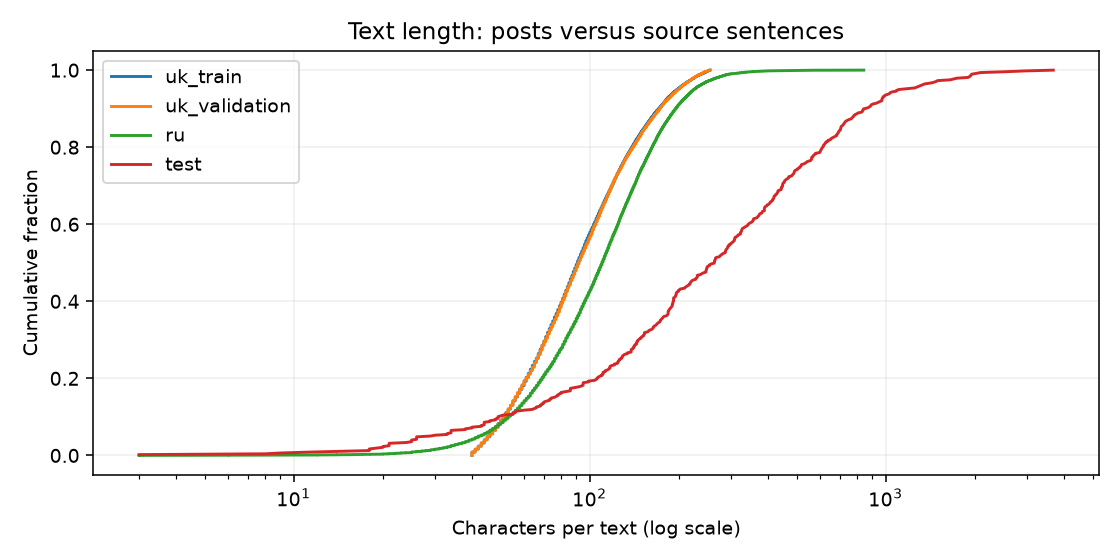

In [10]:
import matplotlib.pyplot as plt
from IPython.display import Image
fig, ax = plt.subplots(figsize=(8, 4))
for name, frame in {**reference_samples, "test": test}.items():
    lengths = np.sort(frame.text.str.len().to_numpy())
    ax.plot(lengths, np.arange(1, len(lengths) + 1) / len(lengths), label=name)
ax.set(xscale="log", xlabel="Characters per text (log scale)", ylabel="Cumulative fraction", title="Text length: posts versus source sentences")
ax.legend(); ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(analysis_dir / "text_lengths.png", dpi=140)
plt.close(fig)
display(Image(filename=str(analysis_dir / "text_lengths.png")))

**Висновок.** Зсув кривої праворуч означає довші тексти. Це причина окремо контролювати обрізання послідовностей у майбутній NER-моделі.

**Якою мовою написано test і контрольні тексти?**

Локальна [Lingua](https://github.com/pemistahl/lingua-py) вибирає серед uk, ru, en, pl, be. Результат позначаємо `uncertain`, якщо оцінка першої мови <0,8 або відрив від другої <0,2. Ці оцінки не є каліброваною ймовірністю правильності. Інші мови не підтримані цією конфігурацією; змішані дописи можуть отримати лише домінантну мову.

In [11]:
language_rows, language_summary = {}, []
for name, frame in {"test": test, **reference_samples}.items():
    detected = language_profile(frame.text)
    detected.index = frame.index
    detected["reported_language"] = detected.language.mask(detected.uncertain, "uncertain")
    language_rows[name] = detected
    for language, count in detected.reported_language.value_counts().items():
        language_summary.append({"dataset": name, "language": language, "rows_checked": len(frame), "rows": count, "percent": round(100 * count / len(frame), 2)})
language_summary = pd.DataFrame(language_summary)
language_summary

,dataset,language,rows_checked,rows,percent
0,test,uk,477,428,89.73
1,test,ru,477,38,7.97
2,test,uncertain,477,7,1.47
3,test,en,477,3,0.63
4,test,pl,477,1,0.21
5,uk_train,uk,20000,19951,99.75
6,uk_train,uncertain,20000,43,0.21
7,uk_train,en,20000,4,0.02
8,uk_train,be,20000,2,0.01
9,uk_validation,uk,10000,9977,99.77


**Висновок.** Для test Lingua визначила **428 uk (89,73%), 38 ru (7,97%), 3 en та 1 pl**; ще **7 текстів** позначено як невпевнені. Це автоматична оцінка домінантної мови в обмеженому наборі мов. У контрольних вибірках uk train 99,75% визначено як uk, ru — 98,96% як ru. Змішані дописи цим підрахунком не виділяються окремо.

**Якої частини словника test немає у джерелах?**

Після NFKC та нижнього регістру перевіряємо кожне слово test у всьому джерелі. Лематизації немає: різні відмінкові форми залишаються різними словами. Покриття токенів враховує повтори, покриття типів — різні слова.

In [12]:
vocabulary_coverage = pd.DataFrame([result["coverage"] for result in test_scans.values()]).set_index("dataset")
display(vocabulary_coverage.round(2))
pd.DataFrame({name: pd.Series(result["unseen_words"][:25]) for name, result in test_scans.items()})

,test_word_types,unseen_test_word_types,test_token_coverage_pct
dataset,,,
uk_train,9780,1143,94.44
uk_validation,9780,4368,77.15
ru,9780,6652,51.43


,uk_train,uk_validation,ru
0,00079,00079,00079
1,00грн,00грн,00грн
2,0500200508,044,0500200508
3,063-574-50-98,0500200508,063-574-50-98
4,0631566606,063,0631566606
5,0673158715,063-574-50-98,0673158715
6,0680958123,0631566606,0680958123
7,0932626376,0673158715,0932626376
8,0963036372,0680958123,0963036372
9,10грн,0932626376,100-річної


**Висновок.** Із **9 780 різних слів test** у повному uk train не знайдено **1 143**, у ru — **6 652**. З урахуванням повторів uk train покриває **94,44%** токенів test, ru — **51,43%**. Це поверхневі форми без лематизації; непокриті слова можуть бути назвами, нікнеймами, помилками або іншими відмінками.

**Чи містить test речення або близькі фрагменти з джерел?**

Jaccard порівнює повні набори шинглів. `source_shingle_coverage` показує, яка частка шинглів речення джерела присутня в дописі test. Для фрагментів вимагаємо щонайменше шість слів і покриття ≥0,90. `literal_word_sequence` додатково перевіряє безперервний збіг послідовності слів.

In [13]:
fragment_summary = []
for name, result in test_scans.items():
    nearest, contained = result["nearest"], result["containment"]
    fragment_summary.append({"dataset": name, "test_with_trigram_candidates": len(nearest),
        "test_with_Jaccard_ge_0_8": int(nearest.jaccard.ge(.8).sum()) if len(nearest) else 0,
        "test_with_covered_source_sentence": len(contained),
        "literal_sequence_among_selected": int(contained.literal_word_sequence.sum()) if len(contained) else 0})
display(pd.DataFrame(fragment_summary).set_index("dataset"))
fragment_parts = [r["containment"].sort_values("shared_trigrams", ascending=False).head(3) for r in test_scans.values() if len(r["containment"])]
fragment_examples = pd.concat(fragment_parts, ignore_index=True) if fragment_parts else pd.DataFrame(columns=["test_id"])
fragment_examples.merge(test[["text_id", "text"]], left_on="test_id", right_on="text_id", how="left").rename(columns={"text":"test_text"})

,test_with_trigram_candidates,test_with_Jaccard_ge_0_8,test_with_covered_source_sentence,literal_sequence_among_selected
dataset,,,,
uk_train,244,0,1,0
uk_validation,45,0,0,0
ru,40,0,0,0


,dataset,test_id,source_index,jaccard,source_shingle_coverage,shared_trigrams,source_words,source_text,literal_word_sequence,text_id,test_text
0,uk_train,68,325877,0.117409,0.935484,29,33,Відповідно до ст. 62 Конституції України особа вважається невинуватою у вчиненні злочину і не може бути піддана крим...,False,68,​​Вимагали гроші з підприємців та підпалювали їхнє майно - перед судом постануть 6 учасників злочинної організації\n...


**Висновок.** Кандидати зі спільними трислівними фрагментами є для **244 test-дописів із uk train, 45 із uk validation і 40 із ru**. Жодна знайдена пара повних текстів не має Jaccard ≥0,80. Поріг покриття речення ≥0,90 пройшов один фрагмент uk train — стандартне формулювання презумпції невинуватості в test №68. Це спільний правовий шаблон, а не доказ копіювання цілого допису.

**Які контрольні тексти найближчі до test за словами й символами?**

Окремо рахуємо word TF-IDF (1–2 слова) і character TF-IDF (3–5 символів), потім cosine. Словник та IDF навчаємо тільки на контрольному джерелі. Це найближчі тексти серед до 20 000 рядків, а не гарантовано найближчі в повному корпусі. Оцінки різних словників не є спільною абсолютною шкалою.

In [14]:
tfidf_matches = pd.concat([tfidf_neighbors(frame, test, name, analyzer)
    for name, frame in reference_samples.items() for analyzer in ["word", "char_wb"]], ignore_index=True)
display(tfidf_matches.groupby(["dataset", "method"]).cosine.agg(["median", "mean", "max"]).round(3))
tfidf_matches.sort_values("cosine", ascending=False).groupby(["dataset", "method"], sort=False).head(2).merge(test[["text_id", "text"]], left_on="test_id", right_on="text_id").rename(columns={"text":"test_text"})

median   mean    max
dataset       method                       
ru            char_wb   0.158  0.174  0.508
              word      0.251  0.265  1.000
uk_train      char_wb   0.225  0.234  0.501
              word      0.226  0.241  0.652
uk_validation char_wb   0.207  0.220  0.531
              word      0.229  0.241  0.687

,dataset,method,test_id,cosine,source_index,source_text,text_id,test_text
0,ru,word,169,1.000000,629919,«Лара Крофт без сисек...,169,Оболонь без купюр.\n\nЖиття🫶Оболонь
1,ru,word,202,0.925446,1593584,«У Апалькова перелом.,202,"‼️ На Київщині нетверезий водій ВАЗу виїхав на зустрічну смугу і зіткнувся з автівкою ""Seat"", повідомляє поліція.\n\..."
2,uk_validation,word,150,0.686845,1001295,"Роздумуєте, що приготувати на зиму з кабачків?",150,"👂Достало лето, хотим зиму."
3,uk_train,word,321,0.652072,793312,"Протягом 31 серпня, а також 1-4 вересня в південних, східних, центральних областях збережеться надзвичайний (5 класу...",321,🥵 У Києві 30 та 31 серпня утримається надзвичайний рівень пожежної небезпеки – Укргідрометцентр
4,uk_validation,word,188,0.643443,1004800,На місці вже працюють рятувальники і чергує швидка допомога.,188,Біля цирку горить відселена будівля.\n\nНа місці вже працюють рятувальники.
5,uk_train,word,150,0.643011,907262,Птахи вилітають разом у вирій — очікуйте сувору зиму.,150,"👂Достало лето, хотим зиму."
6,uk_validation,char_wb,280,0.530997,1004042,"""Укрзалізниця"" призначила 30 додаткових поїздів до моря - Укрaїнa - TCH.",280,Укрзалізниця призначила додаткові поїзди між Васильковом та Києвом🚊\n\nГрафік👈
7,ru,char_wb,393,0.508216,6085733,Однако 9 августа Кличко получил травму спины.,393,Кличко 👉 🫶 Фіала❤️
8,uk_train,char_wb,280,0.501213,36662,Укрзалізниця призначила 10 додаткових поїздів до Дня захисника України та Покрови Пресвятої Богородиці.,280,Укрзалізниця призначила додаткові поїзди між Васильковом та Києвом🚊\n\nГрафік👈
9,uk_train,char_wb,299,0.500913,301820,"""У найближчу годину з утриманням до кінця доби 29 та протягом 30 травня грози (I рівень небезпечності, жовтий)"", - й...",299,"🌩 На Київщині очікується гроза, – Укргідрометцентр \n\nУ найближчу годину з утриманням до кінця доби 31 серпня та вн..."


**Висновок.** Word TF-IDF показує збіги лексики, character TF-IDF — також схожі закінчення й написання. Висока схожість є приводом подивитися на пару, а не підставою переносити її мітки в test.

**Наскільки легко відрізнити речення test від джерела?**

Ділимо test на речення, беремо стільки ж речень джерела й навчаємо простий character TF-IDF + logistic regression. Векторизатор навчається заново всередині кожного з трьох folds. Усі речення одного test-допису лишаються в одному fold; однакові нормалізовані рядки джерела теж згруповані. Це діагностика доменного зсуву, не NER-модель і не заміна BiGRU-експерименту в `adversarial_validation.ipynb`.

In [15]:
domain_comparison = pd.DataFrame({name: domain_auc(frame, test) for name, frame in reference_samples.items()}).T
domain_comparison.round(3)

,test_sentences,source_sentences,OOF_AUC,fold_AUC_min,fold_AUC_max,length_only_AUC
uk_train,1916.0,1916.0,0.814,0.796,0.825,0.617
uk_validation,1916.0,1916.0,0.819,0.810,0.829,0.617
ru,1916.0,1916.0,0.990,0.987,0.993,0.676


**Висновок.** OOF AUC становить **0,814 для uk train, 0,819 для uk validation та 0,990 для ru**. Лише довжина дає відповідно 0,617, 0,617 та 0,676: відмінності не зводяться до довжини. uk validation за цією перевіркою не стає ближчою до test, ніж uk train. AUC описує розрізнення джерел, а не очікувану якість NER; діапазон folds не є довірчим інтервалом.

**Чи є повтори всередині самого test?**

Для всіх пар 477 дописів перевіряємо Jaccard трислівних шинглів ≥0,80, мінімум чотири шингли в кожному тексті. Цей малий набір перевіряємо повним перебором; нічого не видаляємо.

In [16]:
test_grams = [shingles(words(t)) for t in test.text]
internal_test_pairs = []
for i, left in enumerate(test_grams):
    for j in range(i + 1, len(test_grams)):
        right = test_grams[j]
        if min(len(left), len(right)) >= 4:
            score = len(left & right) / len(left | right)
            if score >= .8:
                internal_test_pairs.append({"left_test_id": int(test.iloc[i].text_id), "right_test_id": int(test.iloc[j].text_id), "jaccard": score})
internal_test_pairs = pd.DataFrame(internal_test_pairs, columns=["left_test_id", "right_test_id", "jaccard"])
print("near_duplicate_pairs:", len(internal_test_pairs))
internal_test_pairs

near_duplicate_pairs: 9


,left_test_id,right_test_id,jaccard
0,32,374,0.882353
1,39,145,0.870968
2,86,159,0.821429
3,102,284,0.947368
4,112,395,0.930693
5,175,182,0.884956
6,211,340,0.922222
7,245,262,0.956522
8,374,379,0.833333


**Висновок.** Знайдено **9 пар** із Jaccard ≥0,80; це пари, а не дев’ять зайвих рядків. У розділі 4 використано іншу евристику — шингли з чотирьох токенів із пунктуацією; тут три слова та окрема обробка переносів, тому кількість може відрізнятися. Жоден test-допис не вилучено.

**Що прогнозує бюджетна GPT-модель для test?**

Завантажуємо окремий збережений результат GPT‑6 Luna (`effort=low`). Модель бачила тільки тексти та однакову інструкцію: повертати назви географічних місць і адрес у вихідній формі, не включати назви лише всередині організацій або підписів каналів. Це загальна політика LOC, яка може відрізнятися від правил наданої розмітки.

Автоматично перевіряємо покриття ключів, тип списків і буквальну наявність кожного прогнозу в тексті. Це перевірка формату, а не правильності розпізнавання. Скрипт не викликає платну модель під час повторного запуску EDA.

In [17]:
gpt_inputs = pd.read_json(analysis_dir / "gpt_inputs.jsonl", lines=True)
gpt_predictions = pd.read_json(analysis_dir / "gpt_predictions.jsonl", lines=True)
assert gpt_predictions.key.is_unique and set(gpt_predictions.key) == set(gpt_inputs.key)
gpt_predictions = gpt_inputs.merge(gpt_predictions, on="key", validate="one_to_one")
for row in gpt_predictions.itertuples():
    assert isinstance(row.locations, list) and len(row.locations) == len(set(row.locations))
    assert all(isinstance(s, str) and s and s in row.text for s in row.locations)
gpt_test = gpt_predictions.loc[gpt_predictions.dataset.eq("test")].copy()
assert len(gpt_test) == len(test)
gpt_test["predicted_LOC_count"] = gpt_test.locations.map(len)
display(pd.Series({"test_posts": len(gpt_test), "posts_with_predicted_LOC": int(gpt_test.predicted_LOC_count.gt(0).sum()),
    "posts_without_predicted_LOC": int(gpt_test.predicted_LOC_count.eq(0).sum()), "predicted_strings": int(gpt_test.predicted_LOC_count.sum())}).to_frame("count"))
gpt_test[["key", "text", "locations"]].head(8)

,count
test_posts,477
posts_with_predicted_LOC,355
posts_without_predicted_LOC,122
predicted_strings,768


,key,text,locations
0,test:0,"❗️Кількість поранених зросла до трьох, – Кличко\n\nКиїв — пряма трансляція 👈",[Київ]
1,test:1,"🥤В Києві за 91,13 млн гривень починаються роботи зі знесення будівлі цеху №5 заводу “Більшовик”, які необхідні для п...","[Києві, Києва, “Шулявського шляхопроводу”]"
2,test:2,"▪️Сьогодні вночі росіяни завдали ракетного удару по селищу Гоголеве, Миргородського району Полтавської області - Офі...","[Гоголеве, Миргородського району, Полтавської області]"
3,test:3,"Наразі у запасах росіян найбільше балістичних ""Іскандерів"" й крилатих ""Калібрів"".❗️\n\nУ ГУР розповіли, скільки зага...",[]
4,test:4,"⛸В один день, 29 серпня, ДП ""Центральна учбово-тренувальна база по ковзанярському спорту ""Льодовий стадіон"" оголосил...","[проспекті Академіка Глушкова, 9]"
5,test:5,"🏭У Броварах планують створити індустріальний парк.\n\nНа території 16 га розмістять будівлі підприємств переробної, ...",[Броварах]
6,test:6,👀\n\nМожемо БПЛА прислати 😀\n\nПсков бомбить Брянськ 🍿\n\n@lossolomas_kyiv,"[Псков, Брянськ]"
7,test:7,"🧑‍🚒Ліквідовано загорання трав'яного настилу на площі 5 га\n\nПо прибуттю рятувальників було встановлено, що на полі ...",[Забуччя]


**Висновок.** GPT‑6 Luna повернула **768 назв у 355 дописах**, для **122 дописів** — порожній список. Це кількість прогнозів, а не справжніх локацій. Порожній прогноз може бути правильним або пропуском; порожня колонка `test.locations` не дозволяє це перевірити.

**Наскільки GPT-прогнози узгоджені з уже наданими мітками?**

Порівнюємо всі 26 sample та по 32 випадкові рядки uk/ru, які модель розмічала без доступу до міток. Для sample використовуємо наданий `locations`, для uk/ru — вихідні `loc_markers`. Порівнюємо множини рядків після NFKC, нижнього регістру й нормалізації пробілів. Це прозора додаткова метрика, не офіційна метрика з її особливостями.

Мітки uk/ru — надана розмітка, а не гарантовано безпомилковий еталон. Різницю записуємо як `reference_only` / `GPT_only`, без автоматичного оголошення її помилкою GPT.

In [18]:
agreement_rows = []
for row in gpt_predictions.loc[gpt_predictions.dataset.ne("test")].itertuples():
    if row.dataset == "sample":
        reference = sample.loc[row.source_index, "locations"]
        if isinstance(reference, str): reference = ast.literal_eval(reference)
    else:
        source = {"uk": uk, "ru": ru}[row.dataset].loc[row.source_index]
        reference = [source.text[a:b] for a, b in source.loc_markers]
    gold = {comparison_text(s) for s in reference}
    pred = {comparison_text(s) for s in row.locations}
    agreement_rows.append({"key": row.key, "dataset": row.dataset, "reference_count": len(gold), "GPT_count": len(pred),
        "matched": len(gold & pred), "exact_set_match": gold == pred,
        "reference_only": sorted(gold - pred), "GPT_only": sorted(pred - gold)})
agreement_rows = pd.DataFrame(agreement_rows)
agreement_summary = []
for name, group in agreement_rows.groupby("dataset"):
    hits, supplied, predicted = group.matched.sum(), group.reference_count.sum(), group.GPT_count.sum()
    agreement_summary.append({"dataset": name, "rows": len(group), "reference_strings": supplied, "GPT_strings": predicted,
        "precision_vs_reference": hits / predicted if predicted else 0,
        "recall_vs_reference": hits / supplied if supplied else 0,
        "micro_F1_vs_reference": 2 * hits / (supplied + predicted) if supplied + predicted else 1,
        "exact_set_match_pct": 100 * group.exact_set_match.mean()})
agreement_summary = pd.DataFrame(agreement_summary).set_index("dataset")
display(agreement_summary.round(3))
agreement_rows.loc[~agreement_rows.exact_set_match].groupby("dataset", sort=False).head(5)

,rows,reference_strings,GPT_strings,precision_vs_reference,recall_vs_reference,micro_F1_vs_reference,exact_set_match_pct
dataset,,,,,,,
ru,32,12,14,0.786,0.917,0.846,90.625
sample,26,32,49,0.571,0.875,0.691,50.000
uk,32,6,7,0.714,0.833,0.769,90.625


,key,dataset,reference_count,GPT_count,matched,exact_set_match,reference_only,GPT_only
3,sample:3,sample,1,2,1,False,[],[оболонь]
5,sample:5,sample,1,3,0,False,[києву],"[києва, україни, україні]"
7,sample:7,sample,1,2,1,False,[],[індустріальний міст]
8,sample:8,sample,0,1,0,False,[],[варшавського]
11,sample:11,sample,1,2,1,False,[],[києва]
30,uk:75990,uk,0,1,0,False,[],[польща]
36,uk:398087,uk,0,1,0,False,[],[батурина]
45,uk:655896,uk,3,2,2,False,[рф],[]
59,ru:1084664,ru,0,1,0,False,[],[уральский]
62,ru:2119028,ru,1,2,1,False,[],[шанхайская]


**Висновок.** На 26 sample збіглися **28 із 32** наданих назв; GPT запропонувала **49** назв. Отже, precision щодо наданих міток — **0,571**, recall — **0,875**, micro-F1 — **0,691**. Це вказує на зайві прогнози відносно розмітки й можливі розбіжності політики. Для контрольних uk/ru F1 — 0,769 / 0,846, але там лише **6 / 12** наданих назв, тому ці оцінки дуже нестабільні. Жодне з цих чисел не є F1 на test.

**Чи зустрічалися спрогнозовані назви test у LOC-мітках джерел?**

Перевіряємо тільки точні нормалізовані поверхневі форми: `Київ` і `Києві` тут різні. Обходимо всі очищені спани uk train, uk validation та ru. Це покриття прогнозів, а не справжніх test-локацій.

In [19]:
predicted_names = Counter(comparison_text(s) for names in gpt_test.locations for s in names)
source_LOC_counts = {}
for name, frame in comparison_sources.items():
    counts = Counter()
    for text, spans in zip(frame.text, frame.spans):
        for a, b in spans:
            label = comparison_text(text[a:b])
            if label in predicted_names: counts[label] += 1
    source_LOC_counts[name] = counts
predicted_LOC_coverage = pd.DataFrame({name: {
    "predicted_unique_forms": len(predicted_names), "seen_unique_forms": len(counts),
    "unseen_unique_forms": len(predicted_names.keys() - counts.keys()),
    "predicted_string_coverage_pct": 100 * sum(n for s, n in predicted_names.items() if s in counts) / sum(predicted_names.values()),
} for name, counts in source_LOC_counts.items()}).T
display(predicted_LOC_coverage.round(2))
pd.DataFrame([{"predicted_form": s, "test_posts": count, **{name: counts[s] for name, counts in source_LOC_counts.items()}} for s, count in predicted_names.most_common(20)])

,predicted_unique_forms,seen_unique_forms,unseen_unique_forms,predicted_string_coverage_pct
uk_train,481.0,266.0,215.0,70.57
uk_validation,481.0,93.0,388.0,40.62
ru,481.0,59.0,422.0,16.54


,predicted_form,test_posts,uk_train,uk_validation,ru
0,києві,55,6486,58,0
1,києва,38,4030,32,0
2,київ,25,2596,37,0
3,україни,22,24193,259,13
4,україні,18,16696,163,3
5,столиці,15,5,0,0
6,київщині,14,342,2,0
7,шевченківському районі,9,45,1,0
8,київщини,8,117,1,0
9,україну,6,3992,44,7


**Висновок.** У test-прогнозах є **481 різна нормалізована форма**. Серед очищених LOC uk train знайдено **266**, ru — **59**. З урахуванням частоти прогнозів це **70,57% / 16,54%** покриття відповідно. Решта може бути новими назвами, іншими відмінками, ширшими межами адрес або помилками GPT; їх не додаємо автоматично до навчання.

**Зберігаємо результати дослідження для перевірки.**

Таблиці, найближчі приклади та автоматичні прогнози залишаються в `results/test_analysis`. Повторний запуск обчислює аналіз, але використовує вже збережені GPT-прогнози; для нового платного прогону потрібен окремий явний запуск.

In [20]:
for name, table in {
    "structure": structure_comparison, "exact_overlap": exact_test_overlap, "vocabulary": vocabulary_coverage,
    "language": language_summary, "tfidf_neighbors": tfidf_matches, "domain_auc": domain_comparison,
    "test_near_pairs": internal_test_pairs, "GPT_reference_agreement": agreement_summary,
    "GPT_reference_differences": agreement_rows, "GPT_LOC_coverage": predicted_LOC_coverage,
}.items():
    table.to_csv(analysis_dir / f"{name}.csv", index=True)
for name, result in test_scans.items():
    result["nearest"].to_csv(analysis_dir / f"{name}_nearest_trigrams.csv", index=False)
    result["containment"].to_csv(analysis_dir / f"{name}_covered_fragments.csv", index=False)
pd.Series({"result_directory": str(analysis_dir), "test_rows_unchanged": len(test),
           "test_locations_still_empty": bool(test.locations.map(ast.literal_eval).map(len).eq(0).all())}).to_frame("value")

,value
result_directory,/Users/zaharguzij/RNN_for_NER/results/test_analysis
test_rows_unchanged,477
test_locations_still_empty,True


**Висновок.** Test переважно український, але має довші тексти, інше оформлення й помітний доменний зсув від uk train; ru лексично й мовно ще віддаленіший. Повних текстових збігів не виявлено, а перевірка фрагментів показала один спільний правовий шаблон. Автоматичні GPT-прогнози дають додаткову інформацію про можливі назви, але перевірка на sample показує, що вони не замінюють еталон. Усі таблиці та прогнози збережено окремо; test і його `locations` не змінено.

### 8.1. Чи відповідає форма міток test навчальній розмітці?

Для test доступні тільки **автоматичні GPT-прогнози**. Нижче перевіряємо їхню сумісність із наданими train-мітками; правила прихованої еталонної розмітки test із цих даних установити неможливо.

Порівнюємо три різні речі: форму рядків міток, межі щодо контексту та рішення моделі на тих самих текстах із відомими мітками. Перші дві перевірки можуть залежати від тематики: більше адрес у test саме собою не означає інші правила. Тому додаємо зіставлення варіантів тієї самої назви й контрольну перевірку на тих самих текстах. Жодну мітку не виправляємо.

**Як виглядають мітки: одне слово чи адреса, зі службовими словами чи без?**

Для uk train та повного ru беремо вихідні `loc_markers`, для sample — надані `locations`, для test — GPT-прогнози. У train одиниця підрахунку — окрема згадка, у test — унікальний рядок прогнозу на допис. Додатково показуємо профіль без повторного зважування однакових рядків, щоб часті назви країн менше впливали на результат.

Типові слова визначаємо явними регулярними виразами: вулиця/улица, проспект, район, область, місто, станція тощо. Це евристики форми, а не доведені класи сутностей.

In [10]:
from scripts.label_analysis import form_profile, boundary_profile, same_core_variants, core_form

assert core_form("вул. Хрещатик, 12") == core_form("Хрещатик")
assert core_form("Київ") != core_form("Львів")
assert core_form("Київ") != core_form("Києві")
label_counts = {}
for name in ["uk_train", "ru"]:
    frame = comparison_sources[name]
    label_counts[name] = Counter(text[a:b] for text, spans in zip(frame.text, frame.loc_markers) for a,b in spans)
label_counts["sample_reference"] = Counter(s for labels in sample.locations for s in (ast.literal_eval(labels) if isinstance(labels, str) else labels))
label_counts["test_GPT"] = Counter(s for labels in gpt_test.locations for s in labels)
label_form_summary = pd.DataFrame({name: form_profile(counts) for name, counts in label_counts.items()}).T
unique_form_summary = pd.DataFrame({name: form_profile(Counter({s:1 for s in counts})) for name, counts in label_counts.items()}).T
display(label_form_summary.T.round(2))
display(unique_form_summary.T.round(2))
label_form_summary.to_csv(analysis_dir / "label_form_profile.csv")
unique_form_summary.to_csv(analysis_dir / "unique_label_form_profile.csv")

,uk_train,ru,sample_reference,test_GPT
labels,341810.00,3708173.00,32.00,768.00
unique_forms,45110.00,132589.00,30.00,487.00
mean_words,1.18,1.13,1.34,1.41
multiword_pct,15.44,11.82,28.12,31.25
digits_pct,0.73,0.05,6.25,3.65
type_prefix_pct,1.44,0.24,15.62,8.46
type_suffix_pct,4.56,3.96,3.12,8.59
street_prefix_pct,1.31,0.08,15.62,6.77
edge_space_pct,0.06,0.00,0.00,0.00
edge_punctuation_pct,1.50,0.45,0.00,1.43


,uk_train,ru,sample_reference,test_GPT
labels,45110.00,132589.00,30.00,487.00
unique_forms,45110.00,132589.00,30.00,487.00
mean_words,1.65,1.43,1.37,1.57
multiword_pct,46.72,33.62,30.00,42.71
digits_pct,4.16,0.70,6.67,5.13
type_prefix_pct,7.19,0.64,16.67,11.70
type_suffix_pct,7.64,8.22,3.33,9.45
street_prefix_pct,6.73,0.28,16.67,9.86
edge_space_pct,0.44,0.01,0.00,0.00
edge_punctuation_pct,4.43,5.60,0.00,2.26


**Висновок.** Багатослівні мітки становлять **31,25% GPT-прогнозів test**, **15,44% uk train**, **11,82% ru** та 28,13% sample. Мітки з цифрами — відповідно **3,65%, 0,73%, 0,05% та 6,25%**. Але серед різних форм без частотного зважування багатослівних **42,71% у test і 46,72% у uk train**: частину початкової різниці пояснює частота коротких назв, а не несумісний формат. У test-прогнозах більше адресних форм; це саме собою не доводить інших правил.

**Слово `вул.` входить у мітку чи лишається перед нею?**

Порівнюємо сам спан із текстом перед його початком. Для train координати відомі. Для GPT-прогнозів використовуємо лише ті рядки назв, які буквально трапляються в дописі рівно один раз; повторні входження неоднозначні й до цієї перевірки не потрапляють. Прогнозовані координати для них не вигадуємо.

In [11]:
boundary_summaries = {}
for name in ["uk_train", "ru"]:
    frame = comparison_sources[name]
    boundary_summaries[name] = boundary_profile((text,a,b) for text, spans in zip(frame.text, frame.loc_markers) for a,b in spans)
test_records, ambiguous_predictions = [], 0
for row in gpt_test.itertuples():
    for label in row.locations:
        starts = [m.start() for m in re.finditer(re.escape(label), row.text)]
        if len(starts) != 1:
            ambiguous_predictions += 1
        else:
            test_records.append((row.text, starts[0], starts[0] + len(label)))
boundary_summaries["test_GPT_unambiguous"] = boundary_profile(test_records)
label_boundary_summary = pd.DataFrame(boundary_summaries).T.fillna(0).astype(int)
label_boundary_summary["street_cases"] = label_boundary_summary.street_type_inside + label_boundary_summary.street_type_just_before
label_boundary_summary["street_type_inside_pct"] = 100 * label_boundary_summary.street_type_inside / label_boundary_summary.street_cases.replace(0, np.nan)
print("test_predictions_excluded_as_ambiguous:", ambiguous_predictions)
display(label_boundary_summary.round(2))
label_boundary_summary.to_csv(analysis_dir / "label_boundary_policy.csv")

test_predictions_excluded_as_ambiguous: 94


,located_labels,street_type_inside,street_type_just_before,mid_word_boundaries,street_cases,street_type_inside_pct
uk_train,341810,4462,357,1501,4819,92.59
ru,3708173,2961,18233,7712,21194,13.97
test_GPT_unambiguous,674,51,4,2,55,92.73


**Висновок.** У вуличних випадках, знайдених цією евристикою, тип входить у мітку в **4 462 із 4 819 випадків uk train (92,59%)**, **2 961 із 21 194 ru (13,97%)** і **51 із 55 GPT-випадків test (92,73%)**. За цією ознакою GPT-прогнози test відповідають переважному стилю uk, а ru частіше залишає тип перед спаном. Для test перевірено 674 прогнози; 94 виключено через кілька входжень. Виявлено також 2 межі всередині слова в GPT-прогнозах — їх не можна вважати безпомилковими.

**Чи є різні межі для тієї самої назви?**

Будуємо допоміжне «ядро»: NFKC і нижній регістр, вилучення відомого слова типу на початку/кінці та кінцевого номера будинку. Наприклад, `вул. Хрещатик, 12` і `Хрещатик` матимуть одне ядро. Відмінки не зводимо: `Київ` і `Києві` різні. Спільне ядро — кандидат для порівняння меж, а не доказ тотожності місць; різні адреси однієї вулиці теж можуть мати одне ядро.

In [12]:
label_variants = same_core_variants({name: label_counts[name] for name in ["uk_train", "ru"]}, label_counts["test_GPT"])
display(label_variants.groupby("source").agg(matched_prediction_forms=("test_prediction", "size"),
    exact_forms_seen=("exact_form_seen", "sum"), forms_with_boundary_variants=("different_boundary_style", "sum")))
display(label_variants.loc[label_variants.different_boundary_style].sort_values(["source", "test_posts"], ascending=[True, False]).groupby("source").head(12))
label_variants.to_csv(analysis_dir / "same_name_label_variants.csv", index=False)

,matched_prediction_forms,exact_forms_seen,forms_with_boundary_variants
source,,,
ru,64,61,9
uk_train,308,269,105


,test_prediction,test_posts,core,source,exact_form_seen,source_variants,different_boundary_style
22,ул. Дмитриевская,1,дмитриевская,ru,False,"[(Дмитриевская, 1)]",True
211,Киевской области,1,киевской,ru,True,"[(Киевской области, 522), (Киевской, 66), (Киевской улице, 17), (Киевской областях, 9), (Киевской улицы, 6)]",True
215,вулиці Сагайдачного,1,сагайдачного,ru,False,"[(Сагайдачного, 1)]",True
225,Украина,1,украина,ru,True,"[(Украина, 12504), (Республики Украина, 2)]",True
239,Энгельса,1,энгельса,ru,True,"[(Энгельса, 81), (улице Энгельса, 1)]",True
284,Дарницком районе,1,дарницком,ru,True,"[(Дарницком районе, 18), (Дарницком районах, 2), (Дарницком, 1), (Дарницком бульваре, 1)]",True
300,Псковском,1,псковском,ru,True,"[(Псковском районе, 1), (Псковском, 1)]",True
330,Дарницком,1,дарницком,ru,True,"[(Дарницком районе, 18), (Дарницком районах, 2), (Дарницком, 1), (Дарницком бульваре, 1)]",True
369,Святошинском районе,1,святошинском,ru,True,"[(Святошинском районе, 15), (Святошинском, 1), (Святошинском районах, 1)]",True
2,Києва,38,києва,uk_train,True,"[(Києва, 4030), (м. Києва, 2), (площі Києва, 1), (міста Києва, 1)]",True


**Висновок.** Зіставлено ядра **308 test-форм з uk train** та 64 з ru. Для 105 / 9 відповідно знайдено варіанти з різним включенням типу. Це наявність варіантів, а не кількість помилок. Наприклад, у uk train є **«Шевченківському районі» 45 разів і «Шевченківському» 22 рази**; GPT теж використовує обидві форми. Отже, навчальна розмітка сама не задає єдину послідовну межу для всіх районів. Порівняння ядра не враховує відмінків і може об’єднати різні адреси однієї вулиці.

**Коли модель бачить той самий текст, розходження стосується меж чи вибору сутності?**

Використовуємо наявні сліпі GPT-прогнози для 26 sample і по 32 uk/ru. Серед розбіжностей знаходимо однозначні пари з однаковим ядром. Решту залишаємо непоясненими: це можуть бути пропуски, зайві прогнози, інші відмінки, інша політика або неточна надана розмітка. Це не автоматичне виправлення й не F1 на test.

In [13]:
controlled_differences = []
for row in agreement_rows.itertuples():
    remaining_ref, remaining_GPT = set(row.reference_only), set(row.GPT_only)
    for supplied in sorted(row.reference_only):
        matches = [p for p in remaining_GPT if core_form(supplied) and core_form(supplied) == core_form(p)]
        if len(matches) == 1 and sum(core_form(s) == core_form(matches[0]) for s in remaining_ref) == 1:
            predicted = matches[0]
            controlled_differences.append({"key": row.key, "dataset": row.dataset, "kind": "boundary_or_address_variant", "reference": supplied, "GPT": predicted})
            remaining_ref.remove(supplied); remaining_GPT.remove(predicted)
    for supplied in sorted(remaining_ref):
        controlled_differences.append({"key": row.key, "dataset": row.dataset, "kind": "reference_only_unresolved", "reference": supplied, "GPT": ""})
    for predicted in sorted(remaining_GPT):
        controlled_differences.append({"key": row.key, "dataset": row.dataset, "kind": "GPT_only_unresolved", "reference": "", "GPT": predicted})
controlled_differences = pd.DataFrame(controlled_differences)
display(pd.crosstab(controlled_differences.dataset, controlled_differences.kind))
display(controlled_differences.merge(gpt_predictions[["key", "text"]], on="key", how="left"))
controlled_differences.to_csv(analysis_dir / "controlled_label_policy_differences.csv", index=False)

kind,GPT_only_unresolved,boundary_or_address_variant,reference_only_unresolved
dataset,,,
ru,3,0,1
sample,19,2,2
uk,2,0,1


,key,dataset,kind,reference,GPT,text
0,sample:3,sample,GPT_only_unresolved,,оболонь,"Друзі. Останні дві ночі, і ще декілька наступних, ми з вами будемо відчувати певний дискомфорт у звʼязку з фінішним ..."
1,sample:5,sample,reference_only_unresolved,києву,,Подовження роботи закладів харчування\n\nВладою Києва прийнято рішення щодо подовження роботи закладів харчування. П...
2,sample:5,sample,GPT_only_unresolved,,києва,Подовження роботи закладів харчування\n\nВладою Києва прийнято рішення щодо подовження роботи закладів харчування. П...
3,sample:5,sample,GPT_only_unresolved,,україни,Подовження роботи закладів харчування\n\nВладою Києва прийнято рішення щодо подовження роботи закладів харчування. П...
4,sample:5,sample,GPT_only_unresolved,,україні,Подовження роботи закладів харчування\n\nВладою Києва прийнято рішення щодо подовження роботи закладів харчування. П...
5,sample:7,sample,GPT_only_unresolved,,індустріальний міст,ДТП біля заїзду в ТЦ Аркадія\n\n📍Індустріальний міст
6,sample:8,sample,GPT_only_unresolved,,варшавського,“Київський метрополітен” отримав ще 6 вагонів від варшавського метро\n\n🇵🇱Столичний метрополітен у серпні отримав др...
7,sample:11,sample,GPT_only_unresolved,,києва,"⛓️У Шевченківському районі оперативники затримали грабіжника, повідомляє поліція Києва.\n\nЗловмисник, вибравши жерт..."
8,sample:12,sample,GPT_only_unresolved,,оболонь,"Ще 6 варшавських вагончиків метро підвезли на Героїв Дніпра, вже ніби 24 вагони.\n\nЖиття🫶Оболонь"
9,sample:13,sample,GPT_only_unresolved,,київському національному університеті імені тараса шевченка,У Київському національному університеті імені Тараса Шевченка ще 31 грудня 2022 року було пошкоджено модерністські в...


**Висновок.** На тих самих контрольних текстах знайдено дві однозначні пари з різницею адресної форми: **«вул. Солом'янська, 28» → «вул. Солом'янська»** і **«вул. Здолбунівська, 1» → «вул. Здолбунівська, 17»**. Другий випадок може відображати неточність самої наданої розмітки; жодну сторону не виправляємо. Решта розбіжностей включає вибір інших сутностей, а не лише межі: наприклад, GPT додає назву університету чи географічні прикметники всередині назв організацій. **Форма GPT-міток test загалом сумісна з uk train, особливо щодо включення типу вулиці, але повну відповідність політики не підтверджено.** Стиль ru для вулиць відрізняється. Про відповідність прихованих еталонних міток test висновку зробити не можна.

## 9. Профіль test для майбутньої validation

Завдання цього розділу — **витягнути характеристики test та порівняти з джерелами**. Жоден новий validation-набір, список відібраних рядків або квоти не створюється. Отримані таблиці описують, на що можна буде орієнтуватися пізніше.

Головне обмеження: test — це дописи з **автоматичними GPT-мітками**, uk/ru — переважно речення з наданою розміткою. Порівнюємо окремо цілі дописи й наближено виділені речення. Кількість міток тут — **кількість різних поверхневих рядків у тексті**, а не кількість повторних згадок. Порожній прогноз означає відсутність прогнозованих назв, а не доведену відсутність локацій.

**Який точний профіль цілих test-дописів?**

Використовуємо збережені прогнози GPT‑6 Luna, без нового виклику моделі. Для кожного допису зберігаємо кількість назв, слів, символів, наявність згадки Києва та вуличного типового слова в прогнозі. Два останні показники — евристики, не повна тема чи типізація.

In [7]:
import sys
project_root = DATA.resolve().parent
if str(project_root) not in sys.path: sys.path.insert(0,str(project_root))
from scripts.test_profile import feature_row, source_features, pseudo_sentences, profile, distributions, distribution_distances, strata
from scripts.test_analysis import language_profile, comparison_text

fingerprint_dir = project_root / "results" / "test_analysis" / "test_fingerprint"
fingerprint_dir.mkdir(parents=True,exist_ok=True)
fp_inputs = pd.read_json(fingerprint_dir.parent / "gpt_inputs.jsonl",lines=True)
fp_predictions = pd.read_json(fingerprint_dir.parent / "gpt_predictions.jsonl",lines=True)
fp_GPT = fp_inputs.merge(fp_predictions,on="key",validate="one_to_one")
fp_test = fp_GPT.loc[fp_GPT.dataset.eq("test")].copy()
assert len(fp_test)==len(test)==477
for r in fp_test.itertuples():
    assert r.text==test.loc[r.source_index,"text"] and all(s and s in r.text for s in r.locations)
fp_posts = pd.DataFrame([dict(feature_row(r.text,r.locations),post_key=r.key,text=r.text) for r in fp_test.itertuples()])
display(pd.Series(profile(fp_posts)).to_frame("test_posts"))
fp_posts[["post_key","labels","words","chars","kyiv","street"]].head(10)

,test_posts
rows,477.000000
zero_labels_pct,25.576520
labels_total,768.000000
labels_per_row_mean,1.610063
labels_p50,1.000000
labels_p90,4.000000
labels_max,13.000000
words_p50,36.000000
words_p90,114.400000
kyiv_rows_pct,41.090147


,post_key,labels,words,chars,kyiv,street
0,test:0,1,9,74,True,False
1,test:1,3,106,863,True,False
2,test:2,3,41,326,False,False
3,test:3,0,19,153,False,False
4,test:4,1,67,489,False,True
5,test:5,1,18,152,False,False
6,test:6,2,7,68,False,False
7,test:7,1,30,218,True,False
8,test:8,0,74,503,False,False
9,test:9,2,24,164,False,False


**Висновок.** У **477 дописах** є **768 прогнозованих назв**, у середньому **1,61 на допис**, максимум — **13**. Без прогнозованих назв — **122 дописи (25,58%)**. Ці величини описують цілі дописи й не переносяться прямо на речення train.

**Скільки дописів мають 0, 1, 2 або багато міток?**

Показуємо весь дискретний розподіл, а не лише середнє. Окремо рахуємо щільність назв на 100 слів: вона допомагає побачити вплив довжини, але теж залежить від помилок псевдорозмітки.

In [8]:
fp_label_hist = fp_posts.labels.value_counts().sort_index().rename_axis("labels_per_post").to_frame("posts")
fp_label_hist["percent"] = 100*fp_label_hist.posts/len(fp_posts)
display(fp_label_hist.round(2))
fp_density = fp_posts.loc[fp_posts.words.gt(0)].copy()
fp_density["labels_per_100_words"] = 100*fp_density.labels/fp_density.words
display(fp_density.labels_per_100_words.describe(percentiles=[.25,.5,.75,.9,.95,.99]).to_frame())
fp_posts[["labels","words","chars"]].corr(method="spearman").round(3)

,posts,percent
labels_per_post,,
0,122,25.58
1,170,35.64
2,97,20.34
3,37,7.76
4,20,4.19
5,11,2.31
6,8,1.68
7,3,0.63
8,3,0.63


,labels_per_100_words
count,476.000000
mean,5.023012
std,7.053067
min,0.000000
25%,0.000000
50%,3.200205
75%,6.250000
90%,12.019231
95%,17.207792
99%,33.333333


,labels,words,chars
labels,1.000,0.434,0.436
words,0.434,1.000,0.995
chars,0.436,0.995,1.000


**Висновок.** 0 назв мають **122 дописи (25,58%)**, 1 — **170 (35,64%)**, 2 — **97 (20,34%)**, 3–4 — **57 (11,95%)**, 5+ — **31 (6,50%)**. Тому одного середнього 1,61 недостатньо для опису розподілу. Кореляція з довжиною описова, а не причинна.

**Наскільки нестабільна частка порожніх прогнозів у 477 дописах?**

Робимо 2 000 bootstrap-перевибірок цілих дописів (`seed=0`). Інтервал показує чутливість до складу цього набору. Він не враховує систематичні помилки GPT, не є інтервалом справжньої частки текстів без місць і не гарантує склад майбутніх даних.

In [9]:
fp_rng = np.random.default_rng(0)
fp_empty = fp_posts.labels.eq(0).to_numpy()
fp_draws = fp_rng.integers(0,len(fp_posts),size=(2000,len(fp_posts)))
fp_empty_boot = 100*fp_empty[fp_draws].mean(axis=1)
fp_empty_interval = pd.Series({"observed_empty_pct":100*fp_empty.mean(),"bootstrap_2_5_pct":np.quantile(fp_empty_boot,.025),
    "bootstrap_97_5_pct":np.quantile(fp_empty_boot,.975),"resamples":2000}).to_frame("value")
fp_empty_interval.round(2)

,value
observed_empty_pct,25.58
bootstrap_2_5_pct,21.80
bootstrap_97_5_pct,29.77
resamples,2000.00


**Висновок.** Частка порожніх прогнозів — **25,58%**; центральні 95% bootstrap-значень становлять **21,80–29,77%**. Це лише чутливість до перевибору цих дописів. Залежність між репостами й систематичні помилки GPT не враховані; справжню частку текстів без локацій цей інтервал не встановлює.

**Що змінюється, якщо порівнювати речення з реченнями?**

Розбиваємо test за переносами та наближеними межами речень, захищаючи поширені скорочення `вул.`, `м.`, `ст.` тощо. Буквальні `\n` обробляємо зі збереженням координат. Це евристична сегментація, а не ідеальний лінгвістичний розбір.

Назву з одним входженням і повним потраплянням у речення можна розташувати однозначно. Якщо назва повторюється або перетинає межу, речення позначаємо `uncertain`. `labels` — однозначно розташовані назви; `labels_upper` додає можливі. Порожній рядок за верхньою оцінкою — без назв згідно з цими прогнозами, а не за еталоном.

In [10]:
fp_sentences = pseudo_sentences(fp_test)
fp_resolved = fp_sentences.loc[~fp_sentences.uncertain].copy()
fp_sentence_target = fp_resolved.loc[fp_resolved.words.ge(5)].copy()
fp_sentence_sensitivity = pd.DataFrame({
    "all_sentences_definite_only":profile(fp_sentences),
    "all_sentences_possible_included":profile(fp_sentences,label_col="labels_upper"),
    "resolved_sentences":profile(fp_resolved),
    "resolved_at_least_5_words":profile(fp_sentence_target),
}).T
display(fp_sentence_sensitivity.round(2))
pd.Series({"sentences":len(fp_sentences),"posts_with_sentences":fp_sentences.post_key.nunique(),
    "uncertain_sentences":int(fp_sentences.uncertain.sum()),"sentences_shorter_than_5_words":int(fp_sentences.words.lt(5).sum()),
    "fraction_all_sentences_in_resolved_5word_view_pct":100*len(fp_sentence_target)/len(fp_sentences)}).to_frame("count_or_percent")

,rows,zero_labels_pct,labels_total,labels_per_row_mean,labels_p50,labels_p90,labels_max,words_p50,words_p90,kyiv_rows_pct,street_label_rows_pct
all_sentences_definite_only,2551.0,79.62,665.0,0.26,0.0,1.0,6.0,9.0,20.0,12.54,2.23
all_sentences_possible_included,2551.0,72.25,924.0,0.36,0.0,1.0,6.0,9.0,20.0,12.54,2.23
resolved_sentences,2309.0,79.82,589.0,0.26,0.0,1.0,6.0,8.0,19.0,9.92,2.08
resolved_at_least_5_words,1694.0,75.80,528.0,0.31,0.0,1.0,6.0,11.0,21.0,10.51,2.60


,count_or_percent
sentences,2551.000000
posts_with_sentences,476.000000
uncertain_sentences,242.000000
sentences_shorter_than_5_words,649.000000
fraction_all_sentences_in_resolved_5word_view_pct,66.405331


**Висновок.** Виділено **2 551 фрагмент-речення у 476 дописах**, з них **242** мають невизначені входження назв. Залежно від їх трактування без прогнозованих назв виходить **72,25–79,62%** речень. Серед **1 694 однозначних речень із ≥5 словами** — **75,80%** порожніх і **0,312 назви на речення**. Цей піднабір становить **66,41%** усіх фрагментів і має власний відбір за довжиною/повторюваністю. Межі діапазону описують розташування прогнозованих рядків, а не невизначеність істинної розмітки. Вуличний індикатор у таблиці враховує лише однозначно розташовані назви.

**Наскільки відрізняються наявні дані?**

Для всіх uk train, uk validation, ru та sample рахуємо різні поверхневі назви на рядок. Тому сума може бути меншою за кількість LOC-спанів у розділі 2: повторні однакові згадки тут рахуються один раз. Окрема колонка `clean_labels` показує результат наявного `clean_spans`. Повний ru залишається в порівнянні, без вибірки.

In [11]:
fp_sources = {"uk_train":uk.loc[uk.is_valid.eq(0)],"uk_validation":uk.loc[uk.is_valid.eq(1)],"ru":ru,"sample_reference":sample}
fp_source_features = {name:source_features(frame) for name,frame in fp_sources.items()}
fp_profiles = pd.DataFrame({**{name:profile(frame) for name,frame in fp_source_features.items()},
    "test_posts_GPT":profile(fp_posts),"test_sentences_resolved_5words_GPT":profile(fp_sentence_target)}).T
display(fp_profiles.T.round(2))
fp_cleaning = pd.DataFrame({name:{"raw_empty_pct":100*frame.labels.eq(0).mean(),"clean_empty_pct":100*frame.clean_labels.eq(0).mean(),
    "raw_unique_strings_total":int(frame.labels.sum()),"clean_unique_strings_total":int(frame.clean_labels.sum()),
    "rows_with_clean_LOC":int(frame.clean_labels.gt(0).sum())} for name,frame in fp_source_features.items()}).T
fp_cleaning.round(2)

,uk_train,uk_validation,ru,sample_reference,test_posts_GPT,test_sentences_resolved_5words_GPT
rows,1000000.00,10000.00,8028840.00,26.00,477.00,1694.00
zero_labels_pct,76.89,76.97,69.31,38.46,25.58,75.80
labels_total,338850.00,3275.00,3668443.00,32.00,768.00,528.00
labels_per_row_mean,0.34,0.33,0.46,1.23,1.61,0.31
labels_p50,0.00,0.00,0.00,1.00,1.00,0.00
labels_p90,1.00,1.00,1.00,2.00,4.00,1.00
labels_max,16.00,12.00,55.00,10.00,13.00,6.00
words_p50,13.00,13.00,15.00,29.50,36.00,11.00
words_p90,24.00,24.00,26.00,103.00,114.40,21.00
kyiv_rows_pct,2.23,2.09,0.61,46.15,41.09,10.51


,raw_empty_pct,clean_empty_pct,raw_unique_strings_total,clean_unique_strings_total,rows_with_clean_LOC
uk_train,76.89,76.90,338850.0,335254.0,231001.0
uk_validation,76.97,76.97,3275.0,3244.0,2303.0
ru,69.31,69.31,3668443.0,3666854.0,2464388.0
sample_reference,38.46,38.46,32.0,32.0,16.0


**Висновок.** У поточному uk validation **76,97%** речень без наданих назв і **0,328 різної назви на рядок**. У однозначному sentence-level піднаборі test — **75,80% / 0,312**, тобто за цією ознакою набір уже близький. Для uk train — **76,89% / 0,339**, ru — **69,31% / 0,457**. Очищення майже не змінює частку нульових рядків: у uk train вона стає 76,90%. Видалення всіх рядків без LOC натомість дало б 0% нульового класу — інший профіль.

**Які саме розподіли потрібно буде порівнювати?**

Рахуємо групи 0 / 1 / 2 / 3–4 / 5+ назв і 0–15 / 16–30 / 31–60 / 61–120 / 121+ слів, а також індикатори Києва й вуличних міток. TV — відстань між двома частотними розподілами: 0 означає однакові частки, 1 — неперетинні. Це відстань за конкретною ознакою, а не загальна якість майбутньої validation.

In [12]:
fp_distribution_tables = {name:distributions(frame) for name,frame in fp_source_features.items()}
fp_distribution_tables["test_posts_GPT"] = distributions(fp_posts)
fp_distribution_tables["test_sentences_resolved_5words_GPT"] = distributions(fp_sentence_target)
fp_distributions = pd.concat([table.assign(dataset=name) for name,table in fp_distribution_tables.items()],ignore_index=True)
display(fp_distributions.loc[fp_distributions.feature.eq("labels")].pivot(index="bin",columns="dataset",values="fraction").mul(100).round(2))
display(fp_distributions.loc[fp_distributions.feature.eq("words")].pivot(index="bin",columns="dataset",values="fraction").mul(100).round(2))
fp_distances = distribution_distances(fp_distribution_tables,"test_sentences_resolved_5words_GPT")
fp_distances.pivot(index="dataset",columns="feature",values="total_variation").round(3)

dataset,ru,sample_reference,test_posts_GPT,test_sentences_resolved_5words_GPT,uk_train,uk_validation
bin,,,,,,
0,69.31,38.46,25.58,75.80,76.89,76.97
1,20.99,38.46,35.64,19.19,16.07,16.39
2,6.66,15.38,20.34,3.72,4.80,4.77
3-4,2.56,3.85,11.95,1.12,1.90,1.59
5+,0.48,3.85,6.50,0.18,0.34,0.28


dataset,ru,sample_reference,test_posts_GPT,test_sentences_resolved_5words_GPT,uk_train,uk_validation
bin,,,,,,
0-15,52.54,38.46,22.01,75.68,64.28,63.67
121+,0.00,3.85,9.43,0.00,0.00,0.00
16-30,42.71,11.54,23.90,22.43,33.45,33.88
31-60,4.66,26.92,24.53,1.89,2.27,2.45
61-120,0.08,19.23,20.13,0.00,0.00,0.00


feature,kyiv,labels,street,words
dataset,,,,
ru,0.099,0.065,0.022,0.231
sample_reference,0.356,0.373,0.128,0.481
test_posts_GPT,0.306,0.502,0.070,0.537
test_sentences_resolved_5words_GPT,0.000,0.000,0.000,0.000
uk_train,0.083,0.031,0.021,0.114
uk_validation,0.084,0.028,0.021,0.120


**Висновок.** Відстань TV між розподілами кількості назв однозначного sentence-level test і uk validation — **0,028**, за довжиною — **0,120**. Медіана довжини — **11 слів у цьому піднаборі test проти 13 у validation**. Значно помітніші тематичні відмінності: Київ згадується у **10,51% проти 2,09%** рядків, вуличний маркер у мітках є у **2,60% проти 0,53%**. Одна схожість за нульовим класом не описує весь домен.

**Які ознаки поєднуються всередині test?**

Показуємо спільні частоти кількості назв, довжини, згадки Києва й вуличного маркера. Це опис наявного test, не квоти й не відбір рядків для validation. Окремо перевіряємо, як частка порожніх прогнозів залежить від довжини допису.

In [13]:
fp_joint_rows = []
for name,frame in {"test_posts_GPT":fp_posts,"test_sentences_resolved_5words_GPT":fp_sentence_target}.items():
    for key,count in strata(frame).value_counts().items():
        fp_joint_rows.append({"view":name,"label_bin":key[0],"word_bin":key[1],"kyiv":key[2],"street":key[3],"rows":count,"percent":100*count/len(frame)})
fp_joint = pd.DataFrame(fp_joint_rows)
display(fp_joint.groupby("view",sort=False).head(15).round(2))
fp_conditional = fp_posts.assign(word_bin=pd.cut(fp_posts.words,[-1,15,30,60,120,np.inf],labels=["0-15","16-30","31-60","61-120","121+"]),empty=fp_posts.labels.eq(0))
fp_conditional = fp_conditional.groupby("word_bin",observed=False).agg(posts=("labels","size"),empty_pct=("empty",lambda x:100*x.mean()),labels_mean=("labels","mean"))
fp_conditional.round(2)

,view,label_bin,word_bin,kyiv,street,rows,percent
0,test_posts_GPT,0,0-15,False,False,39,8.18
1,test_posts_GPT,1,16-30,False,False,30,6.29
2,test_posts_GPT,1,0-15,False,False,26,5.45
3,test_posts_GPT,1,16-30,True,False,25,5.24
4,test_posts_GPT,0,31-60,False,False,23,4.82
5,test_posts_GPT,0,16-30,False,False,20,4.19
6,test_posts_GPT,1,31-60,False,False,17,3.56
7,test_posts_GPT,0,61-120,False,False,16,3.35
8,test_posts_GPT,1,0-15,True,False,14,2.94
9,test_posts_GPT,1,31-60,True,False,14,2.94


,posts,empty_pct,labels_mean
word_bin,,,
0-15,105,42.86,0.70
16-30,114,22.81,1.12
31-60,117,23.93,1.77
61-120,96,16.67,2.12
121+,45,15.56,3.47


**Висновок.** Серед test-дописів до 15 слів без прогнозованих назв **42,86%**, понад 120 слів — **15,56%**; середня кількість назв у цих групах **0,70 / 3,47**. Отже, довжина та нульовий клас пов’язані. Спільні таблиці фіксують також поєднання з Києвом і вулицями, не створюючи квот чи нового розбиття.

**Чи зберігається мовний склад після переходу до речень?**

Повторюємо локальне визначення серед uk/ru/en/pl/be для всього test і однозначних речень із ≥5 словами. Невпевнені визначення виділяємо окремо. Для джерел показуємо вже збережену оцінку Lingua на фіксованих контрольних наборах із розділу 8; її не видаємо за перевірку всього ru.

In [14]:
fp_language_tables = []
for name,frame in {"test_posts_GPT":fp_posts,"test_sentences_resolved_5words_GPT":fp_sentence_target}.items():
    detected = language_profile(frame.text)
    reported = detected.language.mask(detected.uncertain,"uncertain")
    for lang,count in reported.value_counts().items():
        fp_language_tables.append({"view":name,"language":lang,"rows":count,"rows_checked":len(frame),"percent":100*count/len(frame)})
fp_language = pd.DataFrame(fp_language_tables)
display(fp_language.round(2))
pd.read_csv(fingerprint_dir.parent / "language.csv").drop(columns=["Unnamed: 0"],errors="ignore")

,view,language,rows,rows_checked,percent
0,test_posts_GPT,uk,428,477,89.73
1,test_posts_GPT,ru,38,477,7.97
2,test_posts_GPT,uncertain,7,477,1.47
3,test_posts_GPT,en,3,477,0.63
4,test_posts_GPT,pl,1,477,0.21
5,test_sentences_resolved_5words_GPT,uk,1509,1694,89.08
6,test_sentences_resolved_5words_GPT,ru,101,1694,5.96
7,test_sentences_resolved_5words_GPT,uncertain,71,1694,4.19
8,test_sentences_resolved_5words_GPT,en,10,1694,0.59
9,test_sentences_resolved_5words_GPT,pl,3,1694,0.18


,dataset,language,rows_checked,rows,percent
0,test,uk,477,428,89.73
1,test,ru,477,38,7.97
2,test,uncertain,477,7,1.47
3,test,en,477,3,0.63
4,test,pl,477,1,0.21
5,uk_train,uk,20000,19951,99.75
6,uk_train,uncertain,20000,43,0.21
7,uk_train,en,20000,4,0.02
8,uk_train,be,20000,2,0.01
9,uk_validation,uk,10000,9977,99.77


**Висновок.** На рівні дописів Lingua визначила **89,73% uk / 7,97% ru**, а в однозначних реченнях із ≥5 словами — **89,08% uk / 5,96% ru**. Частка невпевнених визначень зросла з **1,47% до 4,19%**. Мовні пропорції залежать від одиниці тексту та відбору речень; у майбутньому їх потрібно буде порівнювати на однакових одиницях.

**Наскільки сама GPT змінює частку «без міток»?**

На наданих контрольних текстах порівнюємо нульовий клас GPT і наявної розмітки. Модель бачила ці тексти без міток. uk/ru мають лише по 32 контрольні рядки, sample — 26; це перевірка чутливості, а не калібрування точності на test.

In [15]:
fp_control_rows = []
for row in fp_GPT.loc[fp_GPT.dataset.ne("test")].itertuples():
    frame = {"uk":uk,"ru":ru,"sample":sample}[row.dataset]
    ref = frame.loc[row.source_index]
    reference_empty = not bool(ref.loc_markers)
    predicted_empty = not bool(row.locations)
    fp_control_rows.append({"dataset":row.dataset,"reference_empty":reference_empty,"GPT_empty":predicted_empty})
fp_control = pd.DataFrame(fp_control_rows)
fp_control_summary = fp_control.groupby("dataset").agg(rows=("GPT_empty","size"),reference_empty_pct=("reference_empty",lambda x:100*x.mean()),GPT_empty_pct=("GPT_empty",lambda x:100*x.mean()))
fp_control_summary["zero_class_disagreements"] = fp_control.assign(disagree=fp_control.reference_empty.ne(fp_control.GPT_empty)).groupby("dataset").disagree.sum()
fp_control_summary.round(2)

,rows,reference_empty_pct,GPT_empty_pct,zero_class_disagreements
dataset,,,,
ru,32,68.75,65.62,1
sample,26,38.46,26.92,5
uk,32,87.50,81.25,2


**Висновок.** На sample частка порожніх відповідей за наданими мітками — **38,46%**, за GPT — **26,92%**; факт наявності назв відрізняється у **5 із 26 текстів**. На uk — 2 із 32, на ru — 1 із 32. Отже, навіть нульовий клас залежить від моделі й політики розмітки. Псевдочастки test не є безумовно правильними цільовими значеннями.

**Які назви й форми визначають цей профіль?**

Зберігаємо всі прогнозовані назви, їхні поверхневі варіанти, кількість дописів і приклади ключів. Це автоматичний інвентар, а не підтверджений словник географії. Розподіли типів і правил меж уже досліджені в розділах 2 та 8.1.

In [16]:
fp_inventory_rows = []
for row in fp_test.itertuples():
    for s in row.locations:
        fp_inventory_rows.append({"normalized_form":comparison_text(s),"surface":s,"post_key":row.key})
fp_inventory_mentions = pd.DataFrame(fp_inventory_rows)
fp_inventory = fp_inventory_mentions.groupby("normalized_form").agg(posts=("post_key","nunique"),surface_variants=("surface",lambda x:sorted(set(x))),post_keys=("post_key",lambda x:sorted(set(x))))
fp_inventory = fp_inventory.sort_values("posts",ascending=False)
display(fp_inventory.head(25))
pd.Series({"normalized_unique_forms":len(fp_inventory),"forms_in_one_post":int(fp_inventory.posts.eq(1).sum()),"forms_in_one_post_pct":100*fp_inventory.posts.eq(1).mean()}).to_frame("value")

,posts,surface_variants,post_keys
normalized_form,,,
києві,55,[Києві],"[test:1, test:104, test:108, test:125, test:126, test:14, test:141, test:149, test:16, test:174, test:19, test:193, ..."
києва,38,[Києва],"[test:1, test:11, test:110, test:116, test:123, test:139, test:160, test:165, test:172, test:173, test:175, test:182..."
київ,25,[Київ],"[test:0, test:102, test:172, test:183, test:228, test:240, test:245, test:262, test:270, test:272, test:282, test:28..."
україни,22,[України],"[test:113, test:133, test:157, test:186, test:194, test:213, test:226, test:227, test:242, test:251, test:297, test:..."
україні,18,[Україні],"[test:104, test:112, test:126, test:184, test:204, test:209, test:211, test:213, test:24, test:28, test:304, test:37..."
столиці,15,[столиці],"[test:125, test:145, test:174, test:175, test:182, test:262, test:267, test:296, test:302, test:364, test:378, test:..."
київщині,14,[Київщині],"[test:137, test:145, test:163, test:168, test:202, test:235, test:299, test:324, test:343, test:39, test:397, test:4..."
шевченківському районі,9,[Шевченківському районі],"[test:159, test:178, test:179, test:25, test:286, test:323, test:329, test:35, test:86]"
київщини,8,[Київщини],"[test:156, test:168, test:200, test:233, test:278, test:290, test:367, test:472]"


,value
normalized_unique_forms,481.000000
forms_in_one_post,414.000000
forms_in_one_post_pct,86.070686


**Висновок.** Збережено **481 різну нормалізовану форму**, з яких **414 (86,07%)** трапляються лише в одному дописі. Інвентар містить поверхневі варіанти й ключі всіх відповідних дописів. Така кількість рідкісних форм показує, чому збіг лише найчастіших назв не описує весь test.

**Зберігаємо опис test для майбутнього зіставлення.**

Експортуємо індивідуальні ознаки всіх test-дописів і речень, межі невизначеності та агреговані порівняння. Тут немає списків кандидатів, train/validation індексів або нового розбиття.

In [17]:
for name,table in {"posts":fp_posts,"sentences":fp_sentences,"post_label_histogram":fp_label_hist,"empty_bootstrap":fp_empty_interval,
    "sentence_sensitivity":fp_sentence_sensitivity,"source_comparison":fp_profiles,"cleaning_sensitivity":fp_cleaning,
    "distributions":fp_distributions,"distribution_distances":fp_distances,"joint_test_profile":fp_joint,
    "empty_by_length":fp_conditional,"language":fp_language,"GPT_zero_class_control":fp_control_summary,
    "entity_inventory":fp_inventory}.items():
    table.to_csv(fingerprint_dir / f"{name}.csv",index=True)
pd.Series({"saved_tables":14,"directory":str(fingerprint_dir),"new_validation_created":False}).to_frame("value")

,value
saved_tables,14
directory,/Users/zaharguzij/RNN_for_NER/results/test_analysis/test_fingerprint
new_validation_created,False


**Висновок.** Збережено **14 описових таблиць**, усі дописи й речення test з ознаками та повний інвентар прогнозованих назв. Найважливіше розділення: **25,58% порожніх дописів** проти приблизно **72–80% порожніх фрагментів-речень** за різних трактувань невизначених прогнозів. За кількістю назв sentence-level test близький до uk validation, за Києвом і вулицями — суттєво відрізняється. Новий validation, квоти й списки кандидатів не створено; це лише виміряний профіль для наступного етапу.

### 9.1. Які саме назви є в кожному наборі: словники та перетини

Тут «мітка» означає **конкретний рядок назви локації**, а не спільний клас LOC. Будуємо словники uk train, uk validation, повного ru, наданого sample і GPT-прогнозів test.

Основне порівняння — за вихідними `loc_markers`. Окремо перевіряємо, що змінює `clean_spans`. Ключ порівняння: NFKC → нижній регістр → нормалізація пробілів. Відмінки, мови й переклади не зводимо: `Київ`, `Києві` та `Киев` залишаються різними формами. Пунктуацію не видаляємо, щоб не приховати відмінності меж. Порожні ключі не порівнюємо; фрагменти лише з пунктуації окремо рахуємо як підозрілі.

**Скільки різних назв має кожен набір і які з них найчастіші?**

Використовуємо повні лічильники з розділу 2. Для джерел частота означає кількість LOC-спанів; для GPT-test — кількість дописів із певним поверхневим прогнозом. Ці частоти не порівнюємо як однакові одиниці.

In [9]:
from scripts.test_analysis import comparison_text
vocab_dir = project_root / "results" / "test_analysis" / "label_vocabularies"
vocab_dir.mkdir(parents=True,exist_ok=True)
vocab_raw, vocab_clean = {}, {}
for name,counts in target_counts.items():
    merged = Counter()
    for s,n in counts.items():
        key = comparison_text(s)
        if key: merged[key] += n
    vocab_raw[name] = merged
for name,frame in target_sources.items():
    merged = Counter()
    for text,spans in zip(frame.text,frame.spans):
        for a,b in spans:
            key = comparison_text(text[a:b])
            if key: merged[key] += 1
    vocab_clean[name] = merged
vocab_clean["test_GPT"] = vocab_raw["test_GPT"]
vocab_sets = {name:set(counts) for name,counts in vocab_raw.items()}
vocab_table = pd.DataFrame(vocab_raw).fillna(0).astype(int).rename_axis("normalized_surface")
vocab_summary = pd.DataFrame({name:{"raw_unique_forms":len(counts),"clean_unique_forms":len(vocab_clean[name]),
    "raw_label_count":sum(counts.values()),"only_in_this_dataset":len(vocab_sets[name]-set().union(*(s for k,s in vocab_sets.items() if k!=name))),
    "raw_forms_without_letters_or_digits":sum(not any(c.isalnum() for c in s) for s in counts)} for name,counts in vocab_raw.items()}).T
display(vocab_summary)
pd.DataFrame([{"dataset":name,"surface":s,"count":count} for name,counts in target_counts.items() for s,count in counts.most_common(12)])

,raw_unique_forms,clean_unique_forms,raw_label_count,only_in_this_dataset,raw_forms_without_letters_or_digits
uk_train,44511,44383,341810,40118,11
uk_validation,1421,1407,3304,300,2
ru,130797,129885,3708173,127444,14
sample_reference,30,30,32,8,0
test_GPT,481,481,768,199,0


,dataset,surface,count
0,uk_train,України,24173
1,uk_train,Україні,16686
2,uk_train,США,8773
3,uk_train,Росії,7635
4,uk_train,Україна,7362
5,uk_train,Києві,6483
6,uk_train,Києва,4030
7,uk_train,Україну,3992
8,uk_train,Криму,3481
9,uk_train,РФ,3317


**Висновок.** Після нормалізації вихідних міток маємо **44 511 різних форм uk train, 1 421 uk validation, 130 797 ru, 30 sample та 481 GPT-test**. Після `clean_spans` у uk train залишається 44 383 форм, у ru — 129 885. Це поверхневі словники, а не кількість різних географічних об’єктів; частотні країни й відмінкові форми рахуються окремими рядками.

**Скільки назв спільні між кожною парою наборів?**

Показуємо абсолютний перетин, Jaccard словників і спрямоване покриття. У таблиці покриття рядок — словник, який намагаємося покрити, колонка — джерело покриття. Наприклад, рядок test / колонка ru показує частку test-форм, які є в ru.

In [10]:
vocab_intersections = pd.DataFrame({right:{left:len(a&vocab_sets[right]) for left,a in vocab_sets.items()} for right in vocab_sets})
vocab_jaccard = pd.DataFrame({right:{left:len(a&vocab_sets[right])/len(a|vocab_sets[right]) if a|vocab_sets[right] else 1 for left,a in vocab_sets.items()} for right in vocab_sets})
vocab_coverage = pd.DataFrame({right:{left:100*len(a&vocab_sets[right])/len(a) if a else np.nan for left,a in vocab_sets.items()} for right in vocab_sets})
display(vocab_intersections)
display(vocab_jaccard.round(4))
vocab_coverage.round(2)

,uk_train,uk_validation,ru,sample_reference,test_GPT
uk_train,44511,1108,3323,22,265
uk_validation,1108,1421,206,10,91
ru,3323,206,130797,5,59
sample_reference,22,10,5,30,22
test_GPT,265,91,59,22,481


,uk_train,uk_validation,ru,sample_reference,test_GPT
uk_train,1.0000,0.0247,0.0193,0.0005,0.0059
uk_validation,0.0247,1.0000,0.0016,0.0069,0.0502
ru,0.0193,0.0016,1.0000,0.0000,0.0004
sample_reference,0.0005,0.0069,0.0000,1.0000,0.0450
test_GPT,0.0059,0.0502,0.0004,0.0450,1.0000


,uk_train,uk_validation,ru,sample_reference,test_GPT
uk_train,100.00,2.49,7.47,0.05,0.60
uk_validation,77.97,100.00,14.50,0.70,6.40
ru,2.54,0.16,100.00,0.00,0.05
sample_reference,73.33,33.33,16.67,100.00,73.33
test_GPT,55.09,18.92,12.27,4.57,100.00


**Висновок.** У вихідних словниках uk train і ru спільні **3 323 форми**. Зі 1 421 форми uk validation у train є **1 108**, відсутні **313**. Із 30 sample-форм у uk train є **22**, відсутні **8**. Малий Jaccard із великим ru не означає відсутності користі: для питання «чи бачили test-форму?» важливіше спрямоване покриття. Мовні відповідники й різні відмінки тут не об’єднані.

**Які назви test є тільки в uk, тільки в ru, в обох або в жодному?**

Ділимо всі нормалізовані GPT-форми test на чотири неперетинні групи. Для кожної рахуємо різні форми й частоту прогнозів. Зіставляємо вихідну та очищену train-розмітку, щоб було видно вплив очищення.

In [11]:
vocab_test_categories = []
for version,counts in [("raw",vocab_raw),("clean",vocab_clean)]:
    u,r = set(counts["uk_train"]),set(counts["ru"])
    for label,n in counts["test_GPT"].items():
        category = "both_uk_and_ru" if label in u and label in r else "uk_only" if label in u else "ru_only" if label in r else "neither_uk_nor_ru"
        vocab_test_categories.append({"version":version,"surface":label,"category":category,"test_prediction_count":n,
            "uk_train_count":counts["uk_train"][label],"ru_count":counts["ru"][label]})
vocab_test_categories = pd.DataFrame(vocab_test_categories)
vocab_test_summary = vocab_test_categories.groupby(["version","category"]).agg(unique_forms=("surface","size"),prediction_count=("test_prediction_count","sum"))
vocab_test_summary["unique_forms_pct"] = 100*vocab_test_summary.unique_forms/len(vocab_sets["test_GPT"])
vocab_test_summary["prediction_count_pct"] = 100*vocab_test_summary.prediction_count/sum(vocab_raw["test_GPT"].values())
display(vocab_test_summary.round(2))
vocab_test_categories.loc[vocab_test_categories.version.eq("clean")].sort_values("test_prediction_count",ascending=False).groupby("category",sort=False).head(15)

unique_forms  ...  prediction_count_pct
version category                         ...                      
clean   both_uk_and_ru               42  ...                 14.32
        neither_uk_nor_ru           198  ...                 27.21
        ru_only                      17  ...                  2.21
        uk_only                     224  ...                 56.25
raw     both_uk_and_ru               42  ...                 14.32
        neither_uk_nor_ru           199  ...                 27.34
        ru_only                      17  ...                  2.21
        uk_only                     223  ...                 56.12

[8 rows x 4 columns]

,version,surface,category,test_prediction_count,uk_train_count,ru_count
482,clean,києві,uk_only,55,6486,0
483,clean,києва,uk_only,38,4030,0
481,clean,київ,uk_only,25,2596,0
523,clean,україни,both_uk_and_ru,22,24193,13
506,clean,україні,both_uk_and_ru,18,16696,3
586,clean,столиці,uk_only,15,5,0
520,clean,київщині,uk_only,14,342,0
508,clean,шевченківському районі,uk_only,9,45,0
661,clean,київщини,uk_only,8,117,0
638,clean,україну,both_uk_and_ru,6,3992,7


**Висновок.** Для очищених uk train / ru всі **481 GPT-форми test** діляться так: **42 в обох (8,73%)**, **224 лише в uk (46,57%)**, **17 лише в ru (3,53%)**, **198 у жодному (41,16%)**. З урахуванням частоти прогнозів ці групи покривають відповідно **14,32%, 56,25%, 2,21% та 27,21%** назв. Приклади додаткових ru-форм: «москве», «киевом», «курск», «дарницком районе». У вихідній розмітці uk-only 223 форми, у жодному — 199: очищення створює одну відповідну повну форму. Це точний словниковий внесок ru, а не оцінка його впливу на NER. Невідомі форми можуть бути іншими відмінками, адресними межами чи помилками GPT.

**Де подивитися всі відсутні та унікальні назви, а не тільки приклади?**

Зберігаємо повну таблицю з частотами по п’яти наборах і окремі списки різниць. У списках uk↔ru порівнюємо лише ці два джерела; списки `only_in_..._globally` додатково виключають усі інші набори. Вони відповідають на різні питання.

In [12]:
vocab_lists = {
    "uk_train_not_in_ru":vocab_sets["uk_train"]-vocab_sets["ru"],
    "ru_not_in_uk_train":vocab_sets["ru"]-vocab_sets["uk_train"],
    "uk_validation_not_in_uk_train":vocab_sets["uk_validation"]-vocab_sets["uk_train"],
    "sample_not_in_uk_train":vocab_sets["sample_reference"]-vocab_sets["uk_train"],
}
for name,s in vocab_sets.items():
    vocab_lists["only_in_"+name+"_globally"] = s-set().union(*(v for k,v in vocab_sets.items() if k!=name))
for name,forms in vocab_lists.items():
    vocab_table.loc[sorted(forms)].to_csv(vocab_dir / f"{name}.csv")
for version in ["raw","clean"]:
    for category,table in vocab_test_categories.loc[vocab_test_categories.version.eq(version)].groupby("category"):
        table.to_csv(vocab_dir / f"test_{version}_{category}.csv",index=False)
for name,table in {"all_surface_frequencies":vocab_table,"summary":vocab_summary,"intersections":vocab_intersections,
    "jaccard":vocab_jaccard,"directional_coverage_pct":vocab_coverage,"test_category_summary":vocab_test_summary}.items():
    table.to_csv(vocab_dir / f"{name}.csv")
display(pd.Series({name:len(forms) for name,forms in vocab_lists.items()}).to_frame("forms"))
pd.Series({"directory":str(vocab_dir),"saved_csv_files":len(list(vocab_dir.glob("*.csv")))}).to_frame("value")

,forms
uk_train_not_in_ru,41188
ru_not_in_uk_train,127474
uk_validation_not_in_uk_train,313
sample_not_in_uk_train,8
only_in_uk_train_globally,40118
only_in_uk_validation_globally,300
only_in_ru_globally,127444
only_in_sample_reference_globally,8
only_in_test_GPT_globally,199


,value
directory,/Users/zaharguzij/RNN_for_NER/results/test_analysis/label_vocabularies
saved_csv_files,23


**Висновок.** Збережено **23 CSV-файли**: повний частотний словник, матриці перетинів і покриття, усі test-категорії до/після очищення та списки різниць. У вихідному uk train **41 188 форм**, яких немає у ru; у ru — **127 474**, яких немає у uk train. Ці списки не є списками різних географічних місць: мова, відмінки й ширина мітки залишаються різними. Нову validation чи розмітку не створювали.